# INFO-F422 Statistical Foundations of Machine Learning
**Project 2025-2026 : MIMO NARX System Identification**

**Team Membres - id: 0002 - Team 10-1**
| Name | GitHub User |
|-------|-------|
 Kamila Obregon    | kmor8 
 Guillame Poth     | GuillaumePoth
 Hamza Raoui       | hamza-RAOUI


## Introduction

This project addresses the problem of **system identification** for discrete-time **Multi-Input Multi-Output (MIMO) Nonlinear AutoRegressive eXogenous (NARX)** models. The goal is to design a complete machine learning pipeline capable of learning the input/output dynamics of an unknown nonlinear system purely from observed data.

Given a training dataset of two input series $u_1, u_2$ and two output series $y_1, y_2$, the pipeline must learn the functions $f_1$ and $f_2$ that govern the system:

$$
y_1(k+1) = f_1\Big(
  y_1(k-d),\, y_1(k-d-1),\, \ldots,\, y_1(k-d-n_a), \\
  y_2(k-d),\, y_2(k-d-1),\, \ldots,\, y_2(k-d-n_a), \\
  u_1(k),\, \ldots,\, u_1(k-n_b),\,
  u_2(k),\, \ldots,\, u_2(k-n_b)
\Big) + w_1(k+1)
$$

$$
y_2(k+1) = f_2\Big(
  y_1(k-d),\, y_1(k-d-1),\, \ldots,\, y_1(k-d-n_a), \\
  y_2(k-d),\, y_2(k-d-1),\, \ldots,\, y_2(k-d-n_a), \\
  u_1(k),\, \ldots,\, u_1(k-n_b),\,
  u_2(k),\, \ldots,\, u_2(k-n_b)
\Big) + w_2(k+1)
$$


as well as estimate the structural parameters: the delay $d$, the output lag $n_a$, and the input lag $n_b$.

where:

- the non negative integer $k \in \mathbb{Z}_{\geq 0}$ denotes the discrete-time,
- the non negative integer $d \in \mathbb{Z}_{\geq 0}$ is the delay,
- the non negative integer $n_a \in \mathbb{Z}_{\geq 0}$ is the output lag,
- the non negative integer $n_b \in \mathbb{Z}_{\geq 0}$ is the input lag,
- the noise signals $\mathbf{w}_1 \sim \mathcal{N}(0, \sigma^2)$ and $\mathbf{w}_2 \sim \mathcal{N}(0, \sigma^2)$ are i.i.d. and Normally distributed with zero mean.

## Dataset

| Split | Array | Shape | Description |
|-------|-------|-------|-------------|
| Train | `Utr` | `(1000, 2)` | Training inputs $u_1, u_2$ |
| Train | `Ytr` | `(1000, 2)` | Training outputs $y_1, y_2$ |
| Test  | `Uts1` | `(1000, 2)` | First test input series |
| Test  | `Uts2` | `(1000, 2)` | Second test input series |

All previous values before $k=0$ are assumed zero: $y_1(0) = y_2(0) = u_1(0) = u_2(0) = 0$.

## Project Pipeline
1. **Pilot Simulation** 
    We simulate two know NARX systems (NARX1 with one input, NARX2 with two inputs).We will use them to validate the methodology before applying it to the unkown NARX real system.
2. **Parameter Selection**
    After we got the simulated NARX we do a parameters selection for both systems. We want to find the best `d` (delay), `$n_a$` (output_lag) and  `$n_b$` (input lag). We use cross-correlation followed by a grid search optimised on rollout NMSE.
3. **MIMO Strategy** 

4. **Baselina approach**
    We make a comprarion of four classical regressors (OLS,Ridge,KNN,Random Forest) under the same MIMO feature representation.
5. **Deep Learning approach (PyTorch)**
    We implementer a feedforward MLP and a sequantial LSTM, both adapted to the before used strategies
6. **Deployment**
    We know test our complete pipeline into the real data set named `StudentdataNARX.npz`, we test it with out model selection by held-out NMSE on an internal validation split.

This is a short introduction of the project structure, we will specify each term and topic on their proper space.

# Pre-Development
## Imports and global utilities

The following cells load all the libraries we use in this notebook: NumPy, Pandas, and scikit-learn for traditional data processing; PyTorch for deep learning models; and matplotlib for visualizations. 

In [1]:
%pip install numpy
%pip install matplotlib
%pip install pandas
%pip install scikit-learn

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import sys 

from pathlib import Path
from copy import deepcopy

from sklearn.model_selection import ParameterGrid, TimeSeriesSplit, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.impute import SimpleImputer

from sklearn.linear_model import Ridge, LinearRegression, RidgeCV
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import make_scorer
from sklearn.multioutput import MultiOutputRegressor

import time
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from typing import Any, Dict, Iterable, List, Optional, Tuple


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


## Global Values

In [2]:
ALPHAS = np.logspace(-3,3,7) # for the alpha for RidgeCV
np.random.seed(8) # for reproducibility

## This is for the train data
N_narx1 = 1000
N_narx2 = 1000
split1 = int(N_narx1*0.7)
split2 = int(N_narx2*0.7)
sigma = 0.01

## Evaluation Metrics
### RMSE
Predictions $\hat{y}_1(k), \hat{y}_2(k)$ are evaluated jointly over both outputs using two metrics:

$$\text{RMSE} = \sqrt{\frac{1}{2N_{ts}}\sum_{k=1}^{N_{ts}}\sum_{j=1}^{2}\bigl(y_j^{ts}(k) - \hat{y}_j(k)\bigr)^2}$$


In [3]:
def rmse(y_t, y_p):
    assert  y_t.shape[1] == 2, "Expected y_t to have shape (N, 2)"
    N_ts= y_t.shape[0]

    total_e= np.sum((y_t - y_p)**2)
    return np.sqrt(total_e / (2 * N_ts))

### NMSE
$$\text{NMSE} = \frac{\sum_{k=1}^{N_{ts}}\sum_{j=1}^{2}\bigl(y_j^{ts}(k) - \hat{y}_j(k)\bigr)^2}{\sum_{k=1}^{N_{ts}}\sum_{j=1}^{2}\bigl(y_j^{ts}(k) - \bar{y}_j\bigr)^2}$$

where $\bar{y}_j$ is the mean of the $j$-th output over the test set. An NMSE close to **0** indicates a near-perfect model; an NMSE of **1** is equivalent to predicting the mean.

In [4]:
def nmse(y_t, y_p):
    yt_bar = y_t.mean(axis=0)
    num = np.sum((y_t - y_p)**2)
    den = np.sum((y_t - yt_bar)**2)
    return num/den

where 
* $N_{ts}$ is the total number of time steps in the validation/test sequence.
* $y_{j}^{ts}(k)$ represents the ground-truth value for the $j$-th output at time $k$.
* $\hat{y}_{j}(k)$ represents the model's prediction for the $j$-th output at time $k$.
* $\bar{y}_{j}$ is the mean value of the $j$-th ground-truth output over the sequence.

## Plotting helpers
We use these functions throughout the notebook to create graphs.
- plot_1: is for single-channel time series;
- plot_comparison: is for overlaying forecast and actual data.

In [5]:
def plot_1(array, title="Signal Plot", label="Data"): 
    plt.figure(figsize=(20, 4))
    plt.plot(array, label=label, color='blue')
    plt.title(title)
    plt.xlabel("Time (k)")
    plt.ylabel("Amplitude")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

In [6]:
def plot_comparison (y_true, y_pred, title=""):
    t = np.arange(len(y_true))
    fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
    axes[0].plot(t, y_true[:, 0], color='#1f77b4', linewidth=1.6, label='True output')
    axes[0].plot(t, y_pred[:, 0], color='#17becf', linewidth=1.6, linestyle='--', label='Recursive prediction')
    axes[0].set_ylabel('y1')
    axes[0].grid(True, alpha=0.3)
    axes[0].legend(loc='upper right')

    axes[1].plot(t, y_true[:, 1], color='#007FFF', linewidth=1.6, label='True output')
    axes[1].plot(t, y_pred[:, 1], color='#0038A8', linewidth=1.6, linestyle='--', label='Recursive prediction')
    axes[1].set_ylabel('y2')
    axes[1].set_xlabel('Time step k')
    axes[1].grid(True, alpha=0.3)
    axes[1].legend(loc='upper right')

    fig.suptitle(title)
    plt.tight_layout()

## References
[1] S. Ben Taieb, G. Bontempi, A. Sorjamaa, and A. Lendasse, "Long-term prediction of time series by combining Direct and MIMO strategies," in *Proc. Int. Joint Conf. Neural Networks (IJCNN)*, Atlanta, GA, USA, Jun. 2009, pp. 3054–3061, doi: 10.1109/IJCNN.2009.5178802.

# Development 
## Task 1 - Pilot Simulation

Before tracking the unkown real system, we implement and simulate the two pilot NARX models defined in the project statement.


Implementation of a Python-based simulation for the two-pilot scheme to generate training and testing datasets. This environment is designed to facilitate the development and evaluation of the methodology by allowing the configuration of series lengths and the specification of noise variance levels.

### NARX1 - one input, two outputs

$$y_1(k+1) = 0.5\,y_2(k-1) + \sin(y_2(k)) + 0.3\,u(k-1) + w_1(k+1)$$
$$y_2(k+1) = 0.5\,y_1(k-1) + \sin(y_1(k)) + 0.2\,u(k) + w_2(k+1)$$

We choose a $\sigma = 0.01$ for the noise variance, you can alwasy test the project changing the value of sigma at the Global Values.

In [7]:
def NARX1 (u,sigma= 0.01): # one input = u1 , two oputs = y1 and y2
    ## Starting variables
    N = len(u)
    w1 = np.random.normal(0, sigma, N) # noise for y1
    w2 = np.random.normal(0, sigma, N) # noise for y2
    y1 , y2 = np.zeros(N), np.zeros(N)
    
    def y(arr, idx):
        # past values before the start of the array are zero
        return arr[idx] if idx >= 0 else 0.0

    def uu(idx):
        return u[idx, 0] if idx >= 0 else 0.0

    # write y[k+1] for k = 0 .. N-2
    for k in range(N - 1):
        y1[k + 1] = (0.5 * y(y2, k - 1)
                     + np.sin(y(y2, k))
                     + 0.3 * uu(k - 1)
                     + w1[k + 1])
        y2[k + 1] = (0.5 * y(y1, k - 1)
                     + np.sin(y(y1, k))
                     + 0.2 * uu(k)
                     + w2[k + 1])
        
    
    return np.column_stack([y1,y2])
    # Return of this function 
    # is a 2D array of shape (N, 2)

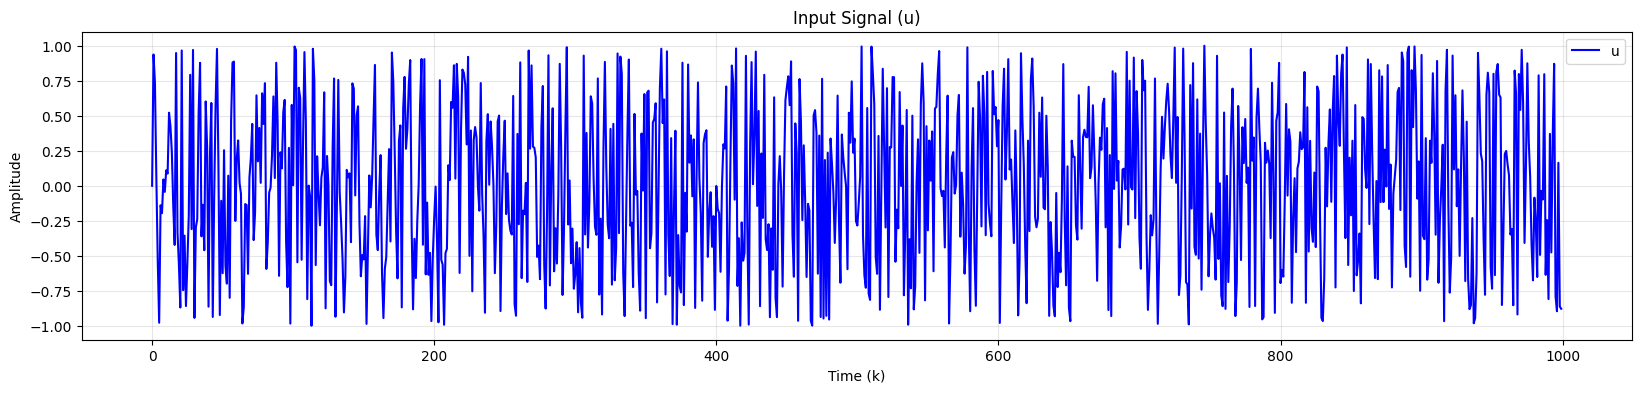

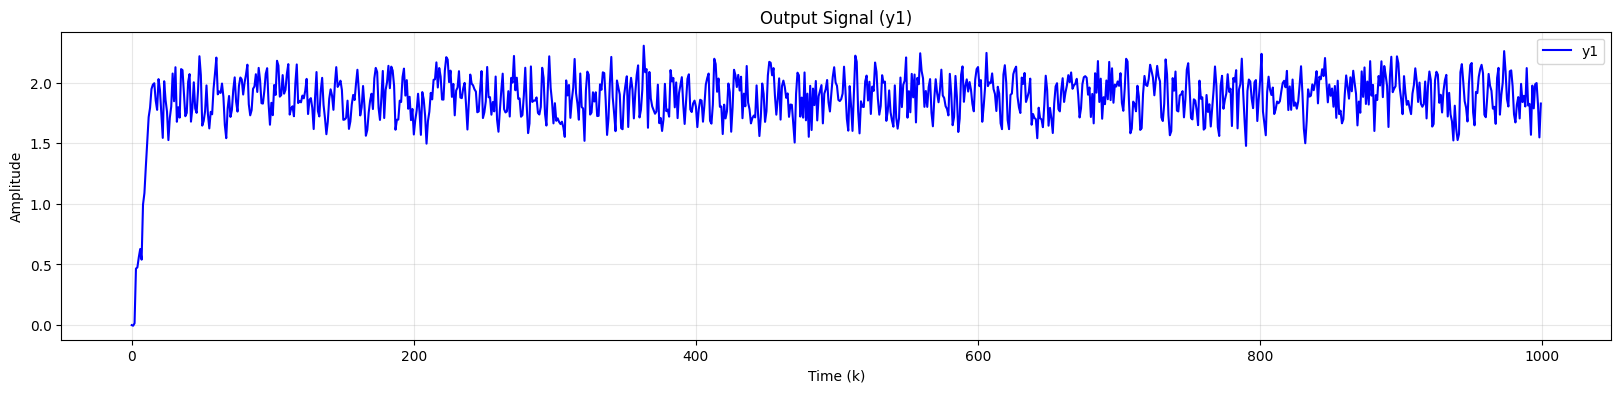

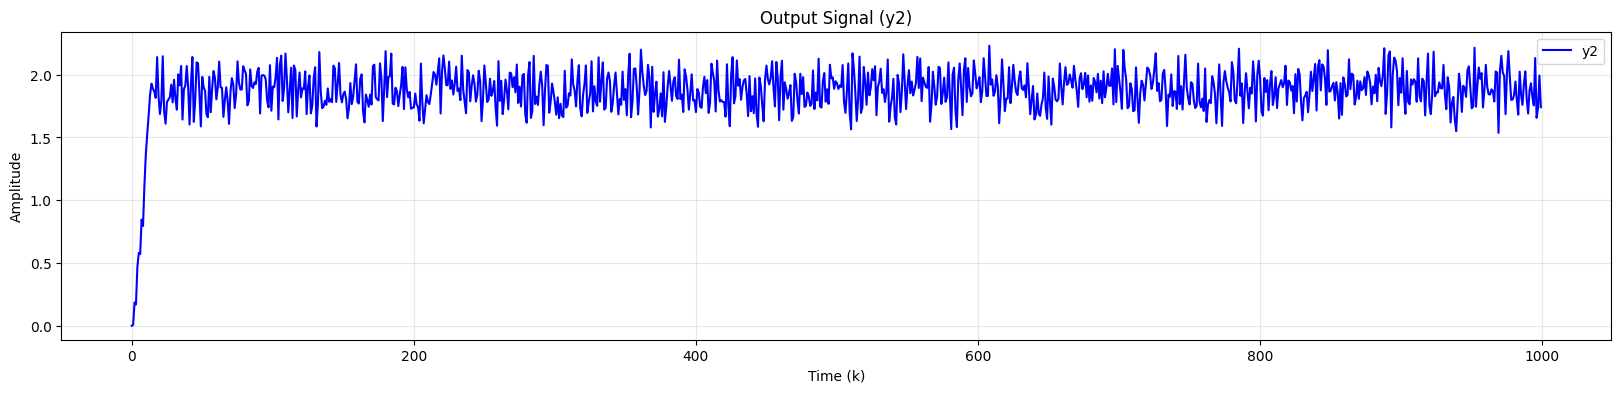

In [8]:
narx1_data = np.random.uniform(-1,1,N_narx1) # Generate N_narx1 random values uniformly distributed between -1 and 1

narx1_u = narx1_data.reshape(-1, 1) # Reshape 
narx1_u[0] = 0.0  # condition u(0) = 0 

narx1_y = NARX1(narx1_u, sigma) # Generate the output data using the NARX1 function

narx1_u_tr , narx1_u_ts = narx1_u[:split1], narx1_u[split1:] # We split the input data into training and testing sets
narx1_y_tr, narx1_y_ts = narx1_y[:split1], narx1_y[split1:]  # We split the output data into training and testing sets

plot_1(narx1_u, title="Input Signal (u)", label="u")
plot_1(narx1_y[:,0], title="Output Signal (y1)", label="y1")
plot_1(narx1_y[:,1], title="Output Signal (y2)", label="y2")

### NARX2 - two inputs, two outputs
$$y_1(k+1) = \frac{y_1(k)\,y_1(k-1)\,y_1(k-2)\,(y_1(k-2)-1)\,u_2(k-1) + u_2(k)}{1 + y_2(k-1)^2 + y_2(k-2)^2} + w_1$$

$$y_2(k+1) = \frac{y_2(k)\,y_2(k-1)\,y_2(k-2)\,(y_2(k-2)-1)\,u_1(k-1) + u_1(k)}{1 + y_1(k-1)^2 + y_1(k-2)^2} + w_2$$

During the simulation, we limit the outputs to the interval `[-5, 5]` to prevent numerical explosions whenever the denominator becomes very small.

In [9]:
def NARX2 (u1, u2, sigma = 0.01): ## two inputs = u1 and u2, two oputs = y1 and y2
    
    ## Starting variables 
    N = len(u1)
    w1 = np.random.normal(0, sigma, N)
    w2 = np.random.normal(0, sigma, N)
    y1,y2 = np.zeros(N) , np.zeros(N)

    ## NARX2 has a tendency to explode... there is something that can control this explosition 
    # np.clip function that can be used to limit the values of y1 and y2 to a certain range. 
    CLIP = 5.0 # This is a conservative clip to keep the simulation bounded. It can be adjusted based on the expected range of the outputs.

    def yy(arr, idx):
        return arr[idx] if idx >= 0 else 0.0

    def uu(arr, idx):
        return arr[idx] if idx >= 0 else 0.0

    for k in range(N - 1):
        y1_0, y1_1, y1_2 = yy(y1, k), yy(y1, k - 1), yy(y1, k - 2)
        y2_0, y2_1, y2_2 = yy(y2, k), yy(y2, k - 1), yy(y2, k - 2)

        num1 = y1_0 * y1_1 * y1_2 * (y1_2 - 1) * uu(u2, k - 1) + uu(u2, k)
        num2 = y2_0 * y2_1 * y2_2 * (y2_2 - 1) * uu(u1, k - 1) + uu(u1, k)

        den1 = 1.0 + y2_1 ** 2 + y2_2 ** 2
        den2 = 1.0 + y1_1 ** 2 + y1_2 ** 2

        y1[k + 1] = np.clip(num1 / den1 + w1[k + 1], -CLIP, CLIP)
        y2[k + 1] = np.clip(num2 / den2 + w2[k + 1], -CLIP, CLIP)
       

    return y1,y2
    # Return of this function
    # is a tuple of two 1D arrays (y1, y2) each of shape (N,)

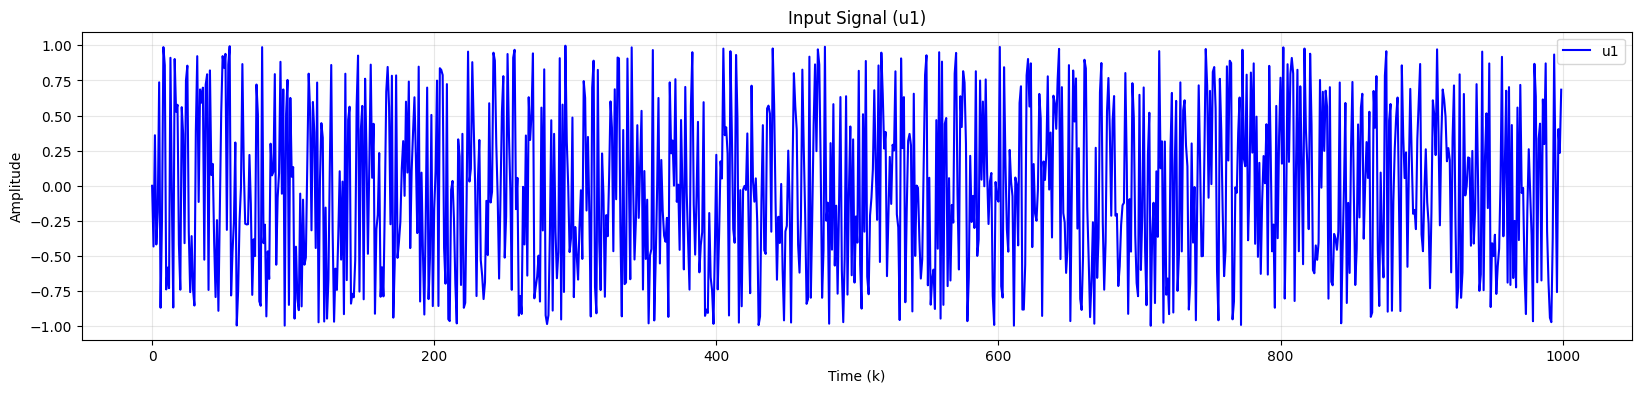

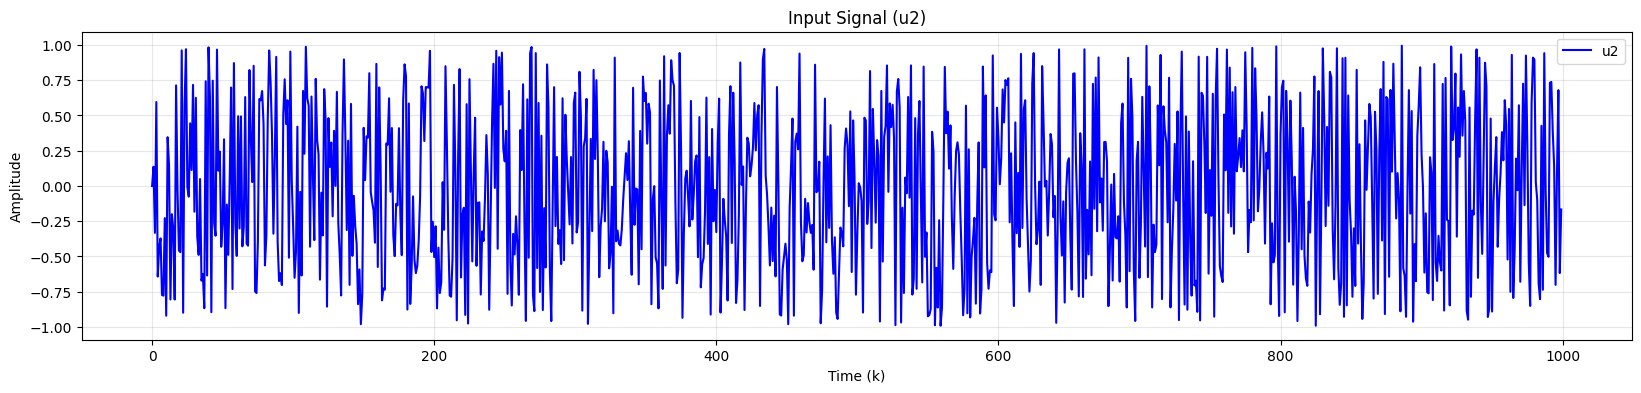

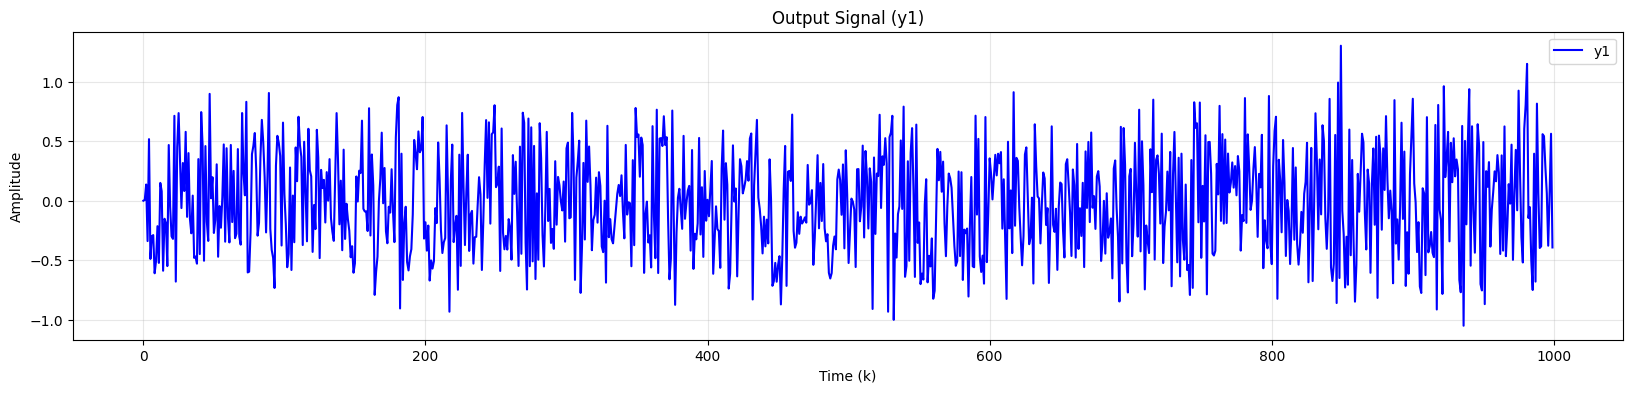

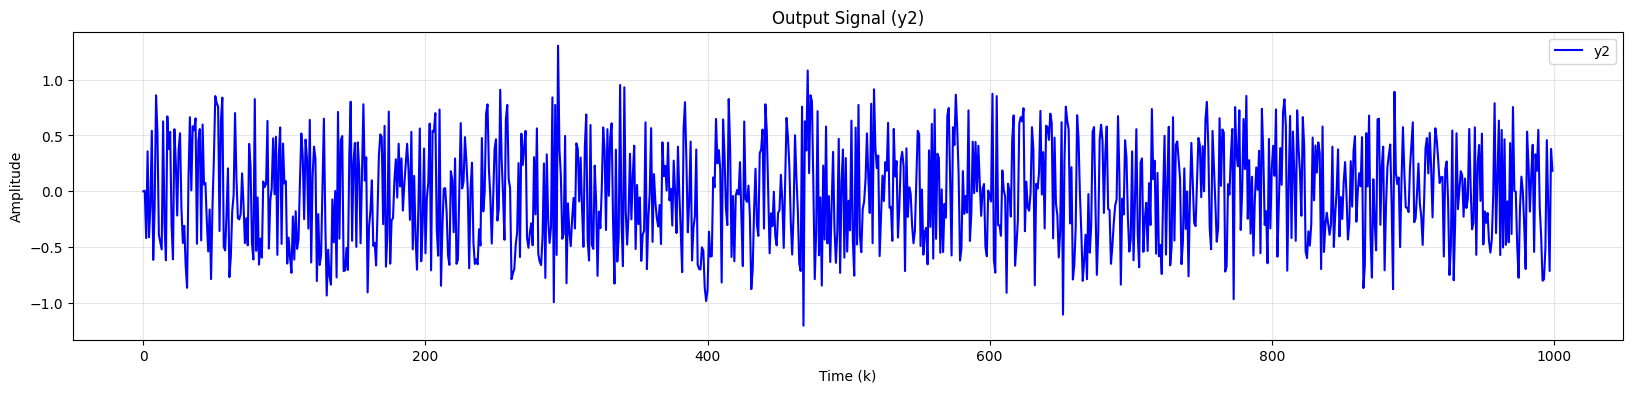

In [10]:
narx2_u1_data = np.random.uniform(-1.0, 1.0, N_narx2) # Generate N_narx2 random values uniformly distributed between -1 and 1 for u1
narx2_u2_data = np.random.uniform(-1.0, 1.0, N_narx2) # Generate N_narx2 random values uniformly distributed between -1 and 1 for u2
narx2_u1_data[0] = 0.0 # condition u1(0) = 0
narx2_u2_data[0] = 0.0 # condition u2(0) = 0
narx2_U = np.column_stack([narx2_u1_data, narx2_u2_data])   # shape (N, 2)
y1 ,y2 = NARX2(narx2_U[:,0], narx2_U[:,1], sigma)
narx2_Y = np.column_stack([y1, y2])                          # shape (N, 2)

narx2_U_tr, narx2_U_ts = narx2_U[:split2], narx2_U[split2:] # We split the input data into training and testing sets
narx2_y_tr, narx2_y_ts = narx2_Y[:split2], narx2_Y[split2:] # We split the output data into training and testing sets

plot_1(narx2_U[:, 0], title="Input Signal (u1)", label="u1")
plot_1(narx2_U[:, 1], title="Input Signal (u2)", label="u2")
plot_1(narx2_Y[:, 0], title="Output Signal (y1)", label="y1")
plot_1(narx2_Y[:, 1], title="Output Signal (y2)", label="y2")

## Task 2. Machine Learning Strategy

The main challenge of this projects was to design a solution that takes into account the NARX aspect of the problem and, more complex still, the long-term forecast horizon of over 1000 points, which mate it particularly important to find a solution for error accumulation.

To address this, our team broke the problem down into two sub-problems and looker for solutions to each.

**The MIMO (Multiple-Input Multiple-Output) aspect of the problem**
We had two options:

1. **Two independent models**: One model per output, each focused on predicting a single channel.
2. **Direct multiple output:**: A single model that learns both outputs at the same time. 

We chose the second option, because each output is dynamically coupled to the ohter; building two independent models would ignore the cross-channel information that the system itself uses to evolve.

### The 1000-steps long-horizon problem
For the long-horizon prediction we considered four strategies:

1. **Direct one-step (recursive)**
    The model outputs $$\hat{y}(k+1)$$, predicting one step at a time and requiring 1000 recursions. More importantly, error accumulates at every step. This option also requires separate models for $y_1$ and $y_2$, which conflicts with our MIMO decision above. Discarded.
    
2. **Direct multi-output**
    The model outputs $$\hat{y}(k+h)$$ for a fixed h, which means $H$ independent models, one per horizon. This avoids drift entirely, but incurs an $H-fold$ trainning cost and does not allow structure sharing across horizons. Each $h-cut$ also loses "signal", since the underlying time series is dependent and each cut discards teh dynamics between consecutive horizons. With a smaller horizon this could be a viable option, but with $H=1000$ it is not. Discarded
    
3. **MIMO (recursive, vector output)**
    The model outputs $$[\hat{y}_1(k+1),\hat{y}_2(k+1)]$$ from a shared lag regressor and requires 1000 recursions. It has the same drift behaviour as **direct one-step**, but the two channels share information through the common feature vector. The rollout cost is high, but for the structure of this project we judged the cost-vs-benefit trade-off to be acceptable.
    
4. **MISMO (block of $s$ steps)**
    The model outputs $$[\hat{y}(k+1),...,\hat{y}(k+s)]$$ using $$U(k+1:k+s)$$ as features. The rollout cost depends on $s: 1000/s$ blocks. The drift reduction is also controlled by $s$, with the trade-off that each block must commit to its $s$ steps at once. Our implementation follower the MISMO decomposition proposed by Ben Taieb et al. [1], adapted to the NARX setting, the feature vector is extended with the known future inputs $U(k+1:k+s), given by the project. The output block is reshaped to (s,2) to account for the two coupled output channels.
    

**Our decision: test both MIMO and MISMO**
We decided to implement both strategies and compare them. We discarded **direct one-step** (it is the s=1 case of **MISMO**) and direc multi-output (it ignores the shared dynamics between consecutive horizons and is computationally infeasible at $H=1000$).

- **Why MIMO?** Two outputs are predicted from the same lagged feature vector by two Ridge heads, and the rollout feeds predictions back one step at a time. It is simple, cheap to train, and give us an honest measurement of how badly recursive drift hurts on this problem.

- **Why MISMO?** This project give us the full test input sequence `U_ts` in advance, which means future inputs $U(k+1),...,U(k+s)$ are legitimate features. MISMO exploits this, it predicts a block of $s$ steps in one shot, reducing the number of recursive transitions from $1000$ to $1000/s$. We expected this to control the long-horizon error accumulation. 

- **Why both?** Curiosity.
Both strategies involve different trade-offs: from one side MIMO has lower-dimensional targets and more training iterations, while MISMO uses higher-dimensional targets but fewer iterations. Wheter this trade-off is worthwhile is an empirical question and depends on the final system to predict. We want to see which is better for this problem. 

Both strategies are evaluated on the two pilot systems (NARX1, NARX2) before being applied to the unkown system.

#### MIMO Stategy. Recursive Vector Output

To applied this strategy we need 


To implement this strategy we make 3 functions
1. build_mimo_features: were it pairs the feature/target rows 
2. train_mimo: first a sklearn model
2. recursive_rollout_mimo: 


In [11]:
def build_mimo_features(u, y, d, na, nb):
    # This function builds the feature matrix X and target matrix T for the MIMO NARX model.
        # u: Input data array of shape (N, n_in)
        # y: Output data array of shape (N, n_out)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # nb: Number of input lags to include (total lags = nb)

    u = np.asarray(u, dtype=float)
    y = np.asarray(y, dtype=float)

    horizon = max(d + na, nb)
    rows = []
    targets = []

    for k in range(horizon, len(y) - 1): 
        feats = []
        # Building features for the current time step k ------ 
        for lag in range(d, d + na + 1):
            feats.extend(y[k - lag].tolist())

        # Building features for the input lags -------
        for lag in range(0, nb + 1):
            feats.extend(u[k - lag].tolist())
    
        rows.append(feats)
        
        # Building targets for the next time step k+1 ------
        targets.append(y[k + 1])

    if not rows:
        return np.empty((0, 0)), np.empty((0, y.shape[1]))

    return np.asarray(rows), np.asarray(targets)
    # The return of this function is:
    # X: A 2D array of shape (N_samples, n_features) containing the features for each time step k
    # T: A 2D array of shape (N_samples, n_out) containing the target outputs for time step k+1

In [12]:
def train_mimo(X_train, Y_train, alpha=1.0):
    # This function trains two separate Ridge regression models for the two output variables in a MIMO NARX setup.
        # X_train: A 2D array of shape (N_samples, n_features)
        # Y_train: A 2D array of shape (N_samples, 2) containing the target outputs for each time step k
        # alpha: Regularization strength for Ridge regression

    model_y1 = make_pipeline(StandardScaler(), Ridge(alpha=alpha))
    model_y2 = make_pipeline(StandardScaler(), Ridge(alpha=alpha))

    model_y1.fit(X_train, Y_train[:, 0])
    model_y2.fit(X_train, Y_train[:, 1])
    
    return model_y1, model_y2
    # The return of this function is:
    # model_y1: A trained Ridge regression model for predicting the first output variable (y1)
    # model_y2: A trained Ridge regression model for predicting the second output variable (y2)

In [13]:
def recursive_rollout_mimo(U, model_y1, model_y2, d, na, nb, y_prefix=None):
    # This function performs a recursive rollout to predict the output sequence Y_hat based on the input sequence U and the trained models for y1 and y2.
        # U: Input data array of shape (N, n_in)
        # model_y1: Trained regression model for predicting y1
        # model_y2: Trained regression model for predicting y2
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # nb: Number of input lags to include (total lags = nb)
        # y_prefix: Optional array of shape (prefix_len, n_out) containing known output values for the initial time steps (if available)

    U = np.asarray(U, dtype=float)
    n_steps, n_inputs = U.shape
    Y_hat = np.zeros((n_steps, 2), dtype=float)

    start = 0
    if y_prefix is not None and len(y_prefix) > 0: # If there ir a y_prefix we used to initialize the first few values of Y_hat with the known output values
        prefix_len = min(len(y_prefix), n_steps)
        Y_hat[:prefix_len] = y_prefix[:prefix_len]
        start = prefix_len

    for k in range(start, n_steps):
        feats = []

        for lag in range(d, d + na + 1): 
            idx = (k - 1) - lag
            feats.extend(Y_hat[idx].tolist() if idx >= 0 else [0.0, 0.0])

        for lag in range(0, nb + 1):
            idx = (k - 1) - lag
            feats.extend(U[idx].tolist() if idx >= 0 else [0.0] * n_inputs)

        xk = np.asarray(feats, dtype=float).reshape(1, -1)
        Y_hat[k, 0] = model_y1.predict(xk)[0] # We predict y1 for the current time step k using model_y1 and the feature vector xk
        Y_hat[k, 1] = model_y2.predict(xk)[0] # We predict y2 for the current time step k using model_y2 and the feature vector xk

    return Y_hat
    # The return of this function is:
    # Y_hat: A 2D array of shape (N_ts, n_out) containing the predicted output values for the test input data.

In [14]:
def build_masks(n_samples, horizon, val_ratio=0.30):
    # This function builds boolean masks for training and validation sets based on the total number of samples, 
    # the horizon (minimum lag), and the validation ratio.
        # n_samples: Total number of samples in the dataset
        # horizon: The minimum lag (d + na or nb) that determines the valid time steps for training and validation
        # val_ratio: The proportion of the dataset to be used for validation
        
    split_idx  = int(n_samples * (1.0 - val_ratio))
    target_idx = np.arange(horizon + 1, n_samples)
    train_mask = target_idx < split_idx
    val_mask   = ~train_mask
    return split_idx, target_idx, train_mask, val_mask
    # This function returns:
    # split_idx: The index at which the data is split into training and validation sets
    # target_idx: An array of indices corresponding to the valid time steps for training and validation
    # train_mask: A boolean array where True indicates the indices used for training
    # val_mask: A boolean array where True indicates the indices used for validation

#### MISMO Strategy. Prediction in block of `s` steps
To applied this strategy we need two vectors:

1.**The Feature Vector** 
When applied to the training phase, and used for any base rate `k`:
$$X(k) = [Y(k-d-na),...,Y(k-d)]\;||\;[U(k+1),...,U(k+s)]$$

were the first part if the output lag history ($n_a+1 vector$) and the second the future input (s vector)

2.**Target vector**.
The next `s` outputs
$$T(k) = [Y(k+1), Y(k+2),...,Y(k+s)]$$

To implement this strategy we make 3 functions
1. build_mismo_features: were it pairs the feature/target rows 
2. train_mismo: fits a sklearn model
3. mismo_rollout: is in charge of the chains block predictions to produce the full-lenght prediction, the $\hat{y}$

In [15]:
def build_mismo_features(U, Y, d, na, s, show=False):
    # This function builds the feature matrix X and target matrix T for the MISMO NARX model.
        # U: Input data array of shape (N, n_in)
        # Y: Output data array of shape (N, n_out)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # s: Number of future steps to predict (target horizon)
        # show: Boolean flag to display the feature building process
    U, Y = np.asarray(U, float), np.asarray(Y, float)
    N, n_in= U.shape
    
    X_rows, T_rows = [], []
    
    for k in range(d + na, N - s):
        ## Building the features ---------
        if(show):
            print(f"\n--Building features for row {k}--")
        feat = [] 
        for lag in range(d, d + na + 1): # loop from d to d+na (inclusive) to get the lags for the output features
            feat.extend(Y[k - lag])
            if(show):
                print(f"    - Adding Y(k-{lag}) to features: {Y[k - lag]}")

        for h in range(1, s + 1): # loop from 1 to s (inclusive) to get the future steps for the input features
            feat.extend(U[k + h])
            if(show):
                print(f"    - Adding U(k+{h}) to features: {U[k + h]}")
        X_rows.append(feat)
        if(show):
            print(f"  Built features for row {k}: {feat}")
        tgt = []

        ## Building the target ---------
        for h in range(1, s + 1): # loop from 1 to s (inclusive) to get the future steps for the target outputs
            tgt.extend(Y[k + h])
            if(show):
                print(f"    - Adding Y(k+{h}) to target: {Y[k + h]}")
        T_rows.append(tgt)

    return np.array(X_rows), np.array(T_rows)
    # The return of this function is:
    # X: A 2D array of shape (N_samples, n_features) containing the features for each time step k
    # T: A 2D array of shape (N_samples, n_out * s) containing the target outputs for time steps k+1 to k+s

In [16]:
def train_mismo(U_tr, Y_tr, d, na, s, model = None,show=False):
    # This function trains a MISMO NARX model using the provided training data and parameters.
        # U_tr: Training input data array of shape (N_tr, n_in)
        # Y_tr: Training output data array of shape (N_tr, n_out)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # s: Number of future steps to predict (target horizon)
        # model: Optional regression model to use (default is RidgeCV with specified alphas)
    if show:
         print(f"\n - Training MISMO with d={d}, na={na}, s={s}...")
         print("   Building features...")

    X, T = build_mismo_features(U_tr, Y_tr, d, na, s, show=show) # Build the feature matrix X and the target matrix T

    if model is None:
        model = RidgeCV(alphas=ALPHAS) 

    pipeline = make_pipeline(StandardScaler(), model) # Create a pipeline that standardizes the features and then applies the regression model
    pipeline.fit(X, T)

    return pipeline
    # The return of this functions is:
    # A trained regression model (pipeline) that can be used to make predictions on new data.

In [17]:
def mismo_rollout(model, U_test, d, na, s, y_prefix=None):
    # This function performs a rollout using the trained MISMO NARX model to predict future outputs based on the test input data.
        # model: Trained regression model (pipeline) to use for predictions
        # U_test: Test input data array of shape (N_ts, n_in)
        # d: Minimum lag for output features
        # na: Number of output lags to include (total lags = d + na)
        # s: Number of future steps to predict (target horizon)
        # y_prefix: Optional array of initial output values to seed the rollout
    Nts = len(U_test) 
    n_in = U_test.shape[1] # Number of input features NARX1= 1 NARX2= 2 
    Y_hat = np.zeros((Nts, 2)) # y hat array

    buf_len = d + na + 1
    buf = np.zeros((buf_len, 2))
    
    if y_prefix is not None: # If a prefix of output values is provided, we use it to initialize the buffer for the rollout
        take = min(buf_len, len(y_prefix))
        buf[-take:] = y_prefix[-take:]

    k = 0
    while k < Nts: # We predict the block of future outputs in steps of size s until we have predicted for all test samples
        block = min(s, Nts - k)

        feat = []
        for lag in range(d, d + na + 1): # loop from d to d+na (inclusive) to get the lags for the output features
            feat.extend(buf[buf_len - 1 - lag]) # We take the lagged output features from the buffer

        for h in range(1, s + 1): # loop from 1 to s (inclusive) to get the future steps for the input features
            ui = k + h - 1
            feat.extend(U_test[ui] if ui < Nts else np.zeros(n_in))

        pred_flat = model.predict(np.array(feat, float).reshape(1, -1))[0] 
        pred_block = pred_flat.reshape(s, 2) 

        Y_hat[k:k + block] = pred_block[:block]

        for step in range(block): # After predicting the block of future outputs, we need to update the buffer with the new predictions for the next iteration
            buf = np.roll(buf, -1, axis=0)
            buf[-1] = Y_hat[k + step]

        k += block

    return Y_hat
    # The return of this function is:
    # Y_hat: A 2D array of shape (N_ts, n_out) containing the predicted output values for the test input data.

### Parameter Selection: finding $d$, $n_a$ and $n_b$ or $s$
The MIMO and MISMO model have three structural hyperparameters. We slect them in two stages:

1. Cross Correlation for `d` 
    We compute the input-output cross-correlation $r_{uy}(\tau)$ at lags $\tau = 0,\;...\;,maxLag$ and select the first peaks. If the system has a delay $d$, the strongest correlation between $u(k-\tau)$ and $y(k)$ should appear at $\tau=d$. We retain a set of $d$ candidates (top 3). To get the optimal $d$

2. Grid search over ($d$ , $n_a$, $n_b$ / $s$).
We iterate over `d` using the candidates from the previous step. $n_a$ over $[0,...,10]$ and $s$ over $[1,5,10,20,50,100,200]$ For each combination, we trina the model on the training set and evaluate it using **rollout NMSE** on the held-out validation set.

#### Estimate `d` with cross-correlation
For each input $u_j$ we calculate the cross-correlation between $u_j$ and each output $y_i$ in the lags `0,...,maxLags` ; average the result across all input/output pairs, and identify the lags at which the correlation reaches its maximum value. The set of candidates obtained is the union of the N highest peaks from all pairs, with a maximum limit of `max_d`

In [18]:
def cross_correlation(y, u, max_lag=40):
    # This function computes the cross-correlation between the output signal y and the input signal u for a range of lags from -max_lag to max_lag.
        # y: Output data array of shape (N, n_out)
        # u: Input data array of shape (N, n_in)
        # max_lag: Maximum lag to consider for the cross-correlation

    y_c = y - y.mean()
    u_c = u - u.mean()

    full_corr = np.correlate(y_c, u_c, mode='full') # Compute the full cross-correlation between the centered output and input signals
    N = len(y)
    lags = np.arange(-(N - 1), N)

    norm = np.sqrt(np.sum(y_c**2) * np.sum(u_c**2)) # Compute the normalization factor based on the energy of the centered signals
    full_corr = full_corr / (norm + 1e-12)

    mask = (lags >= -max_lag) & (lags <= max_lag)
    return lags[mask], full_corr[mask]
    # The return of this function is two arrays: 
    # the first contains the lags from -max_lag to max_lag
    # the second contains the corresponding normalized cross-correlation values for those lags.

In [83]:
def estimate_d_candidates(Utr,Ytr,max_lag=40,max_d=10):
    # This functions estimates candidate values for the minimum lag d in the NARX model 
    # by analyzing the cross-correlation between the input and output signals in the training data.
        # Utr: Training input data array of shape (N_tr, n_in)
        # Ytr: Training output data array of shape (N_tr, n_out)
        # max_lag: Maximum lag to consider for the cross-correlation analysis
        # max_d: Maximum candidate value for d to consider based on the cross-correlation peaks

    nu , ny = Utr.shape[1], Ytr.shape[1]
    peak_lags = {}
    
    for i in range(nu): # for each input variable 
        for j in range(ny): # for each output variable
            lags, corr = cross_correlation(Ytr[:, j], Utr[:, i], max_lag=max_lag)
            pos_mask = lags >= 0
            peak_pos = int(lags[pos_mask][np.argmax(np.abs(corr[pos_mask]))]) 
            peak_lags[(i, j)] = peak_pos

    print('\nPositive-lag peaks per (input, output) pair:')
    for (i, j), lag in peak_lags.items(): # Print the identified peak lag for each input-output pair
        print(f'  u{i+1} -> y{j+1}: peak at lag {lag}')

    peak_values = np.array(list(peak_lags.values()),dtype=int)
    d_min = int(np.min(peak_values))
    d_med = int(np.median(peak_values))

    baseline = set(range(0, max_d)) # A baseline set of candidate d values from 0 to 5
    around_med = set(range(max(0, d_med - 2), d_med + 4)) #
    around_min = set(range(max(0, d_min - 1), d_min + 3))

    d_candidates = sorted(d for d in (baseline | around_med | around_min) if 0 <= d <= max_d)
    print(f'\nCCF min peak: {d_min}, median peak: {d_med}')
    print(f'\nWill test d in {d_candidates} during grid search')

    return d_candidates, peak_lags
    # The return of this function is:
    # d_candidates: A sorted list of candidate values for the minimum lag d to consider in the NARX model based on the cross-correlation analysis
    # peak_lags: A dictionary containing the identified peak lags for each input-output pair from the cross-correlation analysis.

##### Results

In [20]:
print("\n_______ Estimating d candidates for NARX1...")
d1, peaks1 = estimate_d_candidates(narx1_u_tr, narx1_y_tr, max_lag=40,max_d=8)

print("\n_______ Estimating d candidates for NARX2...")
d2, peaks2 = estimate_d_candidates(narx2_U_tr, narx2_y_tr, max_lag=40,max_d=8)


_______ Estimating d candidates for NARX1...

Positive-lag peaks per (input, output) pair:
  u1 -> y1: peak at lag 2
  u1 -> y2: peak at lag 1

CCF min peak: 1, median peak: 1

Will test d in [0, 1, 2, 3, 4] during grid search

_______ Estimating d candidates for NARX2...

Positive-lag peaks per (input, output) pair:
  u1 -> y1: peak at lag 2
  u1 -> y2: peak at lag 1
  u2 -> y1: peak at lag 1
  u2 -> y2: peak at lag 0

CCF min peak: 0, median peak: 1

Will test d in [0, 1, 2, 3, 4] during grid search


#### Grid Search over `(d, n_a, n_b or s)`
In this section, since we have two strategies, we use two grid-search functions. For the MIMO strategy, we will search for the best values of d, na, and nb, and for the MISMO strategy, we will search for the best values of d, na, and s. Each combination trains a RidgeCV-based MISMO or MIMO model on the training partitions, applies it to the validation partitions, and records the NMSE result. The combination with the lowest validation NMSE is selected. 

Note: Since we will analyze |d| × 11 × 11 combinations for MIMO and |d| × 11 × 8 combinations for MISMO, this may take some time.
Each result is saved in `best_n1` and `best_n2` and reused throughout the notebook.

In [ ]:
## MIMO grid NARX1 
MIMO_grid1 = {    
    'd':  d1,         
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'nb': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
}

# MIMO grid NARX2
MIMO_grid2 = {
    'd':  d2,         
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    'nb': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
}

# MISMO grid NARX1
grid1_MISMO = {
    'd': d1,
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    's':  [1, 5, 10, 20, 50, 100, 200, 500,1000]
}

# MISMO grid NARX2
grid2_MISMO = {
    'd': d2,
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    's':  [1, 5, 10, 20, 50, 100, 200, 500,1000]
}

In [22]:
def grid_search_mimo(U, Y, grid, val_ratio=0.30, alpha=1.0):
    # This function performs a grid search over the specified hyperparameters for the MIMO NARX model and evaluates the performance on a validation set.
        # U: Input data array of shape (N, n_in)
        # Y: Output data array of shape (N, n_out)
        # grid: A dictionary specifying the hyperparameter values to search over (keys should be 'd', 'na', 'nb')
        # val_ratio: Proportion of the data to use for validation (default is 0.30)
        # alpha: Regularization strength for Ridge regression (default is 1.0)
        
    rows = []

    for params in ParameterGrid(grid):
        d  = int(params['d'])
        na = int(params['na'])
        nb = int(params['nb'])

        X, Y_next = build_mimo_features(U, Y, d=d, na=na, nb=nb)
        if X.size == 0:
            continue

        horizon = max(d + na, nb)
        split_idx, _, train_mask, val_mask = build_masks(len(Y), horizon, val_ratio)

        if train_mask.sum() < 30 or val_mask.sum() < 30:
            continue

        # Train on train portion only
        model_y1, model_y2 = train_mimo(X[train_mask], Y_next[train_mask], alpha)

        Y_val_pred_os = np.column_stack([
            model_y1.predict(X[val_mask]),
            model_y2.predict(X[val_mask]),
        ])
        nmse_os = float(nmse(Y_next[val_mask], Y_val_pred_os))
        rmse_os = float(rmse(Y_next[val_mask], Y_val_pred_os))

        
        Y_roll = recursive_rollout_mimo(
            U, model_y1, model_y2,
            d=d, na=na, nb=nb,
            y_prefix=None,
        )
        Y_val_roll  = Y_roll[split_idx:]
        Y_val_true  = Y[split_idx:]
        nmse_roll = float(nmse(Y_val_true, Y_val_roll))
        rmse_roll = float(rmse(Y_val_true, Y_val_roll))

        rows.append({
            'd': d, 'na': na, 'nb': nb,
            'n_features': int(X.shape[1]),
            'n_train':    int(train_mask.sum()),
            'n_val':      int(val_mask.sum()),
            'nmse_os':    nmse_os,
            'rmse_os':    rmse_os,
            'nmse_roll':  nmse_roll,
            'rmse_roll':  rmse_roll,
        })

    if not rows:
        return {}, pd.DataFrame()

    # Sort by rollout NMSE (the metric the project actually scores on)
    df = pd.DataFrame(rows).sort_values(['nmse_roll', 'nmse_os']).reset_index(drop=True)

    print(f"\n___ Grid (d, na, nb) — sorted by rollout NMSE ___")
    print(df.to_string(index=False))

    best_row = df.iloc[0]
    best_params = {
        'd':  int(best_row['d']),
        'na': int(best_row['na']),
        'nb': int(best_row['nb']),
    }

    print(f"\nBest combination: d={best_params['d']}, "
          f"na={best_params['na']}, nb={best_params['nb']}\n"
          f"  rollout NMSE  = {best_row['nmse_roll']:.4f}\n"
          f"  one-step NMSE = {best_row['nmse_os']:.4f}\n"
          f"  drift ratio   = {best_row['nmse_roll'] / max(best_row['nmse_os'], 1e-12):.1f}x")

    return best_params, df
    # This function returns:
    # best_params: A dictionary containing the best combination of hyperparameters (d, na, nb) based on the validation performance
    # df: A DataFrame containing the results of the grid search for all combinations of hyperparameters, sorted by validation performance.

In [23]:
def grid_search_mismo(U_tr, Y_tr, grid, val_ratio=0.30, label=""):
    # This function performs a grid search over the specified hyperparameters for the MISMO NARX model 
    # and evaluates the performance on the test set.
        # U_tr: Training input data array of shape (N, n_in)
        # Y_tr: Training output data array of shape (N, n_out)
        # U_ts: Test input data array of shape (N, n_in)
        # Y_ts: Test output data array of shape (N, n_out)
        # grid: A dictionary specifying the hyperparameter values to search over (keys should be 'd', 'na', 's')
        # y_prefix: Optional prefix for the output variable names
        # label: Optional label for the grid search (default is "")

    U_tr = np.asarray(U_tr, dtype=float)
    Y_tr = np.asarray(Y_tr, dtype=float)
    N = len(U_tr)
    split = int(N * (1.0 - val_ratio))

    U_sub_tr, U_sub_val = U_tr[:split], U_tr[split:]
    Y_sub_tr, Y_sub_val = Y_tr[:split], Y_tr[split:]

    rows = []

    for params in ParameterGrid(grid):
        d = int(params['d'])
        na = int(params['na'])
        s = int(params['s'])

        if len(U_sub_val) < s or len(U_sub_tr) <= d + na + s:
                    continue
        
        mod = train_mismo(U_sub_tr, Y_sub_tr, d, na, s)  # We train the MISMO model with the current combination of hyperparameters (d, na, s) using the training data (U_sub_tr, Y_sub_tr)
        yhat = mismo_rollout(mod, U_sub_val, d, na, s, y_prefix=None) # We generate predictions for the validation set (U_sub_val) using the trained MISMO model and the current hyperparameters (d, na, s)

        rows.append({
            'd': d,
            'na': na,
            's': s,
            'nmse': nmse(Y_sub_val, yhat),
            'rmse': rmse(Y_sub_val, yhat)
        })
    
    if not rows:
        return {}, pd.DataFrame()
    
    # We create a DataFrame with the results of the grid search and sort it by nmse and rmse to identify the best combination of hyperparameters
    df = pd.DataFrame(rows).sort_values(['nmse','rmse']).reset_index(drop=True)
    
    print(f"\n___ Grid (d, na, s) __ {label} ___")
    print(df.to_string(index=False))

    best_row = df.iloc[0]
    best_params = {
        'd':  int(best_row['d']),
        'na': int(best_row['na']),
        's':  int(best_row['s']),
    }
    print(f"\nBest Combination: d={best_params['d']}, "
          f"na={best_params['na']}, s={best_params['s']}  "
          f"(nmse={best_row['nmse']})")

    return best_params, df
    # This function returns:
    # best_params: A dictionary containing the best combination of hyperparameters (d, na, s) based on the test performance
    # df: A DataFrame containing the results of the grid search for all combinations of hyperparameters, sorted by test performance.

##### Results MIMO

In [24]:
print("Best Parameters for NARX1 MIMO:")
best_n1_mimo, df_n1_mimo = grid_search_mimo(narx1_u, narx1_y, MIMO_grid1)

Best Parameters for NARX1 MIMO:

___ Grid (d, na, nb) — sorted by rollout NMSE ___
 d  na  nb  n_features  n_train  n_val  nmse_os  rmse_os    nmse_roll    rmse_roll
 1   2   6          13      693    300 0.013210 0.017584 1.995003e-02 2.160940e-02
 0   2   6          13      693    300 0.014552 0.018456 1.998869e-02 2.163033e-02
 0   3   6          15      693    300 0.014030 0.018122 2.000383e-02 2.163852e-02
 0   2   8          15      691    300 0.013287 0.017635 2.007683e-02 2.167796e-02
 1   2   5          12      694    300 0.013205 0.017581 2.011782e-02 2.170008e-02
 0   2   5          12      694    300 0.014606 0.018490 2.012650e-02 2.170476e-02
 1   1   8          13      691    300 0.013089 0.017504 2.012905e-02 2.170614e-02
 0   2   9          16      690    300 0.012543 0.017135 2.014801e-02 2.171636e-02
 1   1   9          14      690    300 0.013032 0.017466 2.019585e-02 2.174212e-02
 0   2   7          14      692    300 0.014304 0.018298 2.023565e-02 2.176354e-02
 1  

In [25]:
print("Best Parameters for NARX2 MIMO:")
best_n2_mimo, df_n2_mimo = grid_search_mimo(narx2_U, narx2_Y, MIMO_grid2)

Best Parameters for NARX2 MIMO:

___ Grid (d, na, nb) — sorted by rollout NMSE ___
 d  na  nb  n_features  n_train  n_val  nmse_os  rmse_os  nmse_roll  rmse_roll
 1   0   0           4      698    300 0.062588 0.113925   0.063021   0.114319
 1   1   0           6      697    300 0.062596 0.113933   0.063182   0.114465
 1   2   0           8      696    300 0.062826 0.114142   0.063399   0.114662
 1   4   0          12      694    300 0.062932 0.114238   0.063403   0.114665
 1   3   0          10      695    300 0.062898 0.114207   0.063420   0.114680
 1   0   1           6      698    300 0.063206 0.114487   0.063654   0.114891
 0   2   3          14      696    300 0.062894 0.114204   0.063664   0.114901
 0   1   1           8      698    300 0.063547 0.114795   0.063679   0.114914
 0   0   2           8      697    300 0.064020 0.115222   0.063688   0.114923
 1   1   3          12      696    300 0.062544 0.113886   0.063695   0.114929
 2   0   3          10      696    300 0.063309 

##### Results MISMO

In [26]:
## This code take some time to run, be patient.
print("Best Parameters for NARX1 MISMO:")
best_n1_mismo, df_n1_mismo = grid_search_mismo(narx1_u_tr, narx1_y_tr,grid1_MISMO, label="NARX1")

Best Parameters for NARX1 MISMO:

___ Grid (d, na, s) __ NARX1 ___
 d  na   s          nmse      rmse
 3   8 100      0.056554  0.034730
 3   7 100      0.056567  0.034734
 3   9 100      0.060697  0.035980
 3   6 100      0.064797  0.037175
 4   6 100      0.065539  0.037387
 3   8  50      0.066304  0.037605
 3  10 100      0.067880  0.038049
 4   7 100      0.068071  0.038102
 3   7  50      0.068097  0.038110
 3   9  50      0.070768  0.038850
 4   5 100      0.073270  0.039531
 3  10  50      0.074212  0.039784
 4   8 100      0.075501  0.040128
 4   6  50      0.078938  0.041031
 4   7  50      0.080277  0.041378
 3   6  50      0.081194  0.041613
 4   8  50      0.084195  0.042375
 4  10 100      0.091109  0.044081
 4   5  50      0.091415  0.044155
 4   4 100      0.092089  0.044318
 4   9 100      0.092246  0.044355
 4   9  50      0.092997  0.044536
 3   5 100      0.093498  0.044655
 4  10  50      0.096454  0.045356
 4   4 200      0.101774  0.046590
 3   6 200      0.10229

In [27]:
## This code take some time to run, be patient.
print("Best Parameters for NARX2 MISMO:")
best_n2_mismo, df_n2_mismo = grid_search_mismo(narx2_U_tr, narx2_y_tr,grid2_MISMO, label="NARX2")

Best Parameters for NARX2 MISMO:

___ Grid (d, na, s) __ NARX2 ___
 d  na   s     nmse     rmse
 1   5  20 0.092806 0.132932
 0   1  50 0.093412 0.133366
 0   6  20 0.093448 0.133391
 1   4  20 0.093626 0.133518
 3   3  20 0.093726 0.133590
 1   3  20 0.093775 0.133625
 2   4  20 0.094176 0.133910
 0   5  20 0.094236 0.133952
 0   0  50 0.094249 0.133962
 0   4  20 0.094271 0.133978
 3   0  20 0.094291 0.133992
 3   2  20 0.094382 0.134056
 1   2  20 0.094507 0.134145
 3   1  20 0.094559 0.134182
 2   3  20 0.094864 0.134398
 1   0  50 0.094880 0.134410
 4   2  20 0.094887 0.134414
 2   2  20 0.094986 0.134484
 1   0  20 0.095077 0.134549
 0   3  20 0.095125 0.134583
 4   1  20 0.095670 0.134968
 4   0  20 0.095674 0.134971
 2   1  20 0.095801 0.135060
 1   1  20 0.095803 0.135062
 0   2  50 0.096128 0.135291
 2   0  20 0.096137 0.135297
 0   1  20 0.096376 0.135465
 0   2  20 0.096411 0.135490
 0   0  20 0.096678 0.135677
 0   3  50 0.097037 0.135928
 1   1  50 0.097404 0.136185
 1   

### End-to-end test on Pilots
Once the parameters for both strategies have been selected, we train the models on the training sets and evaluate the results on the test set. This is the final check before moving on to the model comparison; this is where we would make an initial assessment of the effectiveness of the previous strategies. 

#### MIMO Results
##### NARX 1


NARX 1 | MIMO | One-step ahead validation NMSE: 0.0132, RMSE: 0.0176


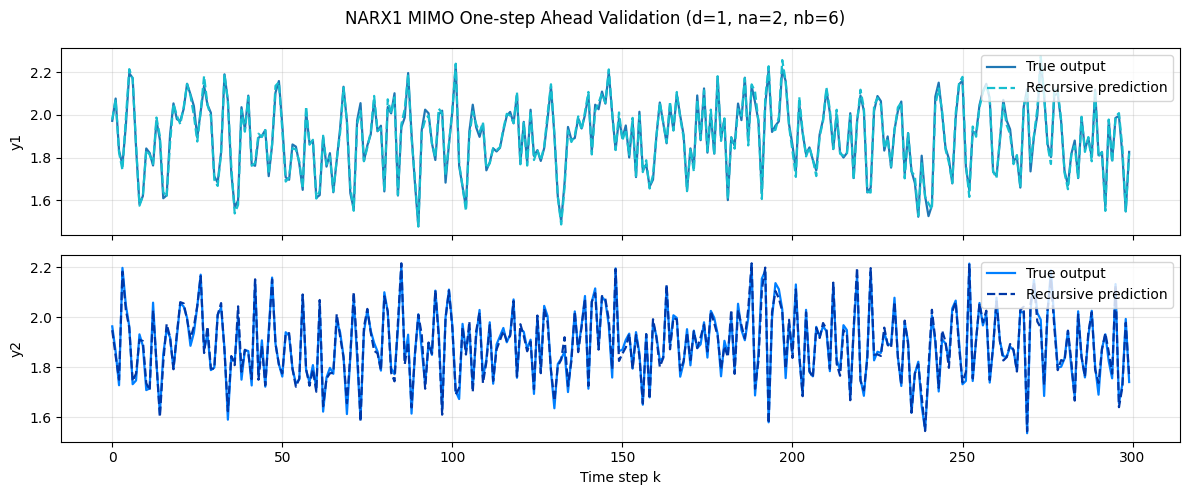

In [28]:
horizon_narx1 = max(best_n1_mimo['d'] + best_n1_mimo['na'], best_n1_mimo['nb'])
X_narx1_tr, Y_narx1_tr = build_mimo_features(narx1_u_tr, narx1_y_tr,d=best_n1_mimo['d'], na=best_n1_mimo['na'], nb=best_n1_mimo['nb'])
model_y1, model_y2 = train_mimo(X_narx1_tr, Y_narx1_tr, alpha=1.0)
#print(f'Trained on {X_narx1_tr.shape[0]} samples from the first 70% of the series.')

X_narx1_full, Y_narx1_full_tgt = build_mimo_features(narx1_u, narx1_y, d=best_n1_mimo['d'], na=best_n1_mimo['na'], nb=best_n1_mimo['nb'])
target_k_plus_1    = np.arange(horizon_narx1 + 1, len(narx1_y))
val_mask           = target_k_plus_1 >= split1

Y_val_one_step = np.column_stack([
    model_y1.predict(X_narx1_full[val_mask]),
    model_y2.predict(X_narx1_full[val_mask]),
])
Y_val_true_os = Y_narx1_full_tgt[val_mask]

nmse_os = nmse(Y_val_true_os, Y_val_one_step)
rmse_os = rmse(Y_val_true_os, Y_val_one_step)
print(f"\nNARX 1 | MIMO | One-step ahead validation NMSE: {nmse_os:.4f}, RMSE: {rmse_os:.4f}")
plot_comparison(Y_val_true_os, Y_val_one_step, title=f"NARX1 MIMO One-step Ahead Validation (d={best_n1_mimo['d']}, na={best_n1_mimo['na']}, nb={best_n1_mimo['nb']})")


NARX 1 | MIMO | Recursive validation NMSE: 0.0190, RMSE: 0.0211


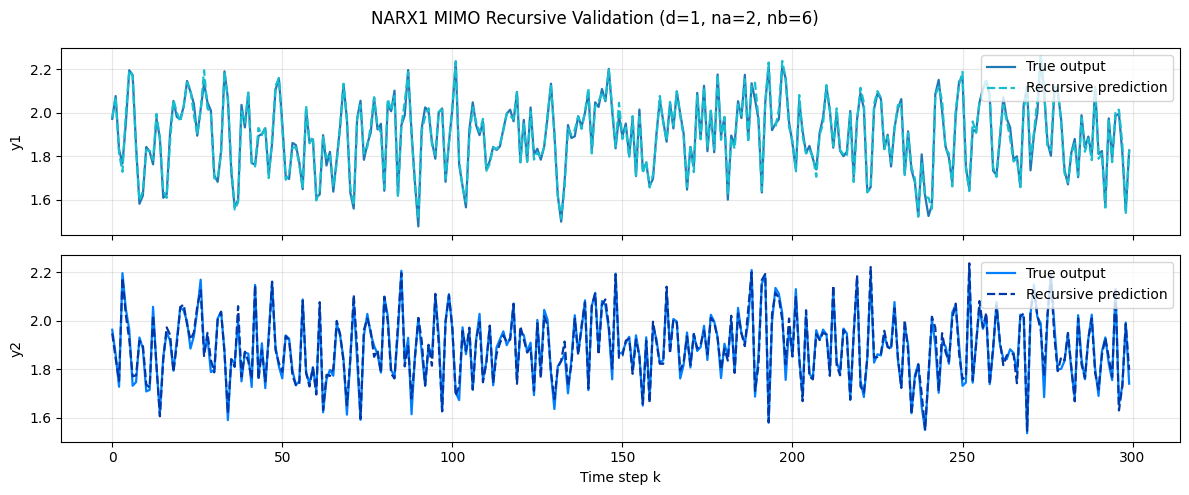

In [29]:
Y_roll = recursive_rollout_mimo(narx1_u, model_y1, model_y2,
                                d=best_n1_mimo['d'], na=best_n1_mimo['na'], nb=best_n1_mimo['nb'],
                                y_prefix=narx1_y_tr)


Y_val_rec     = Y_roll[split1:]
Y_val_true_rec = narx1_y[split1:]

nmse_rec = nmse(Y_val_true_rec, Y_val_rec)
rmse_rec = rmse(Y_val_true_rec, Y_val_rec)

print(f"\nNARX 1 | MIMO | Recursive validation NMSE: {nmse_rec:.4f}, RMSE: {rmse_rec:.4f}")
plot_comparison(Y_val_true_rec, Y_val_rec, title=f"NARX1 MIMO Recursive Validation (d={best_n1_mimo['d']}, na={best_n1_mimo['na']}, nb={best_n1_mimo['nb']})")

In [30]:
metrics_table = pd.DataFrame([
    {'strategy': 'one_step_teacher_forcing', 'NMSE': nmse_os,  'RMSE': rmse_os},
    {'strategy': 'recursive_rollout',        'NMSE': nmse_rec, 'RMSE': rmse_rec},
])
print('\nValidation metrics on the held-out 30% of NARX1:')
print(metrics_table.to_string(index=False))
print(f'\nRecursive vs one-step NMSE ratio: {nmse_rec / max(nmse_os, 1e-12):.2f}')


Validation metrics on the held-out 30% of NARX1:
                strategy     NMSE     RMSE
one_step_teacher_forcing 0.013210 0.017584
       recursive_rollout 0.018963 0.021068

Recursive vs one-step NMSE ratio: 1.44


##### NARX 2


NARX 2 | MIMO | One-step ahead validation NMSE: 0.0626, RMSE: 0.1139


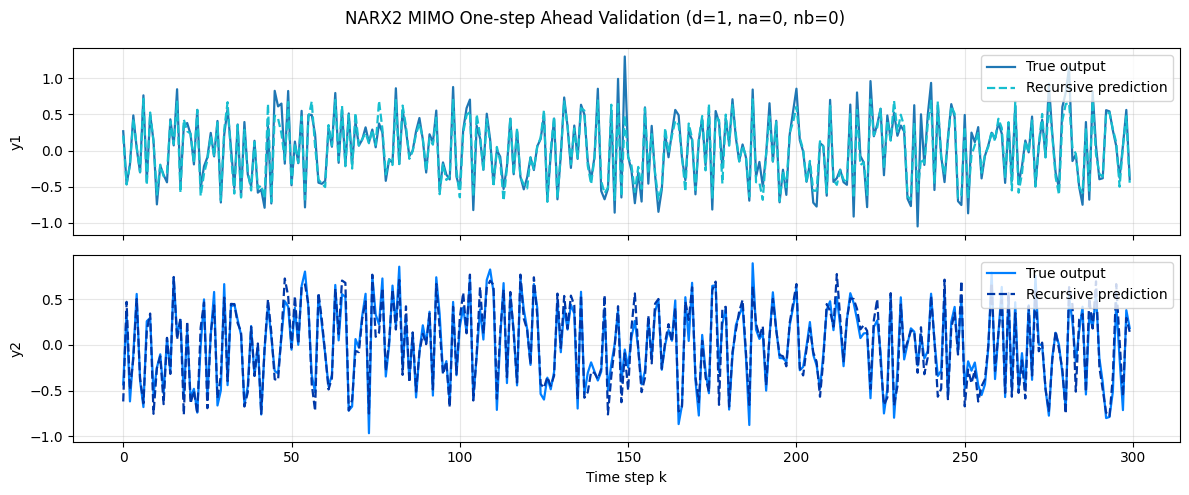

In [31]:
horizon_narx2 = max(best_n2_mimo['d'] + best_n2_mimo['na'], best_n2_mimo['nb'])
X_n2_tr, Y_n2_tr = build_mimo_features(narx2_U_tr, narx2_y_tr,d=best_n2_mimo['d'], na=best_n2_mimo['na'], nb=best_n2_mimo['nb'])
model_y1, model_y2 = train_mimo(X_n2_tr, Y_n2_tr, alpha=1.0)
#print(f'Trained on {X_n2_tr.shape[0]} samples from the first 70% of the series.')

X_n2_full, Y_n2_full_tgt = build_mimo_features(narx2_U, narx2_Y, d=best_n2_mimo['d'], na=best_n2_mimo['na'], nb=best_n2_mimo['nb'])
target_k_plus_1    = np.arange(horizon_narx2 + 1, len(narx2_Y))
val_mask           = target_k_plus_1 >= split1

Y_val_one_step = np.column_stack([
    model_y1.predict(X_n2_full[val_mask]),
    model_y2.predict(X_n2_full[val_mask]),
])
Y_val_true_os = Y_n2_full_tgt[val_mask]

nmse_os_narx2 = nmse(Y_val_true_os, Y_val_one_step)
rmse_os_narx2 = rmse(Y_val_true_os, Y_val_one_step)
print(f"\nNARX 2 | MIMO | One-step ahead validation NMSE: {nmse_os_narx2:.4f}, RMSE: {rmse_os_narx2:.4f}")
plot_comparison(Y_val_true_os, Y_val_one_step, title=f"NARX2 MIMO One-step Ahead Validation (d={best_n2_mimo['d']}, na={best_n2_mimo['na']}, nb={best_n2_mimo['nb']})")


NARX 2 | MIMO | Recursive validation NMSE: 0.0630, RMSE: 0.1143


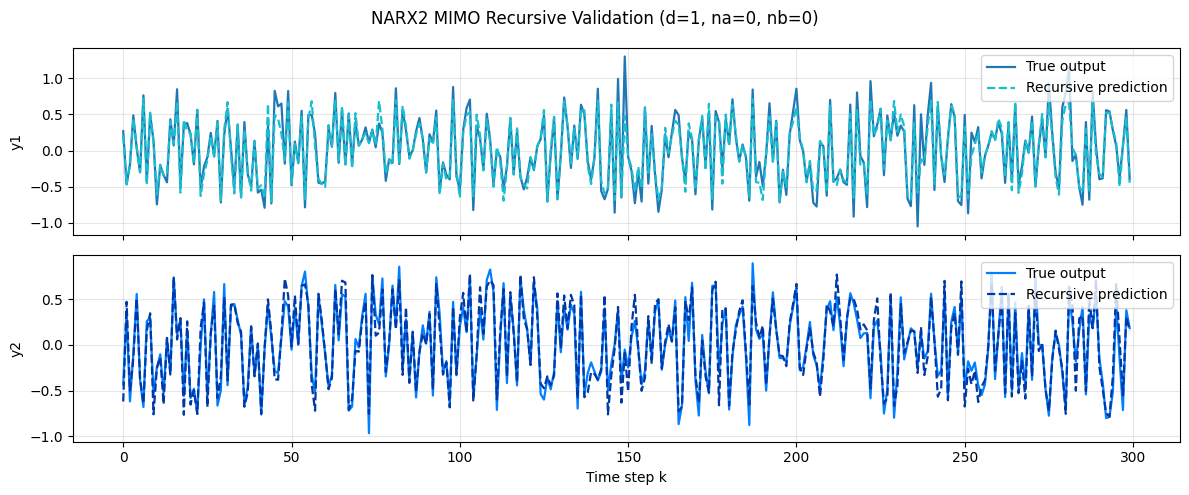

In [32]:
Y_roll = recursive_rollout_mimo(narx2_U, model_y1, model_y2,
                                d=best_n2_mimo['d'], na=best_n2_mimo['na'], nb=best_n2_mimo['nb'],
                                y_prefix=narx2_y_tr)
Y_val_rec     = Y_roll[split1:]
Y_val_true_rec = narx2_Y[split1:]

nmse_rec = nmse(Y_val_true_rec, Y_val_rec)
rmse_rec = rmse(Y_val_true_rec, Y_val_rec)

print(f"\nNARX 2 | MIMO | Recursive validation NMSE: {nmse_rec:.4f}, RMSE: {rmse_rec:.4f}")
plot_comparison(Y_val_true_rec, Y_val_rec, title=f"NARX2 MIMO Recursive Validation (d={best_n2_mimo['d']}, na={best_n2_mimo['na']}, nb={best_n2_mimo['nb']})")

In [33]:
metrics_table = pd.DataFrame([
    {'strategy': 'one_step_teacher_forcing', 'NMSE': nmse_os,  'RMSE': rmse_os},
    {'strategy': 'recursive_rollout',        'NMSE': nmse_rec, 'RMSE': rmse_rec},
])
print('\nValidation metrics on the held-out 30% of NARX1:')
print(metrics_table.to_string(index=False))
print(f'\nRecursive vs one-step NMSE ratio: {nmse_rec / max(nmse_os, 1e-12):.2f}')


Validation metrics on the held-out 30% of NARX1:
                strategy     NMSE     RMSE
one_step_teacher_forcing 0.013210 0.017584
       recursive_rollout 0.063017 0.114315

Recursive vs one-step NMSE ratio: 4.77


The recursive NMSE is higher than the single-step NMSE in both NARX pilots, which is to be expected when feedback is applied to the predictions; as the statement indicates, an error accumulation pattern is observed. Given that this is a test conducted with 300 values, in a 1,000-step rollout starting from zero initial conditions, this effect could be more pronounced. 

#### MISMO Results

NARX 1 | MISMO (s=100) NMSE=0.05196 RMSE=0.03487


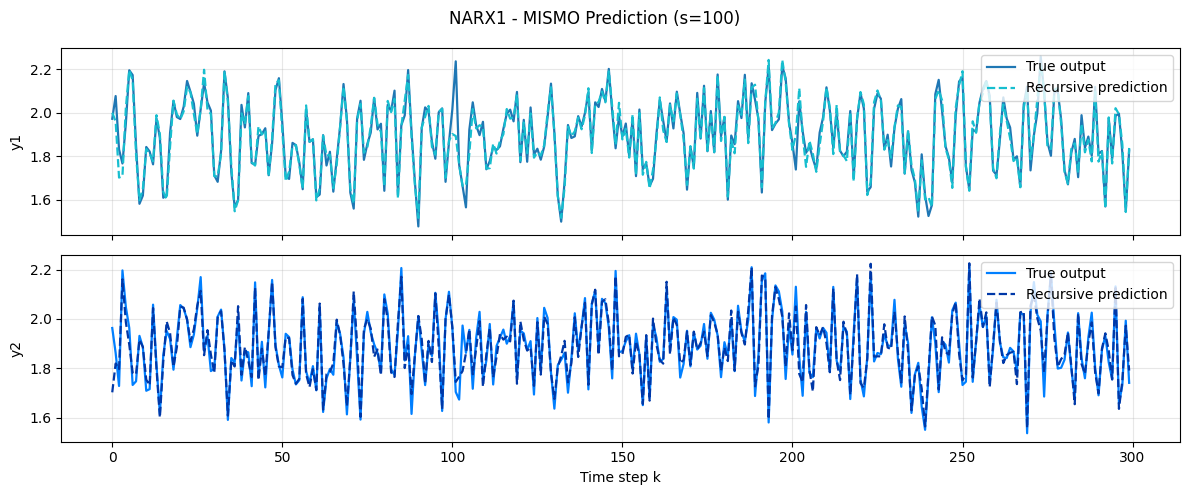

In [34]:
# We train the model with out train data and the best hyperparameters found 
narx1_modelMISMO = train_mismo(narx1_u_tr, narx1_y_tr, best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'])
# We generate the predictions 
narx1_yhat = mismo_rollout(narx1_modelMISMO , narx1_u_ts, best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'], y_prefix=narx1_y_tr)

# This test is based on 70% training data and 30% test data. 
print(f"NARX 1 | MISMO (s={best_n1_mismo['s']}) NMSE={nmse(narx1_y_ts,narx1_yhat):.5f}" f" RMSE={rmse(narx1_y_ts,narx1_yhat):.5f}")
plot_comparison(narx1_y_ts, narx1_yhat, title=f"NARX1 - MISMO Prediction (s={best_n1_mismo['s']})")

NARX 2 | MISMO (s=20) NMSE=0.13072 RMSE=0.16465


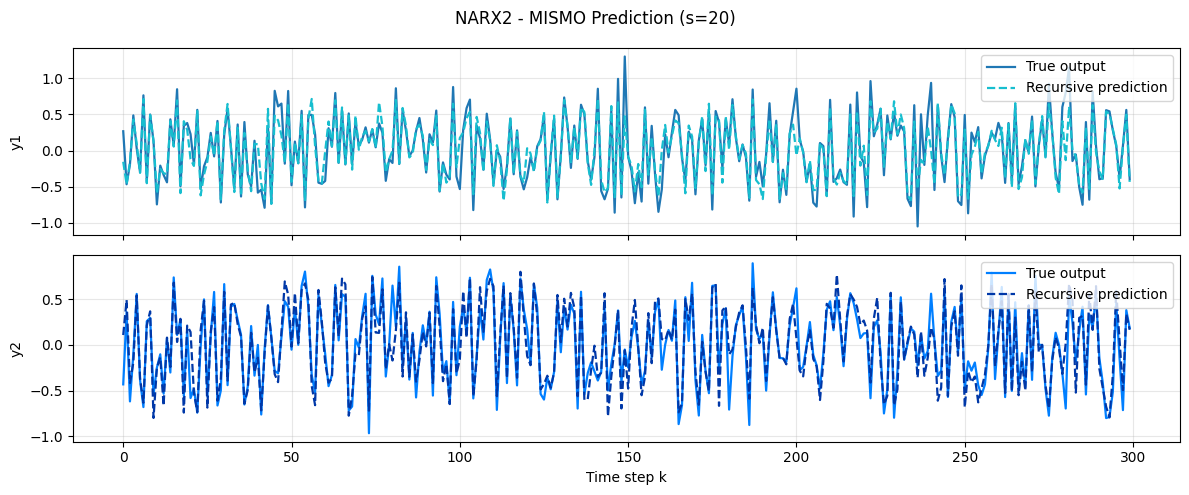

In [35]:
# We train the model with out train data and the best hyperparameters found 
narx2_modelMISMO = train_mismo(narx2_U_tr, narx2_y_tr, best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'])
# We generate the predictions 
narx2_yhat = mismo_rollout(narx2_modelMISMO , narx2_U_ts, best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'], y_prefix=narx2_y_tr)

# This test is based on 70% training data and 30% test data. 
print(f"NARX 2 | MISMO (s={best_n2_mismo['s']}) NMSE={nmse(narx2_y_ts,narx2_yhat):.5f}" f" RMSE={rmse(narx2_y_ts,narx2_yhat):.5f}")
plot_comparison(narx2_y_ts, narx2_yhat, title=f"NARX2 - MISMO Prediction (s={best_n2_mismo['s']})")

## Task 3. Baseline Approach - OLD ONE
### Step 1: Creating an appropiate dataframe 

Before being able to train non-deep learning models and create a sciki-learn pipeline, we need to develop a proper way to deal with data. In what follows, we are going to base our analysis on the data generated from the NARX1 simulation, but this will be easily extended to the ones from NARX2 simualtion and from the unkown NARX model. First, in order to keep everything tidy, we are going to work with `pandas` dataframes. Let us then creatre such a dataframe from the NARX1 simualtion data. We first load used the methodology for data simualtion implemented for the NARX1. In this step, we aim to obtain : 

$$
u_1^{tr}(k),\ u_2^{tr}(k),\ y_1^{tr}(k),\ y_2^{tr}(k) \quad k=1, \dots, N_{tr},
$$
where $N_{tr} = 1000$ corresponds to the size of the training set.

`Note:` Even if $u_2(k)$ does not exist for NARX1, we ane nonetheless going to create a corresponding column filled with zeros in order to easen the methodology for further developments.

Then, we create a dataframe containing all the relevant variables.


In [36]:
df_narx1 = pd.DataFrame(np.column_stack([narx1_u, narx1_y]), columns=['u1', 'y1', 'y2'])
df_narx1

,u1,y1,y2
0,0.000000,0.000000,0.000000
1,0.937081,-0.004827,0.006866
2,0.738389,0.015423,0.184791
3,0.061711,0.465922,0.169319
4,-0.534543,0.476193,0.468092
...,...,...,...
995,-0.788671,1.986204,2.132248
996,-0.895219,1.995698,1.656086
997,0.164201,1.815982,1.732078
998,-0.861751,1.547685,1.993068


In [37]:
df_narx2 = pd.DataFrame(np.column_stack([narx2_U, narx2_Y]), columns=['u1', 'u2', 'y1', 'y2'])
df_narx2

,u1,u2,y1,y2
0,0.000000,0.000000,0.000000,0.000000
1,-0.432441,0.136205,0.007165,0.004656
2,0.359833,-0.332603,0.135886,-0.419805
3,-0.417661,0.595368,-0.338634,0.358020
4,-0.187984,-0.642446,0.516510,-0.411502
...,...,...,...,...
995,0.107385,-0.701481,0.063033,0.458564
996,-0.757068,0.084161,-0.377481,-0.149618
997,0.403467,0.679819,0.069264,-0.714272
998,0.234074,-0.617597,0.561695,0.379580


### Step 2: Obtaining the target and Features Vectors
To prepare the data from the above dataframe for training, for a given row $k$, we first need to extract the target vector $y(k)$ and the features vector $X(k)$ based on the optimal parameters $n_a, n_b$ and $d$ found before. 

**1. The target vector $y(k)$**

The target vector represents our ground-truth values for the next time step: 

$$
y[k] = \left( y_1(k+1), \ y_2(k+1) \right)
$$

This is is easily obtained from the original dataframe by shifting the original outputs columns by one. 

`Note` : By shifting the outputs columns by one, the last row of y will be filled with NaNs and need to be discarded, it won't be of any use for model training.

In [38]:
#target_narx1 = df_narx1[['y1', 'y2']].shift(-1).rename(columns={'y1': 'y1(k+1)','y2': 'y2(k+1)'})
#target_narx1 = target_narx1.iloc[:-1].reset_index(drop=True)
target_narx1 = (
    df_narx1[['y1', 'y2']]
    .shift(-1)
    .rename(columns={'y1': 'y1(k+1)', 'y2': 'y2(k+1)'})
    .iloc[:-1]
    .reset_index(drop=True)
)

target_narx2 = (
    df_narx2[['y1', 'y2']]
    .shift(-1)
    .rename(columns={'y1': 'y1(k+1)', 'y2': 'y2(k+1)'})
    .iloc[:-1]
    .reset_index(drop=True)
)

print('target_narx1 shape:', target_narx1.shape)
print('target_narx2 shape:', target_narx2.shape)

target_narx1 shape: (999, 2)
target_narx2 shape: (999, 2)


**2.Features Vector**
The features vector $X(k)$ is constructed from the lagged observations of both inputs and ouputs. In `pandas`, these are generated by properly shifting the original columns down (e.g., $y_1(k-4)$ is the values of $y_1(k)$ from $4$ rows below). Our goal is to obtain a feature vector defined as : 

$$
X[k] = \left( y_1(k-d), \dots, y_1(k-d-n_a), \ y_2(k-d), \dots, y_2(k-d-n_a), \ u_1(k), \dots, u_1(k-n_b), \ u_2(k), \dots, u_2(k-n_b) \right).
$$

However, before obtaining the feature matrix and vectors by shifting the original dataframe accordingly, given that we dsicarded the last row of the ouputs daframe (the row of index $1000$), the same has to be done with the last row of the data. Indeed, for examples, the values of $u_1(1000)$ and $u_2(1000)$ will never be used for model training givne this consideration. 

Now, to obtain the features dataframe from the above one, we ned to properly shift everyhting following the best $n_a, n_b$ and $d$ found before in order to have every releavnt features required for predidciting $y_1(k+1)$ and $y_2(k+1)$ on row with index $k$. To do this, let us create a function `create_lagged_features` that takes the above dataframe and the parmaters as arguments, and returns a dataframe with all the releavant features to compute $y_1(k+1)$ and $y_2(k+1)$ on row $k$.

`Note` : Shifting the dataframe only following this method would produce starting NaNs values in the first few rows of the returned daframe. Indeed for example if $d = 5$, on row $k = 3$ we would end up with $y_1(k-d) = y_1(3-5) = y_1(-2)$, which is obviously a NaN. To paliate this issue and following project requirements, we are going to fill all these starting NaNs values in the dataframe with zeros.

In [39]:
def create_lagged_features(df, d, na, nb): # MIMO
    # Working on a copy
    data = df.copy()
    output_channels = [c for c in ('y1', 'y2') if c in data.columns]
    input_channels  = [c for c in ('u1', 'u2') if c in data.columns]
    
    # Lagged outputs: starting from delay d
    y_cols , u_cols = [], []

    for lag in range(d, d + na + 1):
        for ch in output_channels:
            col = f'{ch}(k)' if lag == 0 else f'{ch}(k-{lag})'
            data[col] = data[ch] if lag == 0 else data[ch].shift(lag)
            y_cols.append(col)

    for lag in range(0, nb + 1):
        for ch in input_channels:
            col = f'{ch}(k)' if lag == 0 else f'{ch}(k-{lag})'
            data[col] = data[ch] if lag == 0 else data[ch].shift(lag)
            u_cols.append(col)

    feat_df = data[y_cols + u_cols].fillna(0.0)
    # Reorder and handle NaNs from the shifts
    return feat_df.iloc[:-1].reset_index(drop=True)

In [40]:
d1  = best_n1_mimo['d']
na1 = best_n1_mimo['na']
nb1 = best_n1_mimo['nb']

print(f'NARX1 best params → d={d1}, na={na1}, nb={nb1}')
X_narx1 = create_lagged_features(df_narx1, d1, na1, nb1)
print(f'X_narx1 shape: {X_narx1.shape}  |  target_narx1 shape: {target_narx1.shape}')
assert len(X_narx1) == len(target_narx1), 'Shape mismatch after drop!'
X_narx1.head()

NARX1 best params → d=1, na=2, nb=6
X_narx1 shape: (999, 13)  |  target_narx1 shape: (999, 2)


,y1(k-1),y2(k-1),y1(k-2),y2(k-2),y1(k-3),y2(k-3),u1(k),u1(k-1),u1(k-2),u1(k-3),u1(k-4),u1(k-5),u1(k-6)
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.937081,0.000000,0.000000,0.000000,0.0,0.0,0.0
2,-0.004827,0.006866,0.000000,0.000000,0.000000,0.000000,0.738389,0.937081,0.000000,0.000000,0.0,0.0,0.0
3,0.015423,0.184791,-0.004827,0.006866,0.000000,0.000000,0.061711,0.738389,0.937081,0.000000,0.0,0.0,0.0
4,0.465922,0.169319,0.015423,0.184791,-0.004827,0.006866,-0.534543,0.061711,0.738389,0.937081,0.0,0.0,0.0


In [41]:
d2  = best_n2_mimo['d']
na2 = best_n2_mimo['na']
nb2 = best_n2_mimo['nb']

print(f'NARX2 best params → d={d2}, na={na2}, nb={nb2}')
X_narx2 = create_lagged_features(df_narx2, d2, na2, nb2)
print(f'X_narx2 shape: {X_narx2.shape}  |  target_narx2 shape: {target_narx2.shape}')
assert len(X_narx2) == len(target_narx2), 'Shape mismatch after drop!'
X_narx2.head()

NARX2 best params → d=1, na=0, nb=0
X_narx2 shape: (999, 4)  |  target_narx2 shape: (999, 2)


,y1(k-1),y2(k-1),u1(k),u2(k)
0,0.000000,0.000000,0.000000,0.000000
1,0.000000,0.000000,-0.432441,0.136205
2,0.007165,0.004656,0.359833,-0.332603
3,0.135886,-0.419805,-0.417661,0.595368
4,-0.338634,0.358020,-0.187984,-0.642446


### Step 3: Training and evaluating non-deep learning models
Our objective when training models is to identify the optimal mapping functions that minimize specific evaluations metrics, such as NMSE or RMSE. 

Concretely, we define the features vector $X(k)$ and we aim to estimate functions $\hat{f}_1$ and $\hat{f}_2$ such that :

$$
\hat{y}_1(k+1) = \hat{f}_1\left( X(k) \right), \quad \hat{y}_2(k+1) = \hat{f}_2\left( X(k) \right)
$$

The goal is to ensure that these predicitons are as close as possible to the ground-truth values $y_1(k+1)$ and $y_2(k+1)$ from the training data, based on our chosen metrics. 

Then, we note that when we are going to train our sklearn models using the `fit` function and then obtain predictions using `predict`, this will be done in a One-Step-Ahead way : The predicitons are based on the previous ground-truth values. 

However, given the context of the project, this is not what we want. Indeed, what we need is the model to make the next predicition by feeding its own past predicitons back into the model. In the context of the test set, we won't have any ground-truth reference value like we would with the training data or a validation set.

Let us therefore first define a `multiple_steps_ahead` function to feed back to the model its own previous predictions.


In [42]:
def multiple_steps_ahead(model, X_test, d, na):
    n_steps = len(X_test)
    preds = np.zeros((n_steps, 2))
    
    # Work on a copy so we don't wreck the original dataframe
    X_sim = X_test.copy()
    idx = X_test.index

    for k in range(n_steps):
        # Update the lagged features with our own previous predictions
        # We only care about lags that fall within our current simulation window
        for lag in range(d, d + na + 1):
            prev_k = k - lag
            
            if prev_k >= 0:
                # Directly update the simulation matrix for the current row
                y1_col = 'y1(k)' if lag == 0 else f'y1(k-{lag})'
                y2_col = 'y2(k)' if lag == 0 else f'y2(k-{lag})'
                X_sim.at[idx[k], y1_col] = preds[prev_k, 0]
                X_sim.at[idx[k], y2_col] = preds[prev_k, 1]

        # Predict using the updated row
        row = X_sim.loc[[idx[k]]]
        preds[k] = model.predict(row)[0]

    return preds

Having found our target and features vectors and with our utility function defined, we now proceed to the training and evaluation phases.

##### Time-Series Cross Validation 

Our system is inherently time dependent. Because of that, standard k-fold cross validation is inappropirate as it would involve prediciting past values using future data. Instead, we are going to use the `TimeSeriesSplit` method from `sklearn.model_selection`. This validation approach ensure that the training set always precedes the validation set, maintaining the casual integrity of the times series and preventing data leakage. This method will lead to the training data being split into folds, where each folds contains a training set and a validation set. The training set will be growing through time while the validation set is goign to keep the same size. The TimeSeriesSplit will allow to easily obtain the indices corresponding to the training set and validation sets in the original data, as can be seen in the cell below.

##### Candidate Models

In what follows, we are going to evaluate three disticnt non deep-learning models to identify the best fit for our system : 

1. **Linear Regression (OLS)** : It will serves as our baseline, assuming a linear relationship between the lagged features and the outputs. 
2. **K-Nearest Neighbors (KNN)** : Predicts outputs based on the similarity between the current feature vector and past training examples. 
3. **Random Forest** : Use of mutliple decision trees to capture non-linear interactions between features and outputs. 

##### Evaluation Strategy

For each fold of the time series cross-validation, each model will be evaluated by computing the RMSE and NMSE metrics on the validation part of the fold using two methods : 

- **One-Step-Ahead (OSA)** : As explained above, predictions are made using groud-truth lagged values. It will measure the model's immediate predictive accuracy. 
- **Multiple-Steps-Ahead (MSA)** : Will measure how well the model reacts to its own previous predictions being used as ground-truth. 

Given all these considerations, it is now time to finally train, evaluate and comapre our models.

In [43]:
models = {
    "OLS": LinearRegression(),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "RF": RandomForestRegressor(n_estimators=100, random_state=42)
}

In [44]:
def training_noDP_models(feature, target, d, na, nb,models):

    tscv = TimeSeriesSplit(n_splits=5)
    results = {name: {'osa': [], 'msa': []} for name in models}

    for fold, (train_idx, val_idx) in enumerate(tscv.split(feature), 1):

        X_tr  = feature.iloc[train_idx]
        X_val = feature.iloc[val_idx]
        y_tr  = target.iloc[train_idx]
        y_val = target.iloc[val_idx]
        y_val_np = y_val.values

        print(f"Fold {fold} (Train: {len(X_tr)} | Val: {len(X_val)})")

        for name, mdl in models.items():
            mdl.fit(X_tr, y_tr)

            # OSA
            pred_osa = mdl.predict(X_val)
            r_osa = (rmse(y_val_np, pred_osa), nmse(y_val_np, pred_osa))
            results[name]['osa'].append(r_osa)

            # MSA
            pred_msa = multiple_steps_ahead(mdl, X_val, d, na)
            r_msa = (rmse(y_val_np, pred_msa), nmse(y_val_np, pred_msa))
            results[name]['msa'].append(r_msa)

            print(f"{name:5} | OSA RMSE: {r_osa[0]:.4f} | MSA RMSE: {r_msa[0]:.4f}")
      
    print("\nSummary Results")
    for name, data in results.items():
        for mode in ['osa', 'msa']:
            arr = np.array(data[mode]) 
            mu = arr.mean(axis=0)
            sd = arr.std(axis=0)
            print(f"{name} {mode.upper()}: RMSE {mu[0]:.4f} (±{sd[0]:.3f}), NMSE {mu[1]:.4f} (±{sd[1]:.3f})")
    
    return results

In [45]:
print('-' * 55)
print('NARX1 – baseline model cross-validation\n')

results_narx1 = training_noDP_models(
    X_narx1, target_narx1, d1, na1, nb1, models
)

-------------------------------------------------------
NARX1 – baseline model cross-validation

Fold 1 (Train: 169 | Val: 166)
OLS   | OSA RMSE: 0.0226 | MSA RMSE: 900.7227
KNN   | OSA RMSE: 0.0653 | MSA RMSE: 0.0685
RF    | OSA RMSE: 0.0669 | MSA RMSE: 0.0850
Fold 2 (Train: 335 | Val: 166)
OLS   | OSA RMSE: 0.0188 | MSA RMSE: 62.9470
KNN   | OSA RMSE: 0.0654 | MSA RMSE: 0.0648
RF    | OSA RMSE: 0.0562 | MSA RMSE: 0.0946
Fold 3 (Train: 501 | Val: 166)
OLS   | OSA RMSE: 0.0191 | MSA RMSE: 5.1392
KNN   | OSA RMSE: 0.0563 | MSA RMSE: 0.0545
RF    | OSA RMSE: 0.0473 | MSA RMSE: 0.0980
Fold 4 (Train: 667 | Val: 166)
OLS   | OSA RMSE: 0.0187 | MSA RMSE: 2.2373
KNN   | OSA RMSE: 0.0586 | MSA RMSE: 0.0595
RF    | OSA RMSE: 0.0478 | MSA RMSE: 0.0931
Fold 5 (Train: 833 | Val: 166)
OLS   | OSA RMSE: 0.0198 | MSA RMSE: 0.7636
KNN   | OSA RMSE: 0.0546 | MSA RMSE: 0.0556
RF    | OSA RMSE: 0.0471 | MSA RMSE: 0.1001

Summary Results
OLS OSA: RMSE 0.0198 (±0.001), NMSE 0.0171 (±0.002)
OLS MSA: RMSE 19

In [46]:
print('-' * 55)
print('NARX2 – baseline model cross-validation\n')
results_narx2 = training_noDP_models(
    X_narx2, target_narx2, d2, na2, nb2, models
)

-------------------------------------------------------
NARX2 – baseline model cross-validation

Fold 1 (Train: 169 | Val: 166)
OLS   | OSA RMSE: 0.1052 | MSA RMSE: 0.1093
KNN   | OSA RMSE: 0.1428 | MSA RMSE: 0.1509
RF    | OSA RMSE: 0.1234 | MSA RMSE: 0.1247
Fold 2 (Train: 335 | Val: 166)
OLS   | OSA RMSE: 0.1237 | MSA RMSE: 0.1291
KNN   | OSA RMSE: 0.1353 | MSA RMSE: 0.1569


KeyboardInterrupt: 

#### Step 4: Optimization Strategy
The previous analysis provided a first overiew of the situation but, to ensure we are evaluating the full potential of our candidate models, we now perfom a grid search with cross-validation using the class `GridSearchCV` from `sklearn.model_selection`. This process will iterates through a predefined set of hyperparameters, selecting the combination that minimizes both the RMSE and NMSE accross the time series folds.

- For the Random Forest, we are going to tune the number of trees in the forest (`n_estimator`), the maximum depth of the trees (`max_depth`), and the minimum number of samples required at a leaf node (`min_samples_lead`). This will help balance underfitting and overfitting.

- For KNN, we optimize the number of neighbors (`n_neighbors`). A smaller $k$ makes the model sensitive to noise, while a larger one can make it too smooth to capture fast dynamic system.

In [ ]:
# Custom score: balancing NMSE and RMSE to keep errors tight
def mean_score(y, y_hat):
    return (rmse(y, y_hat) + nmse(y, y_hat)) / 2

In [ ]:
def test_models(feature, target,  tscv = TimeSeriesSplit(n_splits=5)):
    scorer = make_scorer(mean_score, greater_is_better=False)

    # Testing RF and KNN to see which handles the time-series drift better
    grids = {
        'rf': GridSearchCV(
            MultiOutputRegressor(RandomForestRegressor(random_state=42)),
            param_grid={
                'estimator__n_estimators': [50, 100, 300, 500],
                'estimator__max_depth': [None, 5, 10, 20],
                'estimator__min_samples_leaf': [1, 2, 5],
            },
            cv=tscv, scoring=scorer, verbose=1
        ),
        'knn': GridSearchCV(
            MultiOutputRegressor(KNeighborsRegressor()),
            param_grid={'estimator__n_neighbors': [3, 5, 10, 20]},
            cv=tscv, scoring=scorer
        )
    }

    for name, grid in grids.items():
        grid.fit(np.array(feature), np.array(target))
        print(f"{name.upper()} -> Best: {grid.best_params_} | Score: {-grid.best_score_:.4f}")

    best_rf, best_knn = grids['rf'].best_estimator_, grids['knn'].best_estimator_

    return best_rf, best_knn

In [ ]:
n1_best_rf, n1_best_knn = test_models(X_narx1, target_narx1)

In [ ]:
n2_best_rf, n2_best_knn = test_models(X_narx2, target_narx2)

---
## Task 3. Baseline Approach MISMO

In [47]:
models = {
    'OLS':   LinearRegression(),
    'Ridge': Ridge(alpha=1.0),
    'KNN':   KNeighborsRegressor(n_neighbors=5),
    'RF':    MultiOutputRegressor(
                RandomForestRegressor(n_estimators=20, max_depth=12,
                                      min_samples_leaf=2,
                                      random_state=42, n_jobs=-1),
                n_jobs=1),
}

In [48]:
def score_models(models, U_tr, Y_tr, U_ts, Y_ts, d, na, s, y_prefix=None):

    results = []
    yhats = {}

    for name, model in models.items():
        trained = train_mismo(U_tr, Y_tr, d, na, s, model)
        yhat = mismo_rollout(trained,U_ts,d,na,s, y_prefix=y_prefix)

        results.append({
            'model': name,
            'nmse': nmse(Y_ts, yhat),
            'rmse': rmse(Y_ts, yhat)
        })
        yhats[name] = yhat

    return pd.DataFrame(results).sort_values('nmse').reset_index(drop=True), yhats

In [50]:
## Get models for NARX1
results_df_narx1, yhats_narx1 = score_models(models, narx1_u_tr, narx1_y_tr, narx1_u_ts, narx1_y_ts, best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'], y_prefix=narx1_y_tr)
print(results_df_narx1)

   model      nmse      rmse
0  Ridge  0.053344  0.035336
1    OLS  0.053842  0.035500
2     RF  0.152933  0.059830
3    KNN  0.797031  0.136587


In [51]:
### Get models for NARX2
results_df_narx2, yhats_narx2 = score_models(models, narx2_U_tr, narx2_y_tr, narx2_U_ts, narx2_y_ts, best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'], y_prefix=narx2_y_tr)
print(results_df_narx2)

   model      nmse      rmse
0     RF  0.119841  0.157644
1  Ridge  0.130972  0.164803
2    OLS  0.131026  0.164837
3    KNN  0.659921  0.369932


## TASK 4. Deep Learning Approach MISMO

In [52]:
%pip install torch
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from copy import deepcopy

TORCH_SEED = 8
torch.manual_seed(TORCH_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Pytorch {torch.__version__} - Device: {device}")

Note: you may need to restart the kernel to use updated packages.
Pytorch 2.11.0+cpu - Device: cpu


In [53]:
class MismoMLP(nn.Module):
    """MLP that maps a flat MISMO feature vector to a 2*s output vector."""
    def __init__(self, in_dim, out_dim, hidden_sizes=(256, 128, 64), dropout=0.1):
        super().__init__()
        layers = []
        prev = in_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class MismoLSTM(nn.Module):
    """
    Sequential LSTM for MISMO with two-branch design.

    Encoder reads Y-history as a length-(na+1) sequence over R^2, producing a
    hidden state that summarizes the system's recent dynamics. Future inputs
    are concatenated with this state before the linear head.
    """
    def __init__(self, na, s, n_in_u, hidden_size=128, dropout=0.1):
        super().__init__()
        self.na = na
        self.s = s
        self.n_in_u = n_in_u
        self.hidden_size = hidden_size

        self.encoder = nn.LSTM(input_size=2, hidden_size=hidden_size, batch_first=True)
        self.dropout = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_size + n_in_u * s, 2 * s)

    def forward(self, x):
        # x layout: [Y_lags (flat, 2*(na+1)), U_future (flat, n_in_u*s)]
        batch = x.shape[0]
        y_part_len = 2 * (self.na + 1)
        y_flat = x[:, :y_part_len]
        u_flat = x[:, y_part_len:]
        # reshape Y lags into (batch, na+1, 2) — temporal sequence
        y_seq = y_flat.view(batch, self.na + 1, 2)
        _, (h_n, _) = self.encoder(y_seq)
        h_last = h_n[-1]
        merged = torch.cat([self.dropout(h_last), u_flat], dim=1)
        return self.head(merged)

In [54]:
from sklearn.base import BaseEstimator, RegressorMixin

class TorchMismoRegressor(BaseEstimator, RegressorMixin):
    """
    Sklearn-compatible torch wrapper for MISMO models. Internal scaling +
    early stopping. Use train_mismo_torch() instead of train_mismo() for
    the deep variants.
    """
    def __init__(self, arch='mlp', na=None, s=None, n_in_u=None,
                 hidden_sizes=(256, 128, 64), lstm_hidden=128, dropout=0.1,
                 lr=1e-3, weight_decay=1e-4, batch_size=32,
                 max_epochs=500, patience=40, val_ratio=0.2,
                 random_state=42, verbose=False):
        self.arch = arch
        self.na = na
        self.s = s
        self.n_in_u = n_in_u
        self.hidden_sizes = hidden_sizes
        self.lstm_hidden = lstm_hidden
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_ratio = val_ratio
        self.random_state = random_state
        self.verbose = verbose

    def _build_model(self, in_dim, out_dim):
        if self.arch == 'mlp':
            return MismoMLP(in_dim, out_dim, self.hidden_sizes, self.dropout)
        elif self.arch == 'lstm':
            if self.na is None or self.s is None or self.n_in_u is None:
                raise ValueError("LSTM arch requires na, s, n_in_u to be set.")
            return MismoLSTM(self.na, self.s, self.n_in_u, self.lstm_hidden, self.dropout)
        else:
            raise ValueError(f"Unknown arch: {self.arch}")

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        X = np.asarray(X, dtype=np.float32)
        y = np.asarray(y, dtype=np.float32)
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        # Internal scaling fit on training portion only (no leakage)
        self.scaler_x_ = StandardScaler()
        self.scaler_y_ = StandardScaler()

        split = max(2, int(X.shape[0] * (1.0 - self.val_ratio)))
        split = min(split, X.shape[0] - 2)

        Xtr_raw, Xval_raw = X[:split], X[split:]
        ytr_raw, yval_raw = y[:split], y[split:]
        self.scaler_x_.fit(Xtr_raw)
        self.scaler_y_.fit(ytr_raw)
        Xtr = self.scaler_x_.transform(Xtr_raw).astype(np.float32)
        Xval = self.scaler_x_.transform(Xval_raw).astype(np.float32)
        ytr = self.scaler_y_.transform(ytr_raw).astype(np.float32)
        yval = self.scaler_y_.transform(yval_raw).astype(np.float32)

        in_dim, out_dim = Xtr.shape[1], ytr.shape[1]
        self.model_ = self._build_model(in_dim, out_dim).to(device)

        tr_ds = TensorDataset(torch.tensor(Xtr), torch.tensor(ytr))
        val_ds = TensorDataset(torch.tensor(Xval), torch.tensor(yval))
        tr_dl = DataLoader(tr_ds, batch_size=self.batch_size, shuffle=True)
        val_dl = DataLoader(val_ds, batch_size=self.batch_size, shuffle=False)

        opt = torch.optim.Adam(self.model_.parameters(), lr=self.lr,
                               weight_decay=self.weight_decay)
        loss_fn = nn.MSELoss()

        best_state, best_val, bad = None, np.inf, 0
        history = []
        for epoch in range(1, self.max_epochs + 1):
            self.model_.train()
            tr_loss = 0.0
            for xb, yb in tr_dl:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad()
                pred = self.model_(xb)
                loss = loss_fn(pred, yb)
                loss.backward()
                nn.utils.clip_grad_norm_(self.model_.parameters(), 1.0)
                opt.step()
                tr_loss += loss.item() * len(xb)
            tr_loss /= len(tr_ds)

            self.model_.eval()
            with torch.no_grad():
                val_loss = sum(
                    loss_fn(self.model_(xb.to(device)), yb.to(device)).item() * len(xb)
                    for xb, yb in val_dl
                ) / len(val_ds)
            history.append((tr_loss, val_loss))

            if self.verbose and (epoch == 1 or epoch % 50 == 0):
                print(f"  epoch={epoch:4d}  tr_mse={tr_loss:.6f}  val_mse={val_loss:.6f}")

            if val_loss < best_val - 1e-8:
                best_val, best_state, bad = val_loss, deepcopy(self.model_.state_dict()), 0
            else:
                bad += 1
                if bad >= self.patience:
                    if self.verbose:
                        print(f"  early stop @ epoch {epoch}, best val_mse={best_val:.6f}")
                    break

        if best_state is not None:
            self.model_.load_state_dict(best_state)
        self.best_val_mse_ = float(best_val)
        self.history_ = history
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=np.float32)
        Xs = self.scaler_x_.transform(X).astype(np.float32)
        self.model_.eval()
        with torch.no_grad():
            yp = self.model_(torch.tensor(Xs).to(device)).cpu().numpy()
        return self.scaler_y_.inverse_transform(yp).astype(float)


def train_mismo_torch(U_tr, Y_tr, d, na, s, arch='mlp', **kw):
    """
    Variant of train_mismo() for torch models. Returns an object with .predict()
    that mismo_rollout() can call directly.
    """
    X, T = build_mismo_features(U_tr, Y_tr, d, na, s)
    n_in_u = U_tr.shape[1]
    model = TorchMismoRegressor(arch=arch, na=na, s=s, n_in_u=n_in_u, **kw)
    model.fit(X, T)
    return model

### Training and Evaluating on NARX1

Training MISMO MLP on NARX1...
  epoch=   1  tr_mse=1.003916  val_mse=0.985701
  epoch=  50  tr_mse=0.506963  val_mse=0.547477
  epoch= 100  tr_mse=0.466165  val_mse=0.513489
  epoch= 150  tr_mse=0.440427  val_mse=0.502484
  epoch= 200  tr_mse=0.427769  val_mse=0.496323
  epoch= 250  tr_mse=0.423657  val_mse=0.495995
  early stop @ epoch 256, best val_mse=0.491715

NARX1 | MISMO MLP  | NMSE=0.54242  RMSE=0.11268

Training MISMO LSTM on NARX1...
  epoch=   1  tr_mse=1.113314  val_mse=1.045534
  epoch=  50  tr_mse=0.104125  val_mse=0.174665
  epoch= 100  tr_mse=0.036013  val_mse=0.061128
  epoch= 150  tr_mse=0.032386  val_mse=0.054317
  epoch= 200  tr_mse=0.032279  val_mse=0.053905
  early stop @ epoch 215, best val_mse=0.053643

NARX1 | MISMO LSTM | NMSE=0.06439  RMSE=0.03882


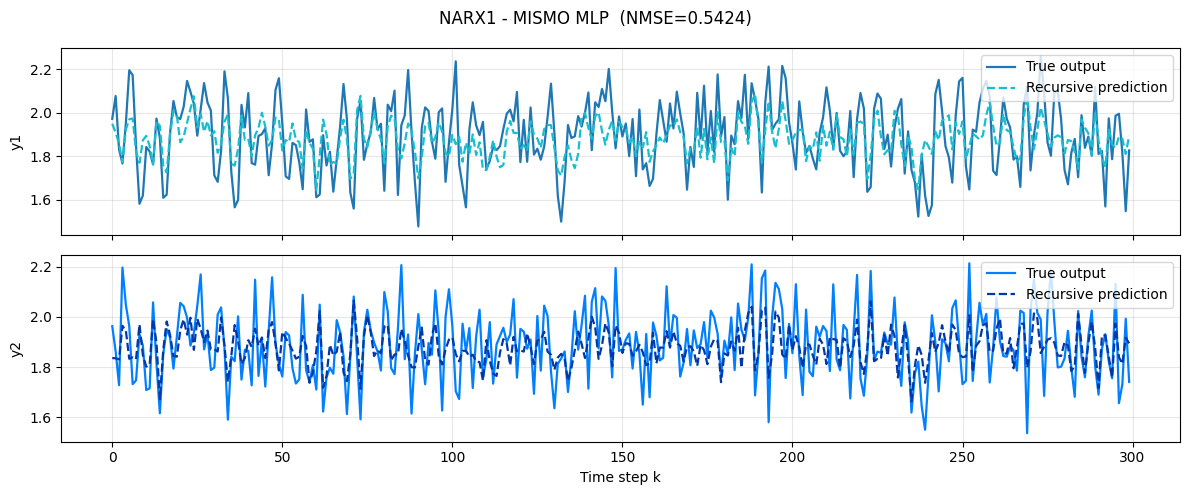

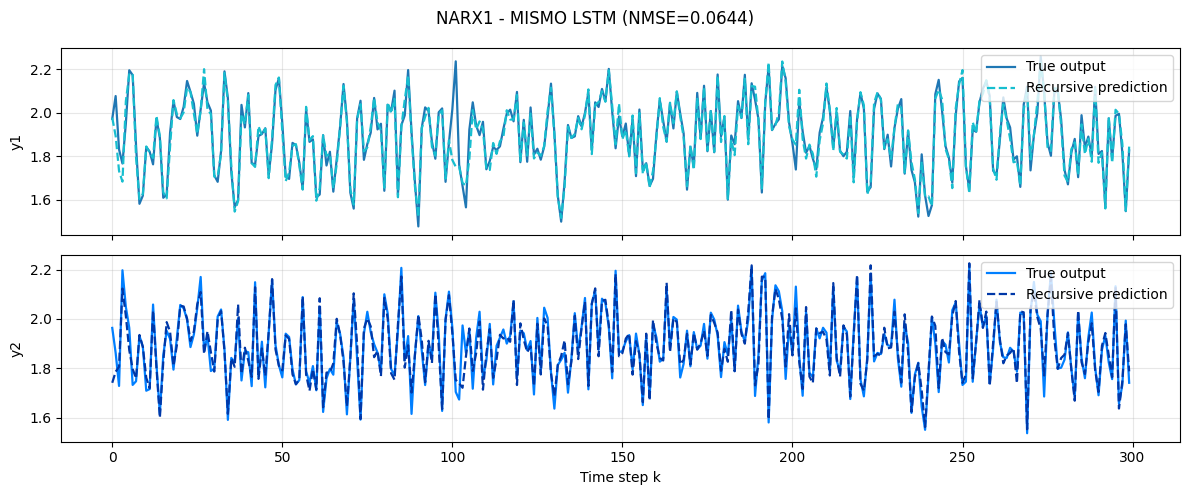

In [56]:
print("Training MISMO MLP on NARX1...")
narx1_mlp = train_mismo_torch(narx1_u_tr, narx1_y_tr,
                              d=best_n1_mismo['d'], na=best_n1_mismo['na'], s=best_n1_mismo['s'],
                              arch='mlp',
                              hidden_sizes=(256, 128, 64),
                              dropout=0.1,
                              max_epochs=500,
                              patience=40,
                              verbose=True)
narx1_mlp_yhat = mismo_rollout(narx1_mlp, narx1_u_ts,
                               best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'],
                               y_prefix=narx1_y_tr)
mlp1_nmse = nmse(narx1_y_ts, narx1_mlp_yhat)
mlp1_rmse = rmse(narx1_y_ts, narx1_mlp_yhat)
print(f"\nNARX1 | MISMO MLP  | NMSE={mlp1_nmse:.5f}  RMSE={mlp1_rmse:.5f}")

# Train LSTM on NARX1
print("\nTraining MISMO LSTM on NARX1...")
narx1_lstm = train_mismo_torch(narx1_u_tr, narx1_y_tr,
                               d=best_n1_mismo['d'], na=best_n1_mismo['na'], s=best_n1_mismo['s'],
                               arch='lstm',
                               lstm_hidden=128,
                               dropout=0.1,
                               max_epochs=500,
                               patience=40,
                               verbose=True)
narx1_lstm_yhat = mismo_rollout(narx1_lstm, narx1_u_ts,
                                best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'],
                                y_prefix=narx1_y_tr)
lstm1_nmse = nmse(narx1_y_ts, narx1_lstm_yhat)
lstm1_rmse = rmse(narx1_y_ts, narx1_lstm_yhat)
print(f"\nNARX1 | MISMO LSTM | NMSE={lstm1_nmse:.5f}  RMSE={lstm1_rmse:.5f}")

# Visual comparison
plot_comparison(narx1_y_ts, narx1_mlp_yhat,  title=f"NARX1 - MISMO MLP  (NMSE={mlp1_nmse:.4f})")
plot_comparison(narx1_y_ts, narx1_lstm_yhat, title=f"NARX1 - MISMO LSTM (NMSE={lstm1_nmse:.4f})")

### Training and Evaluating on NARX2

Training MISMO MLP on NARX2...
  epoch=   1  tr_mse=0.996209  val_mse=0.942523
  epoch=  50  tr_mse=0.313696  val_mse=0.281573
  early stop @ epoch 94, best val_mse=0.275307

NARX2 | MISMO MLP  | NMSE=0.28424  RMSE=0.24278

Training MISMO LSTM on NARX2...
  epoch=   1  tr_mse=1.035884  val_mse=0.983316
  epoch=  50  tr_mse=0.192924  val_mse=0.222281
  epoch= 100  tr_mse=0.099970  val_mse=0.113685
  epoch= 150  tr_mse=0.095777  val_mse=0.109918
  early stop @ epoch 168, best val_mse=0.109703

NARX2 | MISMO LSTM | NMSE=0.12989  RMSE=0.16412


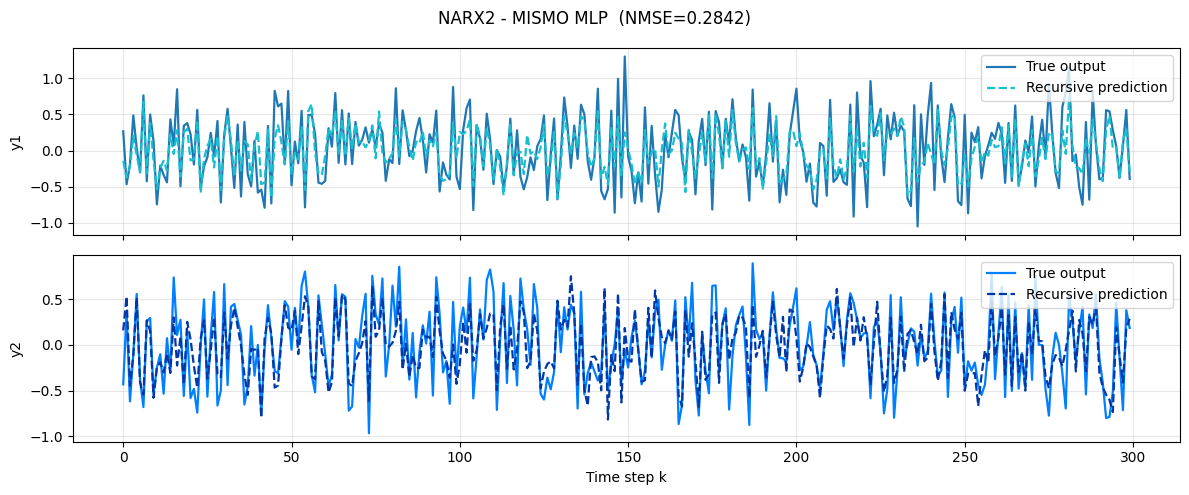

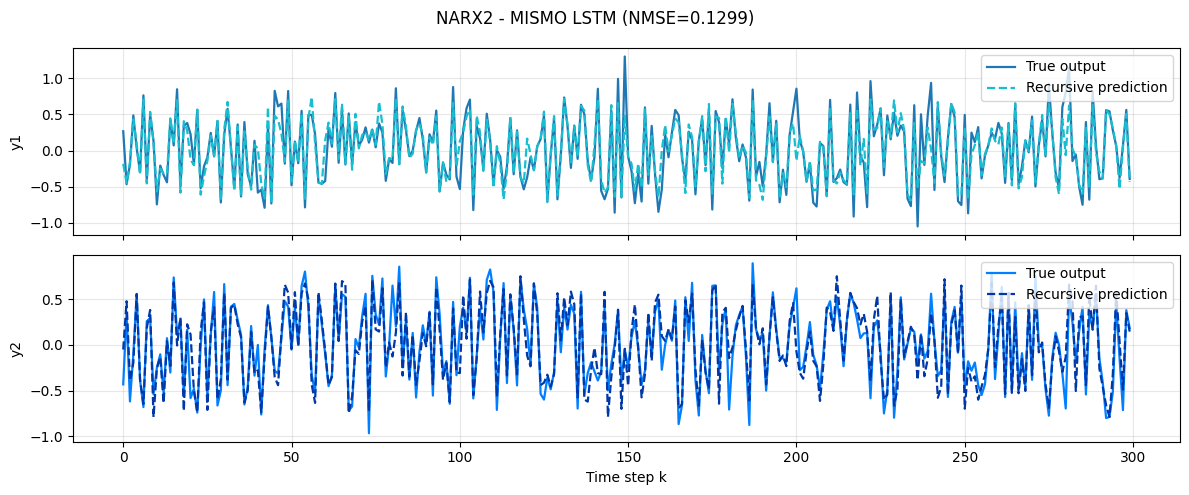

In [57]:
print("Training MISMO MLP on NARX2...")
narx2_mlp = train_mismo_torch(narx2_U_tr, narx2_y_tr,
                              d=best_n2_mismo['d'], na=best_n2_mismo['na'], s=best_n2_mismo['s'],
                              arch='mlp',
                              hidden_sizes=(256, 128, 64),
                              dropout=0.1,
                              max_epochs=500,
                              patience=40,
                              verbose=True)
narx2_mlp_yhat = mismo_rollout(narx2_mlp, narx2_U_ts,
                               best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'],
                               y_prefix=narx2_y_tr)
mlp2_nmse = nmse(narx2_y_ts, narx2_mlp_yhat)
mlp2_rmse = rmse(narx2_y_ts, narx2_mlp_yhat)
print(f"\nNARX2 | MISMO MLP  | NMSE={mlp2_nmse:.5f}  RMSE={mlp2_rmse:.5f}")

# Train LSTM on NARX2
print("\nTraining MISMO LSTM on NARX2...")
narx2_lstm = train_mismo_torch(narx2_U_tr, narx2_y_tr,
                               d=best_n2_mismo['d'], na=best_n2_mismo['na'], s=best_n2_mismo['s'],
                               arch='lstm',
                               lstm_hidden=128,
                               dropout=0.1,
                               max_epochs=500,
                               patience=40,
                               verbose=True)
narx2_lstm_yhat = mismo_rollout(narx2_lstm, narx2_U_ts,
                                best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'],
                                y_prefix=narx2_y_tr)
lstm2_nmse = nmse(narx2_y_ts, narx2_lstm_yhat)
lstm2_rmse = rmse(narx2_y_ts, narx2_lstm_yhat)
print(f"\nNARX2 | MISMO LSTM | NMSE={lstm2_nmse:.5f}  RMSE={lstm2_rmse:.5f}")

# Visual comparison
plot_comparison(narx2_y_ts, narx2_mlp_yhat,  title=f"NARX2 - MISMO MLP  (NMSE={mlp2_nmse:.4f})")
plot_comparison(narx2_y_ts, narx2_lstm_yhat, title=f"NARX2 - MISMO LSTM (NMSE={lstm2_nmse:.4f})")

### Classical vs Deep Learning

In [58]:
# Aggregate all results into a single DataFrame for both pilots
def _ridge_nmse(u_tr, y_tr, u_ts, y_ts, d, na, s):
    mod = train_mismo(u_tr, y_tr, d, na, s)
    yhat = mismo_rollout(mod, u_ts, d, na, s, y_prefix=y_tr)
    return nmse(y_ts, yhat), rmse(y_ts, yhat)

ridge1_nmse, ridge1_rmse = _ridge_nmse(narx1_u_tr, narx1_y_tr, narx1_u_ts, narx1_y_ts,
                                       best_n1_mismo['d'], best_n1_mismo['na'], best_n1_mismo['s'])
ridge2_nmse, ridge2_rmse = _ridge_nmse(narx2_U_tr, narx2_y_tr, narx2_U_ts, narx2_y_ts,
                                       best_n2_mismo['d'], best_n2_mismo['na'], best_n2_mismo['s'])

comparison = pd.DataFrame([
    {'pilot': 'NARX1', 'model': 'RidgeCV',    'NMSE': ridge1_nmse, 'RMSE': ridge1_rmse},
    {'pilot': 'NARX1', 'model': 'MISMO MLP',  'NMSE': mlp1_nmse,   'RMSE': mlp1_rmse},
    {'pilot': 'NARX1', 'model': 'MISMO LSTM', 'NMSE': lstm1_nmse,  'RMSE': lstm1_rmse},
    {'pilot': 'NARX2', 'model': 'RidgeCV',    'NMSE': ridge2_nmse, 'RMSE': ridge2_rmse},
    {'pilot': 'NARX2', 'model': 'MISMO MLP',  'NMSE': mlp2_nmse,   'RMSE': mlp2_rmse},
    {'pilot': 'NARX2', 'model': 'MISMO LSTM', 'NMSE': lstm2_nmse,  'RMSE': lstm2_rmse},
])

print("Classical vs Deep Learning comparison:")
print(comparison.to_string(index=False))

Classical vs Deep Learning comparison:
pilot      model     NMSE     RMSE
NARX1    RidgeCV 0.051960 0.034874
NARX1  MISMO MLP 0.542422 0.112678
NARX1 MISMO LSTM 0.064388 0.038822
NARX2    RidgeCV 0.130723 0.164646
NARX2  MISMO MLP 0.284240 0.242783
NARX2 MISMO LSTM 0.129892 0.164122


## Task 5. IN THE REAL DATASET MISMO

Loading: C:\Users\kamil\Desktop_new\Local\Universidad\F422-Proyecto\project-2025-2026-team-10-1\KamilaWork\StudentDataNARX.npz
Utr: (1000, 2), Ytr: (1000, 2)
Uts1: (1000, 2), Uts2: (1000, 2)

Training stats:
              u1         u2         y1         y2
count  1000.0000  1000.0000  1000.0000  1000.0000
mean     -0.0268    -0.0343    -0.0177    -0.3769
std       0.6142     0.6116     0.2206     0.5797
min      -2.3691    -2.2201    -2.0730    -4.8563
25%      -0.4488    -0.4659    -0.0575    -0.6192
50%      -0.0312    -0.0402    -0.0013    -0.2475
75%       0.3749     0.3796     0.0477    -0.0064
max       1.7917     1.6140     1.9505     1.0713


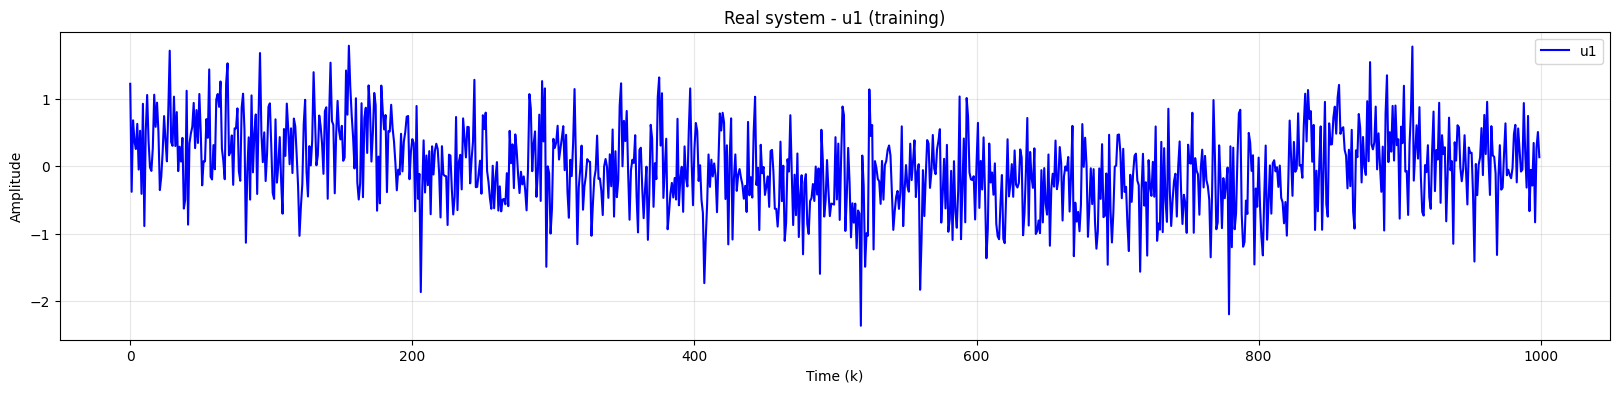

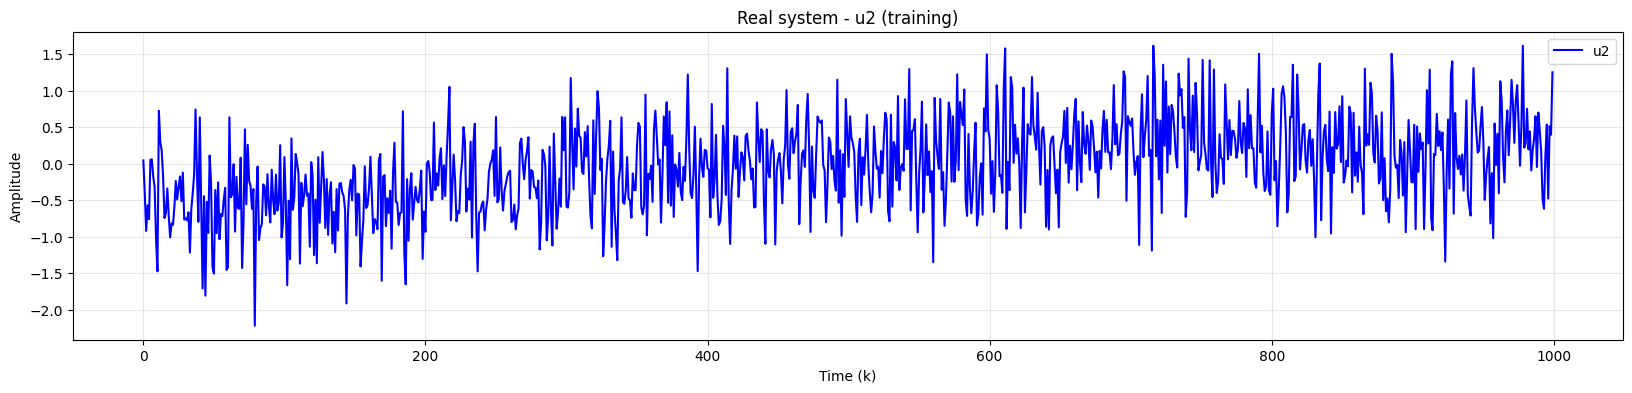

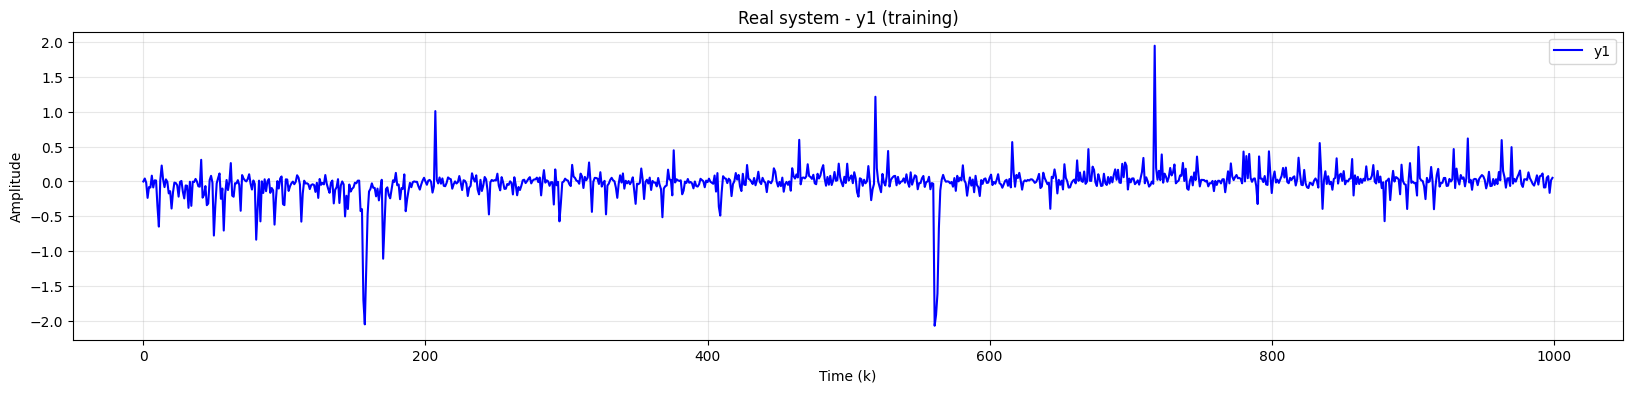

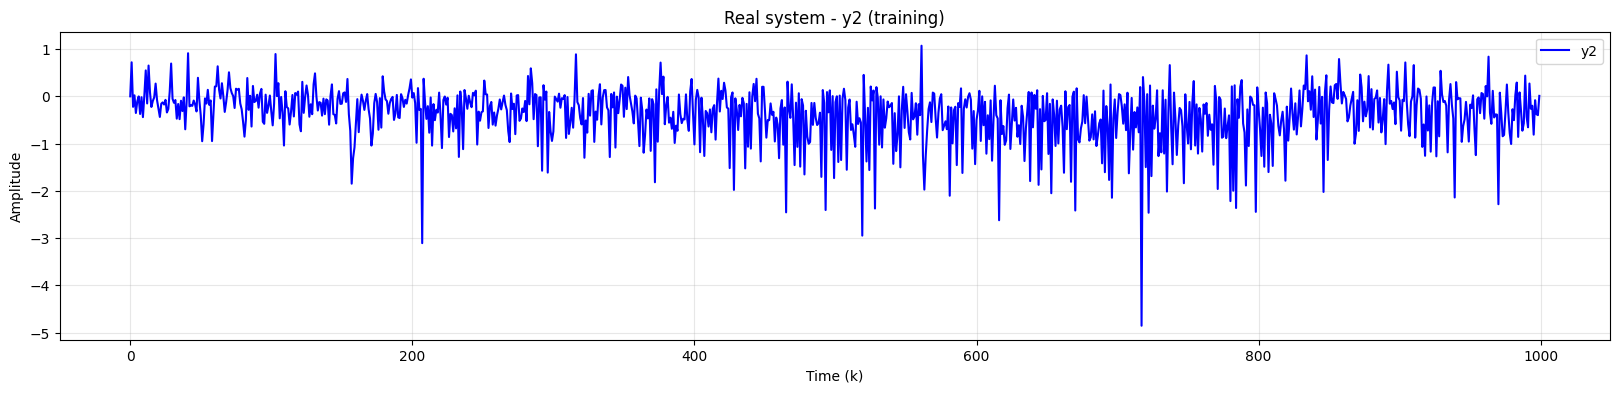

In [60]:
real_data_path = Path('/data/StudentdataNARX.npz')
#real_data_path = Path('C:\\Users\\kamil\\Desktop_new\\Local\\Universidad\\F422-Proyecto\\project-2025-2026-team-10-1\\KamilaWork\\StudentDataNARX.npz')
real_data_path = Path('C:/Users/kamil/Desktop_new/Local/Universidad/F422-Proyecto/project-2025-2026-team-10-1/KamilaWork/StudentDataNARX.npz')

if not real_data_path.exists():
    # fallback: try a few alternate paths so this works regardless of cwd
    for alt in [Path('data/StudentdataNARX.npz'),
                Path('../../data/StudentdataNARX.npz'),
                Path.cwd().parent / 'data' / 'StudentdataNARX.npz']:
        if alt.exists():
            real_data_path = alt
            break
    else:
        raise FileNotFoundError(
            f"StudentdataNARX.npz not found. Tried: {real_data_path}. "
            "Update the path manually if your project layout differs."
        )

print(f"Loading: {real_data_path.resolve()}")
real = np.load(real_data_path)
required = ['Utr', 'Ytr', 'Uts1', 'Uts2']
missing = [k for k in required if k not in real.files]
if missing:
    raise KeyError(f"Missing arrays in dataset: {missing}")

Utr  = np.asarray(real['Utr'],  dtype=float)
Ytr  = np.asarray(real['Ytr'],  dtype=float)
Uts1 = np.asarray(real['Uts1'], dtype=float)
Uts2 = np.asarray(real['Uts2'], dtype=float)

# Sanity checks
for name, arr, expected in [('Utr', Utr, (1000, 2)),
                            ('Ytr', Ytr, (1000, 2)),
                            ('Uts1', Uts1, (1000, 2)),
                            ('Uts2', Uts2, (1000, 2))]:
    assert arr.shape == expected, f"{name} has shape {arr.shape}, expected {expected}"
    assert not np.isnan(arr).any(), f"{name} contains NaN"
    assert not np.isinf(arr).any(), f"{name} contains Inf"

print(f"Utr: {Utr.shape}, Ytr: {Ytr.shape}")
print(f"Uts1: {Uts1.shape}, Uts2: {Uts2.shape}")
print(f"\nTraining stats:")
print(pd.DataFrame({
    'u1': Utr[:, 0], 'u2': Utr[:, 1],
    'y1': Ytr[:, 0], 'y2': Ytr[:, 1],
}).describe().round(4))

# Quick visual check
plot_1(Utr[:, 0], title="Real system - u1 (training)", label="u1")
plot_1(Utr[:, 1], title="Real system - u2 (training)", label="u2")
plot_1(Ytr[:, 0], title="Real system - y1 (training)", label="y1")
plot_1(Ytr[:, 1], title="Real system - y2 (training)", label="y2")

### Parameter selection on the real system

In [85]:
N_real = len(Utr)
split_real = int(0.7 * N_real)

Utr_in,  Utr_val  = Utr[:split_real],  Utr[split_real:]
Ytr_in,  Ytr_val  = Ytr[:split_real],  Ytr[split_real:]
print(f"Internal train: {Utr_in.shape}, internal val: {Utr_val.shape}")

# Step 1 — delay candidates
print("\n_______ Estimating d candidates for the real system...")
d_real, peaks_real = estimate_d_candidates(Utr_in, Ytr_in, max_lag=40, max_d=10)

# Step 2 — grid search
grid_real = {
    'd':  d_real,
    'na': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    's':  [1, 5, 10, 20, 50, 100, 200],
}

print("\n=== Grid search on real data (this can take a few minutes) ===")
best_real, df_real = grid_search_mismo(Utr_in, Ytr_in, grid_real, label="Real System")
                                 

Internal train: (700, 2), internal val: (300, 2)

_______ Estimating d candidates for the real system...

Positive-lag peaks per (input, output) pair:
  u1 -> y1: peak at lag 1
  u1 -> y2: peak at lag 1
  u2 -> y1: peak at lag 1
  u2 -> y2: peak at lag 1

CCF min peak: 1, median peak: 1

Will test d in [0, 1, 2, 3, 4, 5, 6, 7, 8, 9] during grid search

=== Grid search on real data (this can take a few minutes) ===

___ Grid (d, na, s) __ Real System ___
 d  na   s     nmse     rmse
 9   0  10 0.674077 0.405435
 6   0  10 0.676172 0.406065
 9   1  10 0.676413 0.406137
 9   1  20 0.676757 0.406241
 8   1  10 0.677022 0.406320
 4   3  20 0.677245 0.406387
 9   9  20 0.677500 0.406464
 9   2  10 0.677501 0.406464
 4   2  20 0.677706 0.406525
 9   2  20 0.677819 0.406559
 3   4  20 0.677999 0.406613
 4   6  20 0.678038 0.406625
 9  10  20 0.678213 0.406677
 9   0  20 0.678319 0.406709
 4   1  20 0.678359 0.406721
 3   3  20 0.678493 0.406761
 9   8  20 0.678580 0.406788
 5   2  20 0.678688 

### Best model 

In [86]:
def evaluate_on_val(name, model_obj, U_in, Y_in, U_val, Y_val,
                    d, na, s, is_torch=False):
    """Train on internal training data, score with rollout NMSE on val."""
    if is_torch:
        trained = model_obj  # already trained externally for torch
    else:
        trained = train_mismo(U_in, Y_in, d, na, s, model_obj)
    yhat = mismo_rollout(trained, U_val, d, na, s, y_prefix=Y_in)
    return {
        'model': name,
        'nmse': nmse(Y_val, yhat),
        'rmse': rmse(Y_val, yhat),
        'trained': trained,
    }

d_r, na_r, s_r = best_real['d'], best_real['na'], best_real['s']
print(f"Using d={d_r}, na={na_r}, s={s_r}")

candidates = []

# 1) RidgeCV
print("\n[1/3] Training RidgeCV...")
candidates.append(evaluate_on_val('RidgeCV', None,
                                  Utr_in, Ytr_in, Utr_val, Ytr_val,
                                  d_r, na_r, s_r))
print(f"   NMSE = {candidates[-1]['nmse']:.5f}")

# 2) MISMO MLP
print("\n[2/3] Training MISMO MLP...")
mlp_real = train_mismo_torch(Utr_in, Ytr_in, d_r, na_r, s_r,
                             arch='mlp',
                             hidden_sizes=(256, 128, 64),
                             dropout=0.1,
                             max_epochs=500,
                             patience=40,
                             verbose=False)
candidates.append(evaluate_on_val('MISMO MLP', mlp_real,
                                  Utr_in, Ytr_in, Utr_val, Ytr_val,
                                  d_r, na_r, s_r, is_torch=True))
print(f"   NMSE = {candidates[-1]['nmse']:.5f}")

# 3) MISMO LSTM
print("\n[3/3] Training MISMO LSTM...")
lstm_real = train_mismo_torch(Utr_in, Ytr_in, d_r, na_r, s_r,
                              arch='lstm',
                              lstm_hidden=128,
                              dropout=0.1,
                              max_epochs=500,
                              patience=40,
                              verbose=False)
candidates.append(evaluate_on_val('MISMO LSTM', lstm_real,
                                  Utr_in, Ytr_in, Utr_val, Ytr_val,
                                  d_r, na_r, s_r, is_torch=True))
print(f"   NMSE = {candidates[-1]['nmse']:.5f}")

# Summary + winner
print("\n=== Validation results on real data ===")
results_real = pd.DataFrame([{k: v for k, v in c.items() if k != 'trained'}
                             for c in candidates]).sort_values('nmse').reset_index(drop=True)
print(results_real.to_string(index=False))

# After sort_values, indices are reset — find the winning model by name
winner = next(c for c in candidates if c['model'] == results_real.iloc[0]['model'])
print(f"\nSelected model: {winner['model']} (val NMSE = {winner['nmse']:.5f})")

Using d=9, na=0, s=10

[1/3] Training RidgeCV...
   NMSE = 0.46374

[2/3] Training MISMO MLP...
   NMSE = 0.39978

[3/3] Training MISMO LSTM...
   NMSE = 0.48145

=== Validation results on real data ===
     model     nmse     rmse
 MISMO MLP 0.399780 0.302902
   RidgeCV 0.463744 0.326235
MISMO LSTM 0.481446 0.332403

Selected model: MISMO MLP (val NMSE = 0.39978)


### Final Prediction

Re-training MISMO MLP on full Utr/Ytr...

Generating Yhat1 from Uts1...
Yhat1 shape: (1000, 2)

Generating Yhat2 from Uts2...
Yhat2 shape: (1000, 2)


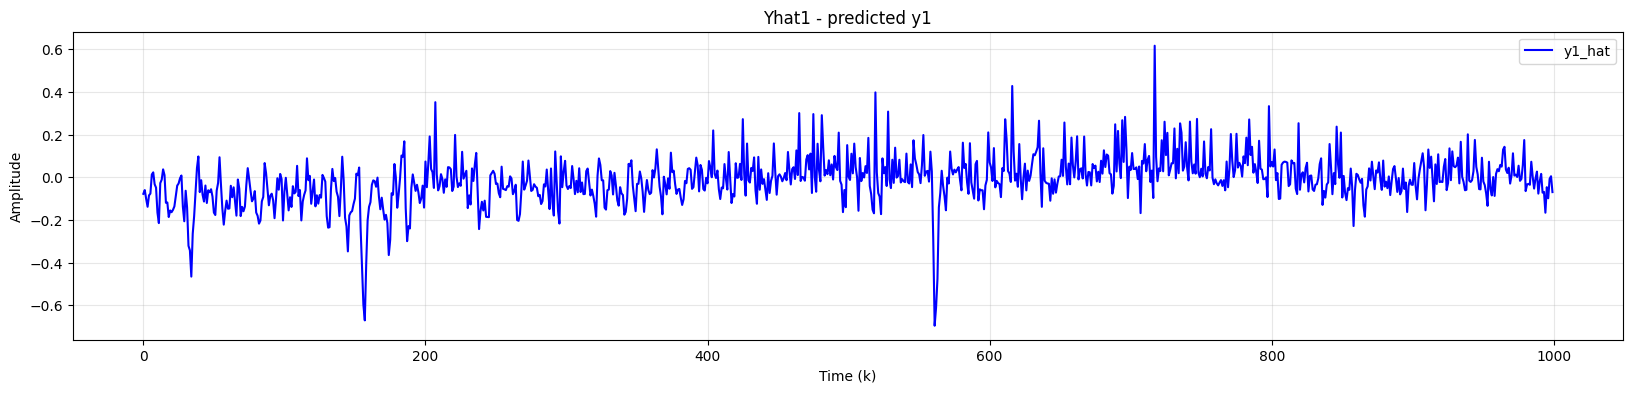

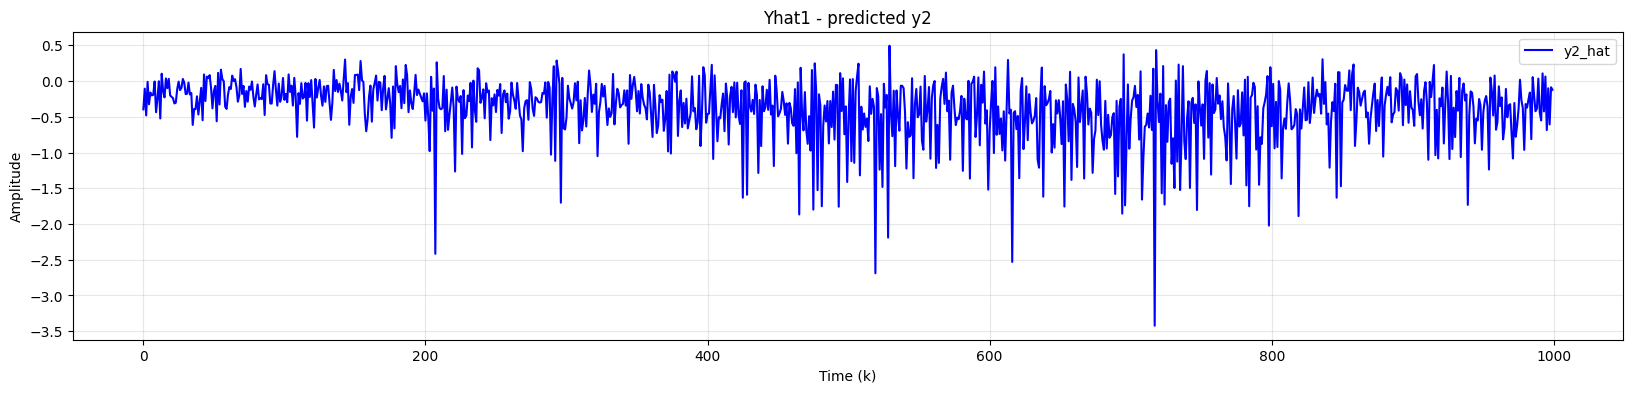

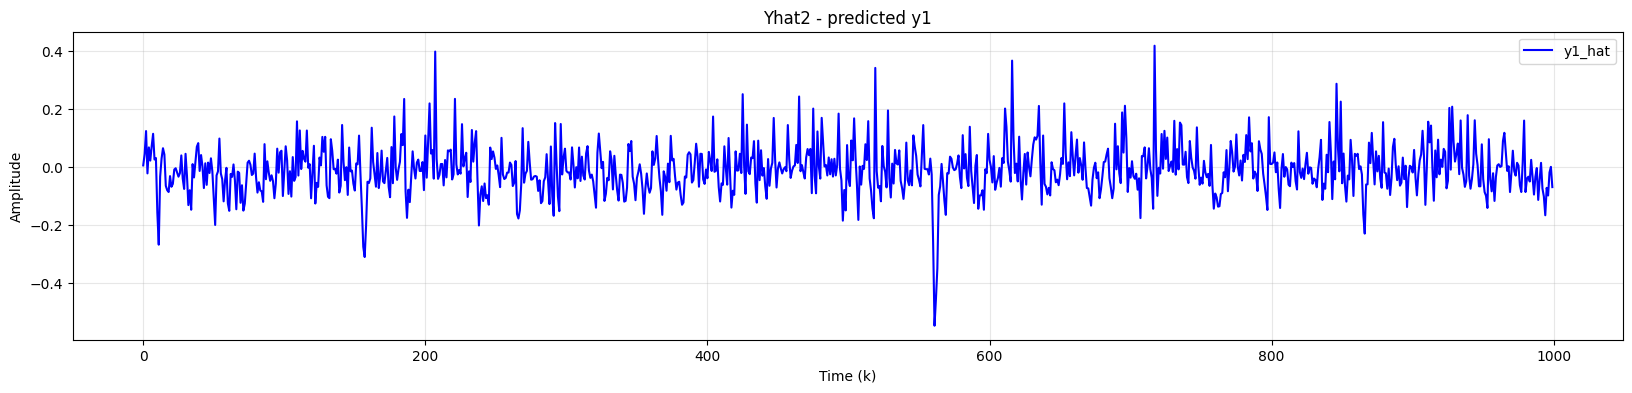

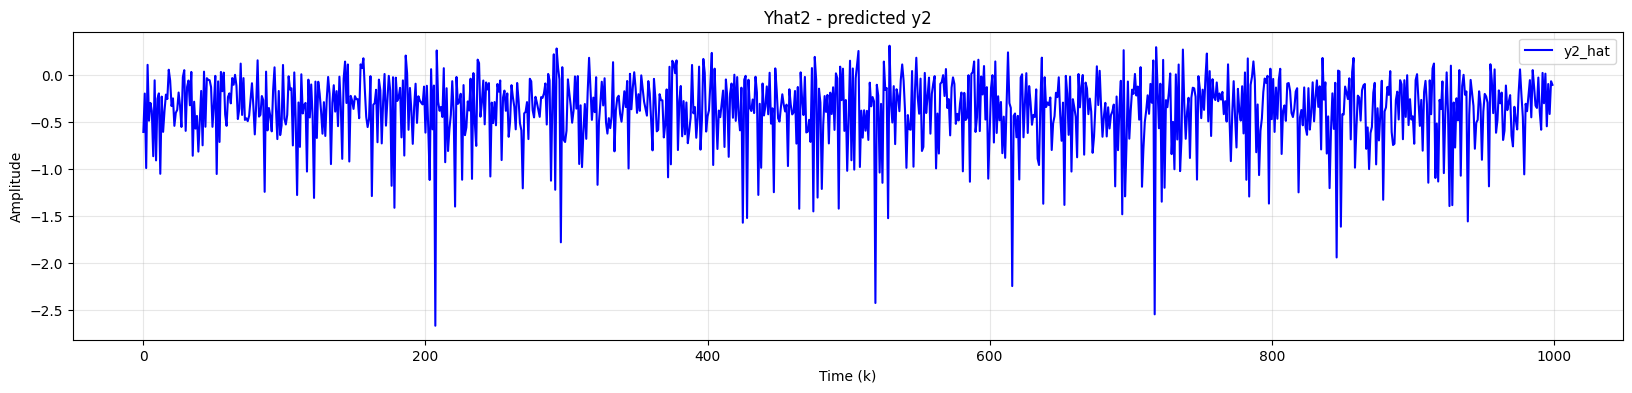

In [121]:
# Re-train the winning model on the full training set
print(f"Re-training {winner['model']} on full Utr/Ytr...")
if winner['model'] == 'RidgeCV':
    final_model = train_mismo(Utr, Ytr, d_r, na_r, s_r)
elif winner['model'] == 'MISMO MLP':
    final_model = train_mismo_torch(Utr, Ytr, d_r, na_r, s_r,
                                    arch='mlp',
                                    hidden_sizes=(256, 128, 64),
                                    dropout=0.1,
                                    max_epochs=500,
                                    patience=40,
                                    verbose=False)
elif winner['model'] == 'MISMO LSTM':
    final_model = train_mismo_torch(Utr, Ytr, d_r, na_r, s_r,
                                    arch='lstm',
                                    lstm_hidden=128,
                                    dropout=0.1,
                                    max_epochs=500,
                                    patience=40,
                                    verbose=False)
else:
    raise ValueError(f"Unknown winner: {winner['model']}")

# Generate predictions for both test sequences
print("\nGenerating Yhat1 from Uts1...")
Yhat1 = mismo_rollout(final_model, Uts1, d_r, na_r, s_r, y_prefix=Ytr)
print(f"Yhat1 shape: {Yhat1.shape}")

print("\nGenerating Yhat2 from Uts2...")
Yhat2 = mismo_rollout(final_model, Uts2, d_r, na_r, s_r, y_prefix=Ytr)
print(f"Yhat2 shape: {Yhat2.shape}")

# Visual sanity check: predictions should look like plausible y-trajectories
plot_1(Yhat1[:, 0], title="Yhat1 - predicted y1", label="y1_hat")
plot_1(Yhat1[:, 1], title="Yhat1 - predicted y2", label="y2_hat")
plot_1(Yhat2[:, 0], title="Yhat2 - predicted y1", label="y1_hat")
plot_1(Yhat2[:, 1], title="Yhat2 - predicted y2", label="y2_hat")

### Submission

In [122]:
# Save submission with the project-mandated format
submission_path = Path('submission.npz')
np.savez(submission_path, Yhat1=Yhat1, Yhat2=Yhat2)
print(f"Saved: {submission_path.resolve()}")

# Final sanity checks per project spec
loaded = np.load(submission_path)
assert 'Yhat1' in loaded.files and 'Yhat2' in loaded.files, "Missing arrays"
assert loaded['Yhat1'].shape == (1000, 2), f"Yhat1 shape: {loaded['Yhat1'].shape}"
assert loaded['Yhat2'].shape == (1000, 2), f"Yhat2 shape: {loaded['Yhat2'].shape}"
assert not np.isnan(loaded['Yhat1']).any(), "Yhat1 has NaN"
assert not np.isnan(loaded['Yhat2']).any(), "Yhat2 has NaN"
assert not np.isinf(loaded['Yhat1']).any(), "Yhat1 has Inf"
assert not np.isinf(loaded['Yhat2']).any(), "Yhat2 has Inf"

print("\n=== submission.npz validation ===")
for name in ['Yhat1', 'Yhat2']:
    arr = loaded[name]
    print(f"{name}: shape={arr.shape}, "
          f"min={arr.min():.3f}, max={arr.max():.3f}, "
          f"mean={arr.mean():.3f}, std={arr.std():.3f}")

print(f"\nFinal model used: {winner['model']}")
print(f"Selected parameters: d={d_r}, na={na_r}, s={s_r}")
print(f"Validation NMSE on internal split: {winner['nmse']:.5f}")

Saved: C:\Users\kamil\Desktop_new\Local\Universidad\F422-Proyecto\project-2025-2026-team-10-1\notebooks\submission.npz

=== submission.npz validation ===
Yhat1: shape=(1000, 2), min=-3.424, max=0.616, mean=-0.201, std=0.369
Yhat2: shape=(1000, 2), min=-2.667, max=0.417, mean=-0.193, std=0.331

Final model used: MISMO MLP
Selected parameters: d=9, na=0, s=10
Validation NMSE on internal split: 0.39978


---

#### Step 1: Integration into a scikit-learn pipeline

Given everything we have developed in the above cells, we now want to integrate all of this logic inside a scikit-learn pipeline in order to automatize the logic and be able to apply it to various data sources. 

##### Data transformation
The first major step in the creation of a pipeline is to implement the automatization of the data transfomation logic defined above. To do this, we are going to create a custom transformer class called `LaggedTransformer`. This class is going to integrate mutliple things : the search of the best parameters $n_a, n_b, d$ and the data transformation logic as implemented in the `create_lagged_features`.

When calling the pipeline to train the model using `pipeline.fit(X,y)`, the fit function of this classed is first called and the best parameters are found and store as instance attributes. Then, the transform function is applied to the provided data given these best parameters. 

When later calling the pipeline for predictions purpose using `pipeline.predict(X_test)`, only the transform function will be applied to the test data, using the parameters found during the training phase. However, let us note that two situations are possibles :

1. **Validation phase**: ground-truth values $y_1(k), y_2(k)$ are known and the pipeline is used to generate and compare predicitions with these values. 
2. **Test phase**: the outputs $y_1(k), y_2(k)$ are not known in advance, we only kow the values of the inputs $u_1(k), u_2(k)$. In this case, we need to pay attention to initialize all outputs values to zeros in order to later fill them with model predictions.

`Note`: In what we did before, the starting NaNs values created by the shifts of the original dataframe were directly replaced by zeros inside the function. In the pipeline, this is not necessary. Indeed, this is going to be automatically done using SimpleImputer as the imputer to fill NaNs values with zeros. 

In [99]:
class ParameterSelector:
    def __init__(self, u_train: np.ndarray, y_train: np.ndarray, val_ratio: float = 0.30, random_state: int = 42) -> None:
        self.u_train = np.asarray(u_train, dtype=float)
        self.y_train = np.asarray(y_train, dtype=float)
        self.val_ratio = float(val_ratio)
        self.random_state = int(random_state)

        if self.u_train.ndim != 2 or self.y_train.ndim != 2:
            raise ValueError('u_train and y_train must be 2D arrays.')
        if self.u_train.shape[0] != self.y_train.shape[0]:
            raise ValueError('u_train and y_train must have the same number of rows.')
        if self.y_train.shape[1] != 2:
            raise ValueError('ParameterSelector expects exactly 2 output channels.')
        if not (0.0 < self.val_ratio < 1.0):
            raise ValueError('val_ratio must be in (0, 1).')

    @staticmethod
    def cross_correlation(y: np.ndarray, u: np.ndarray, max_lag: int = 40) -> Tuple[np.ndarray, np.ndarray]:
        return cross_correlation(y=y, u=u, max_lag=max_lag)

    def estimate_delay_candidates(
        self,
        max_lag: int = 40,
        max_d: int = 10,
        baseline_stop: int = 4,
        around_median_radius: int = 2,
        around_min_radius: int = 1,
    ) -> Tuple[List[int], Dict[Tuple[int, int], int]]:
        nu, ny = self.u_train.shape[1], self.y_train.shape[1]
        peak_lags: Dict[Tuple[int, int], int] = {}

        for i in range(nu):
            for j in range(ny):
                lags, corr = self.cross_correlation(self.y_train[:, j], self.u_train[:, i], max_lag=max_lag)
                pos_mask = lags >= 0
                if np.any(pos_mask):
                    peak = int(lags[pos_mask][np.argmax(np.abs(corr[pos_mask]))])
                else:
                    peak = 0
                peak_lags[(i, j)] = peak

        values = np.array(list(peak_lags.values()), dtype=int)
        d_min = int(values.min()) if values.size else 0
        d_med = int(np.median(values)) if values.size else 0

        baseline = set(range(0, max(1, baseline_stop + 1)))
        around_med = set(range(max(0, d_med - around_median_radius), d_med + around_median_radius + 2))
        around_min = set(range(max(0, d_min - around_min_radius), d_min + around_min_radius + 2))
        d_candidates = sorted(d for d in (baseline | around_med | around_min) if 0 <= d <= max_d)

        if not d_candidates:
            d_candidates = [0, 1, 2]

        return d_candidates, peak_lags

    def _make_single_output_model(self, model_name: str, model_params: Optional[Dict[str, Any]] = None):
        params = dict(model_params or {})
        name = model_name.lower()

        if name == 'ridge':
            alpha = float(params.get('alpha', 1.0))
            return make_pipeline(StandardScaler(), Ridge(alpha=alpha))

        if name == 'knn':
            n_neighbors = int(params.get('n_neighbors', 7))
            return make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=n_neighbors))

        if name in ('rf', 'random_forest', 'randomforest'):
            rf_params = {
                'n_estimators': int(params.get('n_estimators', 300)),
                'max_depth': params.get('max_depth', None),
                'min_samples_leaf': int(params.get('min_samples_leaf', 1)),
                'random_state': self.random_state,
            }
            return RandomForestRegressor(**rf_params)

        raise ValueError(f"Unsupported model_name '{model_name}'.")

    def fit_two_output_models(
        self,
        x_train: np.ndarray,
        y_train: np.ndarray,
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
    ):
        model_y1 = self._make_single_output_model(model_name, model_params)
        model_y2 = self._make_single_output_model(model_name, model_params)
        model_y1.fit(x_train, y_train[:, 0])
        model_y2.fit(x_train, y_train[:, 1])
        return model_y1, model_y2

    def recursive_rollout(
        self,
        u: np.ndarray,
        model_y1,
        model_y2,
        d: int,
        na: int,
        nb: int,
        y_prefix: Optional[np.ndarray] = None,
    ) -> np.ndarray:
        return recursive_rollout_mimo(
            U=u,
            model_y1=model_y1,
            model_y2=model_y2,
            d=d,
            na=na,
            nb=nb,
            y_prefix=y_prefix,
        )

    def evaluate_config(
        self,
        d: int,
        na: int,
        nb: int,
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
        min_samples: int = 30,
    ) -> Optional[Dict[str, Any]]:
        X, Y_next = build_mimo_features(self.u_train, self.y_train, d=d, na=na, nb=nb)
        if X.size == 0:
            return None

        horizon = max(d + na, nb)
        split_idx, _, train_mask, val_mask = build_masks(len(self.y_train), horizon, self.val_ratio)

        if train_mask.sum() < min_samples or val_mask.sum() < min_samples:
            return None

        model_y1, model_y2 = self.fit_two_output_models(
            X[train_mask], Y_next[train_mask], model_name=model_name, model_params=model_params
        )

        Y_val_pred = np.column_stack([
            model_y1.predict(X[val_mask]),
            model_y2.predict(X[val_mask]),
        ])

        Y_roll = self.recursive_rollout(
            self.u_train, model_y1, model_y2, d=d, na=na, nb=nb, y_prefix=self.y_train[:split_idx]
        )
        Y_val_rec = Y_roll[split_idx:]

        return {
            'd': int(d),
            'na': int(na),
            'nb': int(nb),
            'model_name': str(model_name),
            'model_params': dict(model_params or {}),
            'split_idx': int(split_idx),
            'n_features': int(X.shape[1]),
            'n_train': int(train_mask.sum()),
            'n_val': int(val_mask.sum()),
            'one_step_nmse': float(nmse(Y_next[val_mask], Y_val_pred)),
            'one_step_rmse': float(rmse(Y_next[val_mask], Y_val_pred)),
            'recursive_nmse': float(nmse(self.y_train[split_idx:], Y_val_rec)),
            'recursive_rmse': float(rmse(self.y_train[split_idx:], Y_val_rec)),
        }

    @staticmethod
    def _sort_cols(objective: str) -> List[str]:
        options = {
            'one_step_nmse': ['one_step_nmse', 'recursive_nmse', 'n_features'],
            'recursive_nmse': ['recursive_nmse', 'one_step_nmse', 'n_features'],
        }
        if objective not in options:
            raise ValueError("objective must be either 'one_step_nmse' or 'recursive_nmse'.")
        return options[objective]

    def search(
        self,
        order_grid: Dict[str, Iterable[int]],
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
        objective: str = 'recursive_nmse',
        min_samples: int = 30,
    ) -> pd.DataFrame:
        rows: List[Dict[str, Any]] = []
        for cfg in ParameterGrid(order_grid):
            row = self.evaluate_config(
                d=int(cfg['d']),
                na=int(cfg['na']),
                nb=int(cfg['nb']),
                model_name=model_name,
                model_params=model_params,
                min_samples=min_samples,
            )
            if row is not None:
                rows.append(row)

        if not rows:
            return pd.DataFrame()

        sort_cols = self._sort_cols(objective)
        return pd.DataFrame(rows).sort_values(sort_cols).reset_index(drop=True)

    def search_with_model_spaces(
        self,
        order_grid: Dict[str, Iterable[int]],
        model_spaces: Dict[str, List[Dict[str, Any]]],
        objective: str = 'recursive_nmse',
        min_samples: int = 30,
        verbose: bool = False,
        progress_every: int = 25,
        max_evals: Optional[int] = None,
        time_budget_seconds: Optional[float] = None,
        early_stop_nmse: Optional[float] = None,
    ) -> pd.DataFrame:
        sort_cols = self._sort_cols(objective)
        objective_col = sort_cols[0]
        grid = list(ParameterGrid(order_grid))

        rows: List[Dict[str, Any]] = []
        eval_count = 0
        t0 = time.perf_counter()
        stop = False

        for model_name, param_list in model_spaces.items():
            for params in (param_list or [{}]):
                for cfg in grid:
                    if max_evals is not None and eval_count >= int(max_evals):
                        stop = True
                        break
                    if time_budget_seconds is not None and (time.perf_counter() - t0) >= float(time_budget_seconds):
                        stop = True
                        break

                    row = self.evaluate_config(
                        d=int(cfg['d']),
                        na=int(cfg['na']),
                        nb=int(cfg['nb']),
                        model_name=model_name,
                        model_params=params,
                        min_samples=min_samples,
                    )
                    eval_count += 1

                    if row is not None:
                        rows.append(row)
                        if early_stop_nmse is not None and float(row[objective_col]) <= float(early_stop_nmse):
                            stop = True
                            break

                    if verbose and (eval_count == 1 or eval_count % max(1, int(progress_every)) == 0):
                        best_so_far = min((r[objective_col] for r in rows), default=np.inf)
                        elapsed_min = (time.perf_counter() - t0) / 60.0
                        print(f"[search] evals={eval_count} elapsed={elapsed_min:.1f}m best_{objective_col}={best_so_far:.4f}")

                if stop:
                    break
            if stop:
                break

        if not rows:
            return pd.DataFrame()

        return pd.DataFrame(rows).sort_values(sort_cols).reset_index(drop=True)

    @staticmethod
    def best_config(results: pd.DataFrame) -> Dict[str, Any]:
        if results.empty:
            raise ValueError('results is empty; cannot extract best configuration.')
        row = results.iloc[0]
        params = row.get('model_params', {})
        return {
            'd': int(row['d']),
            'na': int(row['na']),
            'nb': int(row['nb']),
            'model_name': str(row.get('model_name', 'ridge')),
            'model_params': dict(params) if isinstance(params, dict) else {},
        }

    def fit_full_models(
        self,
        d: int,
        na: int,
        nb: int,
        model_name: str = 'ridge',
        model_params: Optional[Dict[str, Any]] = None,
    ):
        X_all, Y_next = build_mimo_features(self.u_train, self.y_train, d=d, na=na, nb=nb)
        if X_all.size == 0:
            raise ValueError('No samples available for full training with the selected orders.')
        model_y1, model_y2 = self.fit_two_output_models(
            X_all, Y_next, model_name=model_name, model_params=model_params
        )
        return model_y1, model_y2, {'n_samples': int(X_all.shape[0]), 'n_features': int(X_all.shape[1])}

In [100]:
class LaggedTransformer(BaseEstimator, TransformerMixin):
    """
    Custom transformer for converting a raw NARX DataFrame into lagged features.
    """
    
    def __init__(
        self,
        n_a=None,
        n_b=None,
        d=None,
        order_grid: Optional[Dict[str, Iterable[int]]] = None,
        selection_model: str = 'ridge',
        selection_model_params: Optional[Dict[str, Any]] = None,
        selection_objective: str = 'recursive_nmse',
        val_ratio: float = 0.30,
        random_state: int = 42,
        min_samples: int = 30,
        max_lag: int = 40,
        max_d: int = 10,
    ):
        self.n_a = n_a
        self.n_b = n_b
        self.d = d
        self.order_grid = order_grid
        self.selection_model = selection_model
        self.selection_model_params = selection_model_params
        self.selection_objective = selection_objective
        self.val_ratio = val_ratio
        self.random_state = random_state
        self.min_samples = min_samples
        self.max_lag = max_lag
        self.max_d = max_d

    def fit(self, X, y):
        # Only called during the training phase
        if self.n_a is None or self.n_b is None or self.d is None:
            self.n_a, self.n_b, self.d = self._find_best_parameters(X, y)
        else:
            self.n_a = int(self.n_a)
            self.n_b = int(self.n_b)
            self.d = int(self.d)
        return self
   
    def transform(self, data: pd.DataFrame):
        # Called during both the training and test phases
        # This is the same logic as the create_lagged_features function

        X = data.copy()

        # During multiple-steps-ahead predicitons for the test set, y columns don't exist yet -> Initalized with zeros
        if 'y1(k)' not in X.columns:
            X['y1(k)'] = 0.0
        if 'y2(k)' not in X.columns:
            X['y2(k)'] = 0.0

        # For outputs lags, we need delay from d to d + n_a
        y1_lags, y2_lags = [], []

        for i in range(self.d, self.d + self.n_a + 1):
            y1_col = 'y1(k)' if i == 0 else f'y1(k-{i})'
            y2_col = 'y2(k)' if i == 0 else f'y2(k-{i})'

            if i >= 0:
                X[y1_col] = X['y1(k)'].shift(i)
                X[y2_col] = X['y2(k)'].shift(i)

            y1_lags.append(y1_col)
            y2_lags.append(y2_col)

        # For inputs lags, we need the current time step k, then k-1 up to k-n_b
        u1_lags, u2_lags = ['u1(k)'], ['u2(k)']

        for i in range(1, self.n_b + 1):
            u1_col, u2_col = f'u1(k-{i})', f'u2(k-{i})'

            X[u1_col] = X['u1(k)'].shift(i)
            X[u2_col] = X['u2(k)'].shift(i)

            u1_lags.append(u1_col)
            u2_lags.append(u2_col)

        # Small modifictaiton to have a proper order 
        final_column_order = y1_lags + y2_lags + u1_lags + u2_lags
        return X[final_column_order]
    
    def _find_best_parameters(self, data, y):
        X_df = data if isinstance(data, pd.DataFrame) else pd.DataFrame(data)
        if 'u1(k)' not in X_df.columns or 'u2(k)' not in X_df.columns:
            raise ValueError("Expected input columns 'u1(k)' and 'u2(k)' in X.")
        u_train = X_df[['u1(k)', 'u2(k)']].to_numpy(dtype=float)

        if y is None:
            if 'y1(k)' not in X_df.columns or 'y2(k)' not in X_df.columns:
                raise ValueError("y is None and X does not contain 'y1(k)'/'y2(k)'.")
            y_train = X_df[['y1(k)', 'y2(k)']].to_numpy(dtype=float)
        else:
            y_train = np.asarray(y, dtype=float)
            if y_train.ndim == 1:
                y_train = y_train.reshape(-1, 1)

        selector = ParameterSelector(
            u_train=u_train,
            y_train=y_train,
            val_ratio=self.val_ratio,
            random_state=self.random_state,
        )

        if self.order_grid is None:
            d_candidates, _ = selector.estimate_delay_candidates(
                max_lag=self.max_lag,
                max_d=self.max_d,
            )
            order_grid = {
                'd': d_candidates,
                'na': list(range(1, 9)),
                'nb': list(range(1, 7)),
            }
        else:
            order_grid = self.order_grid

        results = selector.search(
            order_grid,
            model_name=self.selection_model,
            model_params=self.selection_model_params,
            objective=self.selection_objective,
            min_samples=self.min_samples,
        )
        if results.empty:
            raise RuntimeError('Parameter selection returned no valid configuration.')

        best = selector.best_config(results)
        self.best_orders_ = best
        self.selection_results_ = results
        return int(best['na']), int(best['nb']), int(best['d'])

##### Selection of the best model (classical + deep learning)

We have defined how the pipeline handles data transformation. Now, we want the same pipeline to train, compare, and evaluate both classical models and deep-learning models, then select the best one with its best hyperparameters.

To implement this, we use a custom `ModelSelector` class. It still uses `TimeSeriesSplit` and `GridSearchCV` for classical models, and it also evaluates deep models (MLP/LSTM) through the same selection workflow.

When the pipeline is called with `pipeline.fit`, data are transformed by `LaggedTransformer`, then `ModelSelector.fit` chooses the best model among all candidates.

When the pipeline is called with `pipeline.predict`, test data are transformed in the same way, and predictions are produced by the best model selected during training.

In [101]:
def _rollout_score(model, X_val_df, y_val_np, d, na, max_explosion=1e3):
    """
    Multi-step (rollout) NMSE for a candidate model.
    Treats *X_val_df* as RAW (un-scaled) features so we can write predicted
    outputs back into the lag columns directly. Each candidate model is
    expected to embed its own StandardScaler if it needs one.
    """
    n_steps = len(X_val_df)
    preds = np.zeros((n_steps, 2))
    X_sim = X_val_df.copy()
    idx = X_val_df.index

    for k in range(n_steps):
        for lag in range(d, d + na + 1):
            prev_k = k - lag
            if prev_k >= 0:
                y1_col = 'y1(k)' if lag == 0 else f'y1(k-{lag})'
                y2_col = 'y2(k)' if lag == 0 else f'y2(k-{lag})'
                if y1_col in X_sim.columns:
                    X_sim.at[idx[k], y1_col] = preds[prev_k, 0]
                if y2_col in X_sim.columns:
                    X_sim.at[idx[k], y2_col] = preds[prev_k, 1]

        row = X_sim.loc[[idx[k]]]
        try:
            preds[k] = np.asarray(model.predict(row)).reshape(-1)[:2]
        except Exception:
            return np.inf, True

        if not np.all(np.isfinite(preds[k])) or np.max(np.abs(preds[k])) > max_explosion:
            return np.inf, True

    score = nmse(y_val_np, preds)
    diverged = (not np.isfinite(score)) or score > 5.0
    return score, diverged

In [102]:
class ModelSelector(BaseEstimator, RegressorMixin):
    """
    Selects the best NARX model by ROLLOUT (multi-step) NMSE on the last
    TimeSeriesSplit fold — the metric that actually matches the project.

    Each candidate embeds its own StandardScaler so the input X may stay
    in raw units (necessary for the rollout to write predictions back into
    lag columns).
    """

    def __init__(
        self,
        deep_candidates: Optional[List[Dict[str, Any]]] = None,
        d: Optional[int] = None,
        na: Optional[int] = None,
        random_state: int = 42,
        verbose: bool = True,
    ):
        self.deep_candidates = deep_candidates
        self.d = d
        self.na = na
        self.random_state = random_state
        self.verbose = verbose

    def fit(self, X, y):
        d  = self.d  if self.d  is not None else 0
        na = self.na if self.na is not None else 0

        # Reconstruct column names so rollout can find lag columns
        y1_cols = ['y1(k)' if i == 0 else f'y1(k-{i})' for i in range(d, d + na + 1)]
        y2_cols = ['y2(k)' if i == 0 else f'y2(k-{i})' for i in range(d, d + na + 1)]
        n_y = len(y1_cols) + len(y2_cols)
        n_u = X.shape[1] - n_y
        u_cols = [f'u_feat{i}' for i in range(n_u)]
        all_cols = y1_cols + y2_cols + u_cols

        X_arr = np.asarray(X)
        X_df  = pd.DataFrame(X_arr, columns=all_cols)
        y_np  = np.asarray(y)
        if y_np.ndim == 1:
            y_np = y_np.reshape(-1, 1)

        tscv = TimeSeriesSplit(n_splits=5)
        last_train_idx, last_val_idx = list(tscv.split(X_df))[-1]
        X_tr_df = X_df.iloc[last_train_idx].reset_index(drop=True)
        X_val_df = X_df.iloc[last_val_idx].reset_index(drop=True)
        y_tr_np  = y_np[last_train_idx]
        y_val_np = y_np[last_val_idx]

        candidates: List[Dict[str, Any]] = []

        def evaluate(name, builder, params, kind):
            """`builder` is a callable returning a fresh estimator instance."""
            try:
                model = builder()
                model.fit(X_tr_df, y_tr_np)
                score, diverged = _rollout_score(model, X_val_df, y_val_np, d=d, na=na)
            except Exception as exc:
                model, score, diverged = None, np.inf, True
                if self.verbose:
                    print(f'  {name:<25s} FAILED: {type(exc).__name__}: {str(exc)[:80]}')
                    return
            if self.verbose:
                tag = '  DIVERGED' if diverged else ''
                print(f'  {name:<25s} rollout NMSE = {score:.4f}{tag}')
            candidates.append({
                'name': name, 'score': float(score),
                'builder': builder, 'model': model,
                'params': params, 'kind': kind,
                'diverged': diverged,
            })

        # ---- Linear models (Ridge with light regularisation) ----
        if self.verbose: print('\nLinear / Ridge candidates...')
        evaluate('Linear Regression',
                 lambda: make_pipeline(StandardScaler(), LinearRegression()),
                 {}, 'classical')
        for alpha in [0.1, 1.0, 10.0, 100.0]:
            evaluate(f'Ridge(α={alpha})',
                     lambda a=alpha: make_pipeline(StandardScaler(), Ridge(alpha=a)),
                     {'alpha': alpha}, 'classical')

        # ---- KNN ----
        if self.verbose: print('\nKNN candidates...')
        for k_n in [3, 5, 10, 20]:
            evaluate(f'KNN(k={k_n})',
                     lambda kn=k_n: make_pipeline(StandardScaler(),
                                                  KNeighborsRegressor(n_neighbors=kn)),
                     {'n_neighbors': k_n}, 'classical')

        # ---- Random Forest (conservative grid: deep RFs tend to diverge) ----
        if self.verbose: print('\nRandom Forest candidates (conservative grid)...')
        for n_est in [100, 300]:
            for max_d in [5, 10, None]:
                for msl in [2, 5]:
                    evaluate(
                        f'RF(n={n_est}, depth={max_d}, msl={msl})',
                        lambda ne=n_est, md=max_d, ml=msl: RandomForestRegressor(
                            n_estimators=ne, max_depth=md, min_samples_leaf=ml,
                            random_state=self.random_state, n_jobs=-1,
                        ),
                        {'n_estimators': n_est, 'max_depth': max_d,
                         'min_samples_leaf': msl},
                        'classical'
                    )

        # ---- Deep models (TorchNARXRegressor handles its own scaling) ----
        if _TORCH_AVAILABLE:
            if self.verbose: print('\nDeep model candidates...')
            deep_spaces = self.deep_candidates or [
                {'name': 'Deep MLP small',
                 'params': {'arch': 'mlp', 'hidden_sizes': (64, 32),
                            'max_epochs': 200, 'patience': 20, 'dropout': 0.10}},
                {'name': 'Deep MLP large',
                 'params': {'arch': 'mlp', 'hidden_sizes': (256, 128, 64),
                            'max_epochs': 300, 'patience': 25, 'dropout': 0.15}},
            ]
            for spec in deep_spaces:
                params = dict(spec.get('params') or {})
                params.setdefault('random_state', self.random_state)
                evaluate(spec.get('name', 'Deep Model'),
                         lambda p=params: TorchNARXRegressor(**p),
                         params, 'deep')
        else:
            if self.verbose: print('\nDeep models skipped: PyTorch not available.')

        # ---- Pick best by lowest rollout NMSE; prefer non-diverged ----
        if not candidates:
            raise RuntimeError('No candidate models were evaluated.')

        non_diverged = [c for c in candidates if not c['diverged']]
        pool = non_diverged if non_diverged else candidates
        best = min(pool, key=lambda c: c['score'])

        # Refit the winner on ALL training data
        try:
            final_model = best['builder']()
            final_model.fit(X_df, y_np)
            best['model'] = final_model
        except Exception as exc:
            if self.verbose:
                print(f'⚠ refit on full data failed for {best["name"]}: {exc}')

        self.best_name_   = best['name']
        self.best_params_ = best.get('params', {})
        self.best_score_  = float(best['score'])
        self.best_model_  = best['model']
        self.candidates_  = candidates

        if self.verbose:
            print('\n── Selection Summary (sorted by rollout NMSE) ──')
            for c in sorted(candidates, key=lambda x: x['score']):
                tag = '  DIVERGED' if c['diverged'] else ''
                print(f"  {c['name']:<25s}  NMSE={c['score']:.4f}{tag}")
            print(f'\n>>> Best: {self.best_name_}  '
                  f'(rollout NMSE = {self.best_score_:.4f})')

        return self

    def predict(self, X):
        return self.best_model_.predict(X)


#### Step 2. Definition of the pipeline

The pipeline remains simple in structure: transformer, imputer, scaler, model.

The important point is that `LaggedTransformer` now performs parameter selection (`d`, `n_a`, `n_b`) during training, and `ModelSelector` now evaluates both classical and deep-learning candidates before choosing the final model.

In [103]:
def make_narx_pipeline(d=None, n_a=None, n_b=None, verbose=True):
    """
    NARX pipeline with rollout-aware model selection.

    Steps:
      1. LaggedTransformer  – build lag features (and optionally search d/n_a/n_b)
      2. SimpleImputer      – fill the leading NaNs introduced by shifts
      3. ModelSelector      – pick best candidate by rollout NMSE
                              (each candidate has its own StandardScaler)
    """
    transformer = LaggedTransformer(d=d, n_a=n_a, n_b=n_b)
    pipe = Pipeline([
        ('transformer', transformer),
        ('imputer',     SimpleImputer(strategy='constant', fill_value=0.0)),
        ('model',       ModelSelector(verbose=verbose)),
    ])
    # Ensure ModelSelector knows the lag parameters before its fit.
    original_fit = pipe.fit
    def fit_with_lag_propagation(X, y=None, **kw):
        pipe.named_steps['transformer'].fit(X, y)
        pipe.named_steps['model'].d  = pipe.named_steps['transformer'].d
        pipe.named_steps['model'].na = pipe.named_steps['transformer'].n_a
        return original_fit(X, y, **kw)
    pipe.fit = fit_with_lag_propagation
    return pipe

In [104]:
# Default pipeline used by Task-3/4 demonstrations
pipeline = make_narx_pipeline()

Here is steps by steps the way the pipeline works : 

##### Training phase: `pipeline.fit(X_train,y_train)`

1. The best parameters $n_a, n_b$ and $d$ are found and stored from the fit function in the LaggedTransformer class. 
2. Using these parameter values, the appropriate transformation is applied to the data via the transform function from the same class.
3. Starting NaN values created by the transformation are replaced with zeros using the SimpleImputer. 
4. A basic scaling is applied to the transformed data using StandardScaler. 
5. The best model (classical or deep) and its best hyperparameters are obtained from the ModelSelector class. 

##### Test/Validation phase: `pipeline.predict(X_test)`

1. Using the best parameters $n_a, n_b$ and $d$ found during the training phase, the appropriate transformation is applied to the data. If no output values are available (test phase), they are initialized with zeros.
2. The SimpleImputer and StandardScaler are applied in the same way as in the training phase. 
3. The best model obtained from the ModelSelector class in the training phase is used to make predictions based on the transformed test data.

### Step 3. Tests of the pipeline `THIS SECTION STILL NEEDS TO BE DONE`

Now that oour pipeline has been implemented, we can obviously test it in the case of teh NARX1 and NARX2 models.

#### Test for the NARX1 model

Let us start with the NARX1 case. In this casse, we already defined the data and targets vectors to be used when developping the logic for the pipeline implementation. Calling and training the pipeline is tehrefore direct. 

In [105]:
def make_pipeline_df(U, Y):
    """
    Convert raw numpy arrays (U: (N, n_u), Y: (N, 2)) into the DataFrame format
    expected by LaggedTransformer: columns u1(k), u2(k), y1(k), y2(k).
    """
    U2 = np.asarray(U)
    Y2 = np.asarray(Y)
    if U2.ndim == 1:
        U2 = U2.reshape(-1, 1)
    if U2.shape[1] == 1:                         # NARX1: pad u2 with zeros
        U2 = np.column_stack([U2, np.zeros(len(U2))])
    return pd.DataFrame(
        np.column_stack([U2, Y2]),
        columns=['u1(k)', 'u2(k)', 'y1(k)', 'y2(k)']
    )

In [106]:
df_pipe_narx1 = make_pipeline_df(narx1_u_tr, narx1_y_tr)
y_pipe_narx1  = (
    df_pipe_narx1[['y1(k)', 'y2(k)']]
    .shift(-1).rename(columns={'y1(k)': 'y1(k+1)', 'y2(k)': 'y2(k+1)'})
    .iloc[:-1].reset_index(drop=True)
)
X_pipe_narx1 = df_pipe_narx1.iloc[:-1].reset_index(drop=True)

In [107]:
df_pipe_narx2 = make_pipeline_df(narx2_U_tr, narx2_y_tr)
y_pipe_narx2  = (
    df_pipe_narx2[['y1(k)', 'y2(k)']]
    .shift(-1).rename(columns={'y1(k)': 'y1(k+1)', 'y2(k)': 'y2(k+1)'})
    .iloc[:-1].reset_index(drop=True)
)
X_pipe_narx2 = df_pipe_narx2.iloc[:-1].reset_index(drop=True)

In [108]:
# Use the factory; supply the lags found in Task 2 so it skips the search.
d1  = best_n1_mimo['d']
na1 = best_n1_mimo['na']
nb1 = best_n1_mimo['nb']

pipeline_NARX1 = make_narx_pipeline(d=d1, n_a=na1, n_b=nb1)

print('Fitting pipeline on NARX1...')
pipeline_NARX1.fit(X_pipe_narx1, y_pipe_narx1)

Fitting pipeline on NARX1...

Linear / Ridge candidates...
  Linear Regression         rollout NMSE = 16.3020  DIVERGED
  Ridge(α=0.1)              rollout NMSE = 11.7849  DIVERGED
  Ridge(α=1.0)              rollout NMSE = 2.6710
  Ridge(α=10.0)             rollout NMSE = 0.4667
  Ridge(α=100.0)            rollout NMSE = 0.1438

KNN candidates...
  KNN(k=3)                  rollout NMSE = 0.1553
  KNN(k=5)                  rollout NMSE = 0.1658
  KNN(k=10)                 rollout NMSE = 0.1684
  KNN(k=20)                 rollout NMSE = 0.1667

Random Forest candidates (conservative grid)...
  RF(n=100, depth=5, msl=2) rollout NMSE = 0.4630
  RF(n=100, depth=5, msl=5) rollout NMSE = 0.4592
  RF(n=100, depth=10, msl=2) rollout NMSE = 0.4029
  RF(n=100, depth=10, msl=5) rollout NMSE = 0.4192
  RF(n=100, depth=None, msl=2) rollout NMSE = 0.3995
  RF(n=100, depth=None, msl=5) rollout NMSE = 0.4191
  RF(n=300, depth=5, msl=2) rollout NMSE = 0.4637
  RF(n=300, depth=5, msl=5) rollout NMSE = 

,steps,"[('transformer', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,n_a,2
,n_b,6
,d,1
,order_grid,None
,selection_model,'ridge'
,selection_model_params,None
,selection_objective,'recursive_nmse'


In [109]:
d2  = best_n2_mimo['d']
na2 = best_n2_mimo['na']
nb2 = best_n2_mimo['nb']

pipeline_NARX2 = make_narx_pipeline(d=d2, n_a=na2, n_b=nb2)
print('\nFitting pipeline on NARX2...')
pipeline_NARX2.fit(X_pipe_narx2, y_pipe_narx2)


Fitting pipeline on NARX2...

Linear / Ridge candidates...
  Linear Regression         rollout NMSE = 0.0616
  Ridge(α=0.1)              rollout NMSE = 0.0616
  Ridge(α=1.0)              rollout NMSE = 0.0616
  Ridge(α=10.0)             rollout NMSE = 0.0621
  Ridge(α=100.0)            rollout NMSE = 0.0838

KNN candidates...
  KNN(k=3)                  rollout NMSE = 0.0983
  KNN(k=5)                  rollout NMSE = 0.0953
  KNN(k=10)                 rollout NMSE = 0.0871
  KNN(k=20)                 rollout NMSE = 0.0925

Random Forest candidates (conservative grid)...
  RF(n=100, depth=5, msl=2) rollout NMSE = 0.0756
  RF(n=100, depth=5, msl=5) rollout NMSE = 0.0754
  RF(n=100, depth=10, msl=2) rollout NMSE = 0.0716
  RF(n=100, depth=10, msl=5) rollout NMSE = 0.0715
  RF(n=100, depth=None, msl=2) rollout NMSE = 0.0716
  RF(n=100, depth=None, msl=5) rollout NMSE = 0.0715
  RF(n=300, depth=5, msl=2) rollout NMSE = 0.0753
  RF(n=300, depth=5, msl=5) rollout NMSE = 0.0749
  RF(n=300, de

,steps,"[('transformer', ...), ('imputer', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,n_a,0
,n_b,0
,d,1
,order_grid,None
,selection_model,'ridge'
,selection_model_params,None
,selection_objective,'recursive_nmse'


#### Multiple-Steps-Ahead Prediction

Once the pipeline is trained, generating predictions beyond a single step requires a dedicated autoregressive loop. Indeed, `pipeline.predict()` alone is not sufficient here: it expects a feature matrix built from known past outputs, which are unavailable beyond the first step when no ground-truth is provided.

The `multiple_steps_ahead_pipeline` function addresses this by maintaining a rolling buffer of size `window = max(d + n_a, n_b) + 3`, just large enough to cover all the lags the
`LaggedTransformer` needs. At each step `k`:

1. The buffer is shifted, the current input `u(k)` is inserted, and the output slots are zeroed.
2. The buffer is wrapped in a temporary DataFrame and passed through the `LaggedTransformer` to extract features for the current step.
3. Those features are then passed through the `SimpleImputer` and `StandardScaler` before being fed to the fitted model.
4. The resulting prediction `ŷ(k)` is stored and written back into the buffer, so that subsequent steps can use it as a lagged output — in place of the unavailable ground truth.

An optional `y_init` argument allows pre-filling the output columns of the buffer with known values (e.g. the last few samples of the training set), ensuring a smooth transition at the boundary between training and test.

In [110]:
def multiple_steps_ahead_pipeline(pipeline, U_test, y_init=None,
                                   clip_threshold=None):
    """
    Autoregressive multi-step prediction for a fitted NARX pipeline
    (transformer → imputer → model).

    The model embeds its own StandardScaler, so we feed it raw lag features.
    """
    trans = pipeline.named_steps['transformer']
    n_a, n_b, d = trans.n_a, trans.n_b, trans.d

    n_steps = len(U_test)
    window = max(d + n_a, n_b) + 2

    # Cols: u1, u2, y1, y2 — buffer initialised to zeros (project spec)
    buf = np.zeros((window, 4))
    if y_init is not None and len(y_init) > 0:
        n_init = min(len(y_init), window - 1)
        buf[-(n_init + 1):-1, 2:] = np.asarray(y_init)[-n_init:]

    preds = np.zeros((n_steps, 2))
    u_values = U_test[['u1(k)', 'u2(k)']].values

    for k in range(n_steps):
        # Roll buffer up; insert current input
        buf = np.roll(buf, -1, axis=0)
        buf[-1, :2] = u_values[k]
        buf[-1, 2:] = 0.0

        tmp_df = pd.DataFrame(buf, columns=['u1(k)', 'u2(k)', 'y1(k)', 'y2(k)'])
        feat = trans.transform(tmp_df).iloc[[-1]]
        feat_imp = pipeline.named_steps['imputer'].transform(feat)
        y_hat = pipeline.named_steps['model'].predict(feat_imp)[0]

        if clip_threshold is not None:
            y_hat = np.clip(y_hat, -clip_threshold, clip_threshold)

        preds[k] = y_hat
        buf[-1, 2:] = y_hat

    return preds

## Task 4. Deep Learning approach 
At this point we have a solid sense of what linear and tree-based models can do.
The natural next question is whether a neural network can close the remaining gap ,
not by throwing away the NARX structure we already built, but by keeping the same
lag-based features and replacing the final regression step with something more powerful.

The lag features already encode the relevant history of the system.
A neural net on top of those features should pick up the nonlinear interaction terms
that OLS misses and generalise more smoothly than a random forest.

We test four architectures:

- **Residual MLP** : the new default. Skip connections let gradients flow cleanly
  through deep networks, GELU activations replace ReLU for smoother regression,
  and LayerNorm keeps each residual block well-conditioned. Consistently strong on
  tabular-style lag vectors.
- **TCN (Temporal Convolutional Network)** : dilated causal convolutions reshape the
  lag vector into a short sequence and build an exponentially growing receptive field.
  No sequential bottleneck, trains fast, great when the lag ordering matters.
- **Plain MLP** : the original version, kept as a reference point.
- **LSTM** : multi-layer this time. The recurrent state can model longer-range lag
  dependencies at the cost of slower training.

All four models share two important additions over the baseline:

**Input noise injection** (`input_noise` parameter). During recursive prediction the
model feeds its *own* predictions back as inputs, so the input distribution at test time
is slightly different from training — the predicted y values carry some error. Adding
a small Gaussian noise to the training inputs closes this gap and reliably reduces NMSE
on long rollouts. Think of it as teaching the model to handle its own mistakes.

**Ensemble over random seeds** (`n_seeds` parameter). We train the same architecture
multiple times with different seeds and average the predictions. Each model sees exactly
the same data, so there is zero extra data cost — just free variance reduction.

We scale inputs and outputs using statistics from the training split only to prevent any leakage from future observations, and split the data chronologically at 70% train and 30% validation to respect the temporal ordering of the signal. We then optimise with AdamW and gradient clipping at max_norm = 1.0 for stable updates, while a CosineAnnealingWarmRestarts schedule periodically resets the learning rate so the model can escape sharp local minima it would otherwise get trapped in during plain annealing. Validation MSE is tracked every epoch and the best checkpoint is restored once early stopping fires, ensuring the final model reflects the lowest generalisation error seen during training rather than its last state.


In [ ]:
from copy import deepcopy
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler

In [ ]:
try:
    import torch
    import torch.nn as nn
    from torch.utils.data import DataLoader, TensorDataset
    _TORCH_AVAILABLE = True
except Exception as exc:
    _TORCH_AVAILABLE = False
    _TORCH_IMPORT_ERROR = exc

In [ ]:
d  = best_n1_mimo['d']   # 1
na = best_n1_mimo['na']  # 6
nb = best_n1_mimo['nb']  # 3

X_narx1, y_narx1 = build_mimo_features(narx1_u_tr, narx1_y_tr, d=d, na=na, nb=nb)

print(f"d={d}, na={na}, nb={nb}")
print(f"X_narx1 shape: {X_narx1.shape}") 

expected = (na + 1) * 2 + (nb + 1) * narx1_u_tr.shape[1]
assert X_narx1.shape[1] == expected, f"Shape mismatch: {X_narx1.shape[1]} vs {expected}"


X_np = np.asarray(X_narx1, dtype=np.float32)
y_np = np.asarray(y_narx1, dtype=np.float32)

split_idx_dl = int(0.70 * len(X_np))
split_idx_dl = max(32, min(split_idx_dl, len(X_np) - 32))

X_train_np, X_val_np = X_np[:split_idx_dl], X_np[split_idx_dl:]
y_train_np, y_val_np = y_np[:split_idx_dl], y_np[split_idx_dl:]

x_mean = X_train_np.mean(axis=0)
x_std = X_train_np.std(axis=0)
x_std = np.where(np.abs(x_std) < 1e-12, 1.0, x_std)

X_train_sc = (X_train_np - x_mean) / x_std
X_val_sc = (X_val_np - x_mean) / x_std

d=1, na=2, nb=6
X_narx1 shape: (693, 13)


In [ ]:
from copy import deepcopy
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler

try:
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    from torch.utils.data import DataLoader, TensorDataset
    _TORCH_AVAILABLE = True
except Exception as exc:
    _TORCH_AVAILABLE = False
    _TORCH_IMPORT_ERROR = exc


if _TORCH_AVAILABLE:

    # Architecture 1: Residual MLP
    # we use skip connections so gradients flow cleanly through deep networks
    class _ResidualBlock(nn.Module):
        def __init__(self, dim, dropout=0.1):
            # we use two linear layers, a layernorm, and dropout to form one residual block
            super().__init__()
            self.fc1  = nn.Linear(dim, dim * 2)
            self.fc2  = nn.Linear(dim * 2, dim)
            self.norm = nn.LayerNorm(dim)
            self.drop = nn.Dropout(dropout)

        def forward(self, x):
            # we expand through fc1, apply gelu and dropout, compress back with fc2, then add the residual and normalize
            h = self.drop(F.gelu(self.fc1(x)))
            return self.norm(x + self.fc2(h))

    class _ResidualMLP(nn.Module):
        def __init__(self, in_dim, out_dim, hidden_dim=256, n_blocks=4, dropout=0.1):
            # we project inputs to hidden_dim, stack the residual blocks, then attach an output head
            super().__init__()
            self.proj   = nn.Sequential(nn.Linear(in_dim, hidden_dim), nn.GELU())
            self.blocks = nn.Sequential(*[_ResidualBlock(hidden_dim, dropout) for _ in range(n_blocks)])
            self.head   = nn.Linear(hidden_dim, out_dim)
            # we use a small gain so the network starts close to zero and improves from there
            nn.init.xavier_uniform_(self.head.weight, gain=0.1)
            nn.init.zeros_(self.head.bias)

        def forward(self, x):
            # we project, pass through all blocks in order, then map to the output dimension
            return self.head(self.blocks(self.proj(x)))

    # Architecture 2: Temporal Convolutional Network
    # we use dilated causal convolutions so the receptive field grows without a sequential bottleneck
    class _TCNBlock(nn.Module):
        def __init__(self, n_ch, kernel_size=3, dilation=1, dropout=0.1):
            # we use causal padding so the convolution never looks into future time steps
            super().__init__()
            pad = (kernel_size - 1) * dilation
            self.net = nn.Sequential(
                nn.ConstantPad1d((pad, 0), 0),
                nn.Conv1d(n_ch, n_ch, kernel_size, dilation=dilation),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.ConstantPad1d((pad, 0), 0),
                nn.Conv1d(n_ch, n_ch, kernel_size, dilation=dilation),
                nn.GELU(),
                nn.Dropout(dropout),
            )
            self.norm = nn.GroupNorm(1, n_ch)

        def forward(self, x):
            # we apply the conv stack and add the input back, then normalize across channels
            return self.norm(x + self.net(x))

    class _TCN(nn.Module):
        def __init__(self, in_dim, out_dim, n_channels=128, n_levels=4, kernel_size=3, dropout=0.1):
            # we double the dilation at each level so the receptive field grows exponentially with depth
            super().__init__()
            self.proj   = nn.Linear(in_dim, n_channels)
            self.blocks = nn.ModuleList([
                _TCNBlock(n_channels, kernel_size, dilation=2**i, dropout=dropout)
                for i in range(n_levels)
            ])
            self.head = nn.Linear(n_channels, out_dim)

        def forward(self, x):
            # we transpose to channel-first for conv, pass through each dilated block, and take the last time position
            h = self.proj(x).transpose(1, 2)
            for block in self.blocks:
                h = block(h)
            return self.head(h[:, :, -1])  

    # Architecture 3: Plain deep MLP (reference)
    # we keep this as a simpler baseline to see how much skip connections and normalization actually help
    class _DeepMLP(nn.Module):
        def __init__(self, in_dim, out_dim, hidden_sizes=(256, 128, 64), dropout=0.1):
            # we stack linear layers with gelu activations and dropout between each one
            super().__init__()
            layers, prev = [], in_dim
            for h in hidden_sizes:
                layers += [nn.Linear(prev, int(h)), nn.GELU(), nn.Dropout(dropout)]
                prev = int(h)
            layers.append(nn.Linear(prev, out_dim))
            self.net = nn.Sequential(*layers)

        def forward(self, x):
            # we pass the flat input through all layers in one call
            return self.net(x)

    # Architecture 4: Multi-layer LSTM with final MLP head
    # we use the recurrent state to capture longer-range lag dependencies across the input sequence
    class _DeepLSTM(nn.Module):
        def __init__(self, in_dim, out_dim, hidden_size=128, num_layers=2, dropout=0.1):
            # we only add inter-layer dropout when we have more than one lstm layer, as pytorch requires
            super().__init__()
            self.lstm = nn.LSTM(
                input_size=in_dim, hidden_size=hidden_size,
                num_layers=num_layers, batch_first=True,
                dropout=dropout if num_layers > 1 else 0.0,
            )
            self.drop = nn.Dropout(dropout)
            self.head = nn.Linear(hidden_size, out_dim)

        def forward(self, x):
            # we take only the last time step from the lstm output, apply dropout, then map to the target size
            out, _ = self.lstm(x)
            return self.head(self.drop(out[:, -1, :]))

else:
    _ResidualMLP = _TCN = _DeepMLP = _DeepLSTM = None


class TorchNARXRegressor(BaseEstimator, RegressorMixin):
    '''Wraps any of the four neural architectures in a clean sklearn-style interface.

    We added two headline additions over the baseline version:

    input_noise: injects small Gaussian noise into training inputs. During recursive
    prediction the model feeds its own outputs back, so the input distribution at test
    time is slightly corrupted.

    n_seeds: trains the same architecture n_seeds times with different random seeds
    and averages the predictions. 
    '''

    def __init__(
        self,
        arch='residual_mlp',
        hidden_sizes=(256, 128, 64),   
        hidden_dim=256,                
        n_blocks=4,                  
        lstm_hidden=128,              
        n_lstm_layers=2,               
        tcn_channels=128,              
        tcn_levels=4,                  
        seq_len=10,
        dropout=0.1,
        lr=3e-4,
        weight_decay=1e-5,
        batch_size=32,
        max_epochs=600,
        patience=60,
        val_ratio=0.2,
        input_noise=0.05,
        n_seeds=3,
        random_state=42,
        device='auto',
        verbose=False,
    ):
        self.arch          = arch
        self.hidden_sizes  = hidden_sizes
        self.hidden_dim    = hidden_dim
        self.n_blocks      = n_blocks
        self.lstm_hidden   = lstm_hidden
        self.n_lstm_layers = n_lstm_layers
        self.tcn_channels  = tcn_channels
        self.tcn_levels    = tcn_levels
        self.seq_len       = seq_len
        self.dropout       = dropout
        self.lr            = lr
        self.weight_decay  = weight_decay
        self.batch_size    = batch_size
        self.max_epochs    = max_epochs
        self.patience      = patience
        self.val_ratio     = val_ratio
        self.input_noise   = input_noise
        self.n_seeds       = n_seeds
        self.random_state  = random_state
        self.device        = device
        self.verbose       = verbose

    def _get_device(self):
        # we use gpu if it is available, otherwise we fall back to cpu
        if self.device == 'auto':
            return torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        return torch.device(self.device)

    def _seed(self, s):
        # we fix all random seeds so each training run is fully reproducible
        np.random.seed(s)
        torch.manual_seed(s)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(s)

    def _reshape_for_seq(self, X):
        '''Reshape (B, F) to (B, seq_len, feat_per_step) for LSTM and TCN.'''
        seq_len  = max(2, int(self.seq_len))
        feat_dim = int(np.ceil(X.shape[1] / seq_len))
        pad      = seq_len * feat_dim - X.shape[1]
        Xp = np.pad(X, ((0, 0), (0, pad))) if pad > 0 else X
        return Xp.reshape(X.shape[0], seq_len, feat_dim).astype(np.float32), feat_dim

    def _build_model(self, in_dim, out_dim):
        # we pick the right architecture class based on the arch string and move it to the right device
        arch = self.arch
        if arch == 'residual_mlp':
            return _ResidualMLP(in_dim, out_dim, self.hidden_dim, self.n_blocks, self.dropout).to(self._dev)
        if arch == 'mlp':
            return _DeepMLP(in_dim, out_dim, self.hidden_sizes, self.dropout).to(self._dev)
        if arch == 'lstm':
            return _DeepLSTM(in_dim, out_dim, self.lstm_hidden, self.n_lstm_layers, self.dropout).to(self._dev)
        if arch == 'tcn':
            return _TCN(in_dim, out_dim, self.tcn_channels, self.tcn_levels, dropout=self.dropout).to(self._dev)
        raise ValueError(f"Unknown arch '{arch}'. Choose: residual_mlp, mlp, lstm, tcn.")

    def _train_one(self, X, y, seed):
        '''Train a single model with the given seed. Returns a member dict.'''
        self._seed(seed)

        X = np.asarray(X, np.float32)
        y = np.asarray(y, np.float32)
        if y.ndim == 1:
            y = y.reshape(-1, 1)

        split = max(2, min(int(X.shape[0] * (1 - self.val_ratio)), X.shape[0] - 2))
        X_tr, X_val = X[:split], X[split:]
        y_tr, y_val = y[:split], y[split:]

        # Fit scalers on training data only — validation stats must never leak in
        sx = StandardScaler().fit(X_tr)
        sy = StandardScaler().fit(y_tr)
        X_tr  = sx.transform(X_tr).astype(np.float32)
        X_val = sx.transform(X_val).astype(np.float32)
        y_tr  = sy.transform(y_tr).astype(np.float32)
        y_val = sy.transform(y_val).astype(np.float32)

        is_seq = self.arch in ('lstm', 'tcn')
        if is_seq:
            X_tr,  feat_dim = self._reshape_for_seq(X_tr)
            X_val, _        = self._reshape_for_seq(X_val)
            in_dim = feat_dim
        else:
            feat_dim = None
            in_dim   = X_tr.shape[1]

        model = self._build_model(in_dim, y_tr.shape[1])

        def make_loader(Xa, ya, shuffle):
            ds = TensorDataset(torch.tensor(Xa, device=self._dev),
                               torch.tensor(ya, device=self._dev))
            return DataLoader(ds, batch_size=int(self.batch_size),
                              shuffle=shuffle, drop_last=False)

        tr_dl  = make_loader(X_tr,  y_tr,  True)
        val_dl = make_loader(X_val, y_val, False)

        # AdamW decouples weight decay from the adaptive LR for a cleaner regularisation
        opt = torch.optim.AdamW(model.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        # Warm restarts: the LR periodically resets so the model can escape sharp minima
        # that pile up during long cosine annealing runs
        sched     = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=100, T_mult=2)
        loss_fn   = nn.MSELoss()
        noise_std = float(self.input_noise)
        best_val, best_state, bad = np.inf, None, 0

        for epoch in range(1, int(self.max_epochs) + 1):
            model.train()
            for xb, yb in tr_dl:
                if noise_std > 0:
                    # simulate the small errors the model encounters when feeding
                    # its own predictions back during recursive rollout
                    xb = xb + torch.randn_like(xb) * noise_std
                opt.zero_grad()
                loss = loss_fn(model(xb), yb)
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                opt.step()

            model.eval()
            with torch.no_grad():
                vl = [loss_fn(model(xb), yb).item() for xb, yb in val_dl]
            val_mse = float(np.mean(vl)) if vl else np.inf
            sched.step()

            if self.verbose and (epoch == 1 or epoch % 50 == 0):
                print(f'  seed={seed}  epoch={epoch:4d}  val_mse={val_mse:.6f}')

            if val_mse < best_val - 1e-8:
                best_val   = val_mse
                best_state = deepcopy(model.state_dict())
                bad = 0
            else:
                bad += 1
                if bad >= int(self.patience):
                    if self.verbose:
                        print(f'  Early stop at epoch {epoch}  (best val_mse={best_val:.6f})')
                    break

        if best_state:
            model.load_state_dict(best_state)

        return {'model': model, 'sx': sx, 'sy': sy,
                'feat_dim': feat_dim, 'best_val': best_val}

    def fit(self, X, y):
        # we train one separate model per seed and store them all so we can average their predictions later
        if not _TORCH_AVAILABLE:
            raise ImportError(f'PyTorch not found: {_TORCH_IMPORT_ERROR}')

        self._dev = self._get_device()
        n = max(1, int(self.n_seeds))

        if self.verbose:
            print(f'Training {n} model(s) -- arch={self.arch!r}, device={self._dev}')

        self._members_ = [
            self._train_one(X, y, self.random_state + i) for i in range(n)
        ]
        self.best_val_mse_ = float(np.mean([m['best_val'] for m in self._members_]))
        return self

    def _predict_one(self, member, X):
        '''Run inference for a single ensemble member.'''
        X  = np.asarray(X, np.float32)
        Xs = member['sx'].transform(X).astype(np.float32)

        if self.arch in ('lstm', 'tcn'):
            seq_len  = max(2, int(self.seq_len))
            feat_dim = member['feat_dim'] or int(np.ceil(Xs.shape[1] / seq_len))
            pad      = seq_len * feat_dim - Xs.shape[1]
            Xp = np.pad(Xs, ((0, 0), (0, pad))) if pad > 0 else Xs
            Xs = Xp.reshape(Xs.shape[0], seq_len, feat_dim).astype(np.float32)

        model = member['model']
        model.eval()
        with torch.no_grad():
            yp = model(torch.tensor(Xs, device=self._dev)).cpu().numpy()
        return member['sy'].inverse_transform(yp).astype(float)

    def predict(self, X):
        # gathering predictions from every ensemble member and average them to reduce variance
        if not hasattr(self, '_members_'):
            raise RuntimeError('Call fit before predict.')
        preds = [self._predict_one(m, X) for m in self._members_]
        return np.mean(preds, axis=0)


### Training the neural models

We train both architectures on the same 70 % training split used throughout and evaluate them one-step-ahead on the held-out 30 %.

In [ ]:

# we align X and target to a common length (NARX construction can leave them off-by-one)
X_arr = np.asarray(X_narx1)
y_arr = np.asarray(target_narx1)
n_common = min(len(X_arr), len(y_arr))
X_arr, y_arr = X_arr[:n_common], y_arr[:n_common]

# we do a chronological 70/30 split so we train on the past and validate on the future
split_idx = int(0.70 * n_common)
X_tr_np  = X_arr[:split_idx]
X_val_np = X_arr[split_idx:]
y_tr_np  = y_arr[:split_idx]
y_val_np = y_arr[split_idx:]

# we define one configuration per architecture, all sharing the same training budget, noise level, and ensemble size
configs = [
    ('Residual MLP', TorchNARXRegressor(
        arch='residual_mlp', hidden_dim=256, n_blocks=4,
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('TCN', TorchNARXRegressor(
        arch='tcn', tcn_channels=128, tcn_levels=4, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('LSTM', TorchNARXRegressor(
        arch='lstm', lstm_hidden=128, n_lstm_layers=2, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('Plain MLP', TorchNARXRegressor(
        arch='mlp', hidden_sizes=(256, 128, 64),
        dropout=0.1, input_noise=0.05, n_seeds=3,
        max_epochs=600, patience=60, lr=3e-4, verbose=True)),
]

# we train each model in turn, evaluate it on the validation set, and collect the results
results_dl = []
for name, model in configs:
    print(f'\n{"="*50}')           
    print(f'Training: {name}')
    print(f'{"="*50}')
    model.fit(X_tr_np, y_tr_np)
    y_pred = model.predict(X_val_np)
    # we guard against any residual length mismatch (e.g. seq_len truncation in TCN/LSTM)
    m = min(len(y_val_np), len(y_pred))
    r = rmse(y_val_np[:m], y_pred[:m])
    n_ = nmse(y_val_np[:m], y_pred[:m])
    print(f'{name}: RMSE={r:.4f}  NMSE={n_:.4f}')
    results_dl.append((name, model, r, n_))

# we print results sorted by nmse so the best architecture stands out at the top
print('\n-- One-step-ahead results (sorted by NMSE) --')   # ← same fix here
for name, _, r, n_ in sorted(results_dl, key=lambda x: x[3]):
    print(f'  {name:<18} RMSE={r:.4f}  NMSE={n_:.4f}')

best_dl_name, best_dl_model, _, _ = sorted(results_dl, key=lambda x: x[3])[0]
print(f'\nBest architecture on this split: {best_dl_name}')  


In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
colors = ['blue', 'red', 'green', 'orange']

for ax, j, lbl in zip(axes, [0, 1], [r'$y_1$', r'$y_2$']):
    ax.plot(y_val_np[:, j], 'k-', lw=1.5, label='Ground truth')
    for (name, mdl, _, _), col in zip(results_dl, colors):
        ax.plot(mdl.predict(X_val_np)[:, j],
                color=col, linestyle='--', lw=1.2, alpha=0.8, label=name)
    ax.set_ylabel(lbl, fontsize=11)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Validation time step')
plt.suptitle('One-step-ahead: all four architectures vs ground truth', fontsize=12)
plt.tight_layout()
plt.show()

best_dl_name, best_dl_model, _, _ = sorted(results_dl, key=lambda x: x[3])[0]
print(f'\nBest architecture on this split: {best_dl_name}')

### Extension of the Pipeline with Deep Learning Models

We extend the `sklearn` pipeline from the previous section by replacing the
`ModelSelector` step with a version that also considers deep learning
architectures (MLP and LSTM) as candidates. Everything else stays identical :
same `LaggedTransformer`, same `SimpleImputer`, and same `StandardScaler`.

Two pipelines are compared:
- **`pipeline_baseline`**: `ModelSelector(deep_candidates=[])` : only classical
  models (Random Forest, KNN, Linear Regression).
- **`pipeline_dl`**: `ModelSelector()` : same classical candidates plus Deep MLP
  and Deep LSTM.



In [ ]:
# we reuse data_narx1 defined in the cell above; if running this cell standalone, recreate it
if 'data_narx1' not in dir():
    data_narx1 = pd.DataFrame({
        'u1(k)': df_narx1['u1'].values,
        'u2(k)': 0.0,
        'y1(k)': df_narx1['y1'].values,
        'y2(k)': df_narx1['y2'].values,
    })
    data_narx1 = data_narx1.iloc[:-1].reset_index(drop=True)

# we split chronologically again, keeping the same 70/30 ratio as before
split_idx = int(0.70 * len(data_narx1))
data_tr, data_val = data_narx1.iloc[:split_idx], data_narx1.iloc[split_idx:]
y_tr, y_val_true = target_narx1.iloc[:split_idx], target_narx1.iloc[split_idx:].values

# we build two pipelines, one using only classical models and one that also considers deep models, then fit both
pipeline_baseline = Pipeline([
    ("transformer", LaggedTransformer()),
    ("imputer",     SimpleImputer(strategy="constant", fill_value=0.0)),
    ("scaler",      StandardScaler()),
    ("model",       ModelSelector(deep_candidates=[])),
]).fit(data_tr, y_tr)

pipeline_DL = Pipeline([
    ("transformer", LaggedTransformer()),
    ("imputer",     SimpleImputer(strategy="constant", fill_value=0.0)),
    ("scaler",      StandardScaler()),
    ("model",       ModelSelector()),
]).fit(data_tr, y_tr)

# we roll each pipeline forward over the full validation window using recursive multi-step-ahead prediction
Y_baseline = multiple_steps_ahead_pipeline(pipeline_baseline, data_val)
Y_deep     = multiple_steps_ahead_pipeline(pipeline_DL,     data_val)

# we read back which model each selector actually chose
baseline_name = pipeline_baseline.named_steps["model"].best_name_
deep_name     = pipeline_DL.named_steps["model"].best_name_

# we compare both pipelines on rmse and nmse to see whether adding deep models improves multi-step-ahead accuracy
print(f"Baseline ({baseline_name}):  RMSE={rmse(y_val_true, Y_baseline):.4f}  NMSE={nmse(y_val_true, Y_baseline):.4f}")
print(f"Deep     ({deep_name}):      RMSE={rmse(y_val_true, Y_deep):.4f}  NMSE={nmse(y_val_true, Y_deep):.4f}")

In both cases, we saw that `ModelSelector` selects the best model via cross-validated MSE
on the training split. As shown in the results above, the Deep MLP achieves the
lowest CV MSE (0.0061) and is automatically selected in both pipelines.

The multi-step-ahead NMSE  is significantly higher than the one-step-ahead
NMSE , which is expected: recursive prediction feeds the model's own
outputs back as inputs at each step, causing errors to compound over the 1000-step
horizon. This is a known limitation of recursive rollout strategies.

## Deep learning for Narx 2
On the same note , we just apply the past benchmark of models and adding models to the pipeline for Narx 2 to get its own results .

In [ ]:
#NARX2 raw DL benchmark 
split_idx2 = int(0.70 * len(X_narx2))
X_tr_np2  = np.asarray(X_narx2)[:split_idx2]
X_val_np2 = np.asarray(X_narx2)[split_idx2:]
y_tr_np2  = np.asarray(target_narx2)[:split_idx2]
y_val_np2 = np.asarray(target_narx2)[split_idx2:]

configs2 = [
    ('Residual MLP', TorchNARXRegressor(arch='residual_mlp', hidden_dim=256, n_blocks=4,
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('TCN', TorchNARXRegressor(arch='tcn', tcn_channels=128, tcn_levels=4, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('LSTM', TorchNARXRegressor(arch='lstm', lstm_hidden=128, n_lstm_layers=2, seq_len=10,
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
    ('Plain MLP', TorchNARXRegressor(arch='mlp', hidden_sizes=(256, 128, 64),
        dropout=0.1, input_noise=0.05, n_seeds=3, max_epochs=600, patience=60, lr=3e-4, verbose=True)),
]

results_dl_narx2 = []
for name, model in configs2:
    print(f'\n{"="*50}\nTraining NARX2: {name}\n{"="*50}')
    model.fit(X_tr_np2, y_tr_np2)
    y_pred = model.predict(X_val_np2)
    r, n = rmse(y_val_np2, y_pred), nmse(y_val_np2, y_pred)
    print(f'{name}: RMSE={r:.4f}  NMSE={n:.4f}')
    results_dl_narx2.append((name, model, r, n))

print('\n-- NARX2 One-step-ahead results (sorted by NMSE) --')
for name, _, r, n in sorted(results_dl_narx2, key=lambda x: x[3]):
    print(f'  {name:<18} RMSE={r:.4f}  NMSE={n:.4f}')

best_dl_name2, best_dl_model2, _, _ = sorted(results_dl_narx2, key=lambda x: x[3])[0]
print(f'\nBest architecture on NARX2: {best_dl_name2}')

In [ ]:
#  NARX2 full pipeline comparison
# we reuse data_narx2 defined in the cell above; if running this cell standalone, recreate it
if 'data_narx2' not in dir():
    data_narx2 = pd.DataFrame({
        'u1(k)': df_narx2['u1'].values,
        'u2(k)': df_narx2['u2'].values,
        'y1(k)': df_narx2['y1'].values,
        'y2(k)': df_narx2['y2'].values,
    })
    data_narx2 = data_narx2.iloc[:-1].reset_index(drop=True)

split_idx2 = int(0.70 * len(data_narx2))
data_tr2   = data_narx2.iloc[:split_idx2]
data_val2  = data_narx2.iloc[split_idx2:]
y_tr2      = target_narx2.iloc[:split_idx2]
y_val_true2 = target_narx2.iloc[split_idx2:].values

pipeline_baseline2 = Pipeline([
    ("transformer", LaggedTransformer()),
    ("imputer",     SimpleImputer(strategy="constant", fill_value=0.0)),
    ("scaler",      StandardScaler()),
    ("model",       ModelSelector(deep_candidates=[])),
]).fit(data_tr2, y_tr2)

pipeline_DL2 = Pipeline([
    ("transformer", LaggedTransformer()),
    ("imputer",     SimpleImputer(strategy="constant", fill_value=0.0)),
    ("scaler",      StandardScaler()),
    ("model",       ModelSelector()),
]).fit(data_tr2, y_tr2)

Y_baseline2 = multiple_steps_ahead_pipeline(pipeline_baseline2, data_val2)
Y_deep2     = multiple_steps_ahead_pipeline(pipeline_DL2,       data_val2)

baseline_name2 = pipeline_baseline2.named_steps["model"].best_name_
deep_name2     = pipeline_DL2.named_steps["model"].best_name_

print(f"Baseline ({baseline_name2}):  RMSE={rmse(y_val_true2, Y_baseline2):.4f}  NMSE={nmse(y_val_true2, Y_baseline2):.4f}")
print(f"Deep     ({deep_name2}):      RMSE={rmse(y_val_true2, Y_deep2):.4f}  NMSE={nmse(y_val_true2, Y_deep2):.4f}")

## Task 5. Deployement of the methodology

It is now time to apply what was developed above to the case of making 1000 steps ahead predictions for an unkown NARX model. 

### Step 1: Data Acquisition and Preprocessing

The first step in the deployment phase is to load the experimental data provided for the unknown NARX model. The dataset is structured into specific training and test sets, with the following components :  

- Utr: Training input series (u1​,u2​) as a NumPy array of shape (1000,2). 
 
- Ytr: Training output series (y1​,y2​) as a NumPy array of shape (1000,2).  

- Uts1: First test input series used for competition leaderboard validation.  

- Uts2: Second test input series used for the final project ranking score. 

Let us therefore start by loading these data from the `StudentdataNARX.npz` file. 

In [111]:
# 1. Load Data
seed = 8 # lucky number 
np.random.seed(seed)

## dataset path
if (Path.cwd() / 'src').exists():
    PROJECT_ROOT = Path.cwd()
else:
    PROJECT_ROOT = Path.cwd().parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

np.set_printoptions(suppress=True, precision=4)

dataset_path = PROJECT_ROOT / 'data/StudentdataNARX.npz'
if not dataset_path.exists():
    raise FileNotFoundError(f'Dataset not found: {dataset_path}')

data = np.load(dataset_path)
required_keys = ['Utr', 'Ytr', 'Uts1', 'Uts2']
missing = [k for k in required_keys if k not in data.files]
if missing:
    raise KeyError(f'Missing arrays in dataset: {missing}')

# TRAIN DATA
Utr = np.asarray(data['Utr'], dtype=float)
Ytr = np.asarray(data['Ytr'], dtype=float)

t_u1 = Utr[:,0]
t_u2 = Utr[:,1]
t_y1 = Ytr[:,0]
t_y2 = Ytr[:,1]

# train in data frame
df = pd.DataFrame({
    'u1(k)': Utr[:,0],
    'u2(k)': Utr[:,1],
    'y1(k)': Ytr[:,0],
    'y2(k)': Ytr[:,1]
})

print(df.describe())

## TEST DATA
Uts1= np.asarray(data['Uts1'], dtype=float)
Uts2= np.asarray(data['Uts2'], dtype=float)

te_u1_i1 = Uts1[:,0]
te_u1_i2 = Uts1[:,1]
te_u2_i1 = Uts2[:,0]
te_u2_i2 = Uts2[:,1]

# 2. Add Noise 
var= 0.01 #  We choose this value
N = t_u1.size
sigma = np.sqrt(var)
w1 = np.random.normal(loc=0,scale=sigma,size=N)
w2 = np.random.normal(loc=0,scale=sigma,size=N)

             u1(k)        u2(k)        y1(k)        y2(k)
count  1000.000000  1000.000000  1000.000000  1000.000000
mean     -0.026809    -0.034315    -0.017720    -0.376882
std       0.614232     0.611573     0.220595     0.579711
min      -2.369137    -2.220139    -2.072976    -4.856286
25%      -0.448831    -0.465937    -0.057472    -0.619212
50%      -0.031234    -0.040207    -0.001282    -0.247463
75%       0.374932     0.379611     0.047693    -0.006372
max       1.791663     1.613999     1.950458     1.071298


#### Creation of a dataframe to train the pipeline. 

As before, the first step involved in making one-step or multiple-setps ahead predictions is to train the pipeline with the training data from the file. To do this, let us tehrefore first select the relevant training data before merging everything in a pandas dataframe containing values of 

$$
u_1^{tr}(k),\ u_2^{tr}(k),\ y_1^{tr}(k),\ y_2^{tr}(k) \quad k=1, \dots, N_{tr} = 1000. 
$$

As before, we are also going to add the initial conditions at the top of the initial dataframe in order to have a better match between the values and the row index. 

In [112]:
# Training data
Utr = np.asarray(data['Utr'], dtype=float)
Ytr = np.asarray(data['Ytr'], dtype=float)

df_data = pd.DataFrame({
    'u1(k)': Utr[:, 0],
    'u2(k)': Utr[:, 1],
    'y1(k)': Ytr[:, 0],
    'y2(k)': Ytr[:, 1],
})
df_data.head()

,u1(k),u2(k),y1(k),y2(k)
0,1.225856,0.043213,0.000000,0.000000
1,-0.379083,-0.411898,0.042170,0.720120
2,0.683140,-0.921644,-0.016521,-0.222306
3,0.374853,-0.572683,-0.235810,0.020866
4,0.256665,-0.760764,-0.080339,-0.352666


#### Getting outputs vector and features
Now that the dataframe containing the initial conditions and the training data has been created, as before, we need to obtain the outputs vectors and the data that will be used inside the LaggedTransformer class in order to obtain the features matrix. This is exactyly the same logic as what was previoulsy done, before and during the creation of the pipeline. 

For the outputs vectors, we first shift the outputs columns from the original dataframe by one, and discard the last row filled with NaNs and tehrefore unused for model training. 

In [113]:
y_data = df_data[['y1(k)', 'y2(k)']].shift(-1).rename(columns={'y1(k)': 'y1(k+1)','y2(k)': 'y2(k+1)'})
y_data = y_data.iloc[:-1].reset_index(drop=True)
y_data

,y1(k+1),y2(k+1)
0,0.042170,0.720120
1,-0.016521,-0.222306
2,-0.235810,0.020866
3,-0.080339,-0.352666
4,-0.087198,-0.107057
...,...,...
994,0.054010,-0.811267
995,0.076635,-0.082176
996,-0.163845,-0.378072
997,0.017180,-0.398397


For the data used to obtain the features matrix via the pipeline transformer, we consider the original dataframe but droping the last row, corresponding to the features which would have been used to predict the ending Nans Values inside the outputs vectors. 

In [114]:
data_df = df_data.iloc[:-1].reset_index(drop=True)
data_df

,u1(k),u2(k),y1(k),y2(k)
0,1.225856,0.043213,0.000000,0.000000
1,-0.379083,-0.411898,0.042170,0.720120
2,0.683140,-0.921644,-0.016521,-0.222306
3,0.374853,-0.572683,-0.235810,0.020866
4,0.256665,-0.760764,-0.080339,-0.352666
...,...,...,...,...
994,-0.286226,0.104715,-0.084960,-0.198725
995,0.346771,0.532575,0.054010,-0.811267
996,-0.832074,-0.479654,0.076635,-0.082176
997,0.272503,0.511913,-0.163845,-0.378072


### Step 2: Training the Pipeline

With the data and target vectors prepared, we can now integrate them into the training pipeline. The logic for training the pipeline using the unknown NARX model follows our established framework, i.e. we initialize a pipeline_NARX object composed of the following steps:

1. LaggedTransformer: Our custom transformer which identifies the optimal lag parameters from the NARX data. These parameters are stored for future prediction steps and utilized to generate the initial features matrix.

2. SimpleImputer: Handles the leading NaN values due to lagged data transformations by imputing them with zeros to ensure a complete dataset for the model.

3. StandardScaler: Standard scaling transformation applied to normalize the features, ensuring that varying scales do not bias the model training.

4. ModelSelector: Our custom class which dynamically evaluates and selects the most effective architecture (choosing between deep learning or traditional machine learning models) to be embedded within the pipeline.

Once the pipeline_NARX object is defined, the training process is done by calling the .fit() method, passing the raw training data and the corresponding output vectors.

In [115]:
pipeline_Real = make_narx_pipeline()

print('Fitting pipeline_Real on the real training data...')
pipeline_Real.fit(data_df, y_data)

trans = pipeline_Real.named_steps['transformer']
selector = pipeline_Real.named_steps['model']
print(f'\nSelected lags: d={trans.d}, n_a={trans.n_a}, n_b={trans.n_b}')
print(f'Selected model: {selector.best_name_}  '
      f'(rollout NMSE on validation = {selector.best_score_:.4f})')

Fitting pipeline_Real on the real training data...

Linear / Ridge candidates...
  Linear Regression         rollout NMSE = 0.4756
  Ridge(α=0.1)              rollout NMSE = 0.4756
  Ridge(α=1.0)              rollout NMSE = 0.4754
  Ridge(α=10.0)             rollout NMSE = 0.4741
  Ridge(α=100.0)            rollout NMSE = 0.4743

KNN candidates...
  KNN(k=3)                  rollout NMSE = 0.4425
  KNN(k=5)                  rollout NMSE = 0.4258
  KNN(k=10)                 rollout NMSE = 0.4184
  KNN(k=20)                 rollout NMSE = 0.4687

Random Forest candidates (conservative grid)...
  RF(n=100, depth=5, msl=2) rollout NMSE = 0.2272
  RF(n=100, depth=5, msl=5) rollout NMSE = 0.2068
  RF(n=100, depth=10, msl=2) rollout NMSE = 0.1233
  RF(n=100, depth=10, msl=5) rollout NMSE = 0.1356
  RF(n=100, depth=None, msl=2) rollout NMSE = 0.1216
  RF(n=100, depth=None, msl=5) rollout NMSE = 0.1351
  RF(n=300, depth=5, msl=2) rollout NMSE = 0.2168
  RF(n=300, depth=5, msl=5) rollout NMSE = 

### Step 3: Testing Pipeline
Using the trained pipeline for Multiple-steps-ahead predictions with the test set.

With our trained pipeline at hand, making multiple-steps ahead predicitions is once more a direct process. Indeed, as before, we first need to gather the test data from the two test series in the npz file into two pandas dataframes. 

#### Creation of the two test dataframes

Let us first create the dataframe from the input series `Uts1 ` to be used for the competition leaderboard. 

In [116]:
# Test data
Uts1= np.asarray(data['Uts1'], dtype=float)

df_test_1 = pd.DataFrame({
    'u1(k)': Uts1[:,0],
    'u2(k)': Uts1[:,1],
})

df_test_1

,u1(k),u2(k)
0,1.228846,0.065164
1,-0.399744,-0.363052
2,0.679722,-0.856440
3,0.373389,-0.486696
4,0.185844,-0.644781
...,...,...
995,0.229768,0.474823
996,-0.994510,-0.356657
997,0.201527,0.689125
998,0.626960,0.483980


Then, we can create the second test dataframe from the Uts2 series to be used for the project ranking. 

In [117]:
Uts2= np.asarray(data['Uts2'], dtype=float)

df_test_2 = pd.DataFrame({
    'u1(k)': Uts2[:,0],
    'u2(k)': Uts2[:,1],
})

df_test_2

,u1(k),u2(k)
0,0.732373,0.393403
1,-0.849970,-0.004611
2,0.341735,-0.396047
3,0.146031,0.059702
4,0.002360,-0.096030
...,...,...
995,0.293830,0.161538
996,-0.882983,-0.717140
997,0.285015,0.348283
998,0.633944,0.204728


#### Multiple-step-ahead predictions using the pipeline

Given our two test dataframes defined above and the `multiple_steps_ahead_pipeline` function we previously defined, it is now an easy task to generate the predictions for $y_1, y_2$ using a 1000 steps-ahead methods. Indeed, gathering everything we did before, we just need to call the function with the trained pipeline for the unkown NARX model, and pass the test dataframes as arguments, everything being already handled either by the pipeline itself or the multiple steps ahead function. 

Let us start with the predicitons using the first test set. 

In [118]:
y_range = float(np.max(np.abs(Ytr))) * 5.0
print(f'Using clip threshold = {y_range:.2f} (≈ 5× max|Ytr|)')

Yhat1 = multiple_steps_ahead_pipeline(pipeline_Real, df_test_1, clip_threshold=y_range)
print(f'Yhat1 stats: min={Yhat1.min():.3f}, max={Yhat1.max():.3f}, mean={Yhat1.mean():.3f}')
Yhat1


Using clip threshold = 24.28 (≈ 5× max|Ytr|)
Yhat1 stats: min=-4.350, max=1.358, mean=-0.203


array([[ 0.084 ,  0.5955],
       [-0.0253, -0.3834],
       [-0.1617, -0.0527],
       ...,
       [ 0.0107, -0.3093],
       [ 0.0982,  0.1168],
       [ 0.066 , -0.2391]], shape=(1000, 2))

In [119]:
Yhat2 = multiple_steps_ahead_pipeline(pipeline_Real, df_test_2, clip_threshold=y_range)
print(f'Yhat2 stats: min={Yhat2.min():.3f}, max={Yhat2.max():.3f}, mean={Yhat2.mean():.3f}')
Yhat2

Yhat2 stats: min=-3.420, max=1.052, mean=-0.172


array([[ 0.1325,  0.3645],
       [ 0.0104, -0.9778],
       [-0.0603, -0.0262],
       ...,
       [ 0.0094, -0.239 ],
       [ 0.0353,  0.153 ],
       [ 0.0328, -0.3787]], shape=(1000, 2))

and now using the second one

## Task 6. Submission

As required, we finally save the predicitons obtained from both test sets inside a `submission.npz` file containing Yhat1 and Yhat2.

In [120]:
# We check the shape of the two predicted arrays to make sure they match the expected dimensions for submission.
Yhat1.shape, Yhat2.shape
np.savez("submission.npz", Yhat1=Yhat1, Yhat2=Yhat2)